# НИРМ 03 · Модель прогноза цен на квартиры в Астане по открытым данным
**Амангелді Дияр** · Казахский университет технологии и бизнеса им. К. Кулажанова · 2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WebDiyar/astana-housing-price-ml/blob/main/nirm3_experiment.ipynb) · репозиторий: https://github.com/WebDiyar/astana-housing-price-ml

Все выводы ячеек сохранены, блокнот можно читать без запуска. Полный пересчёт без кэша занимает около 11 минут на компьютере с 10 ядрами.

**Вопросы.** RQ1 — какая модель точнее прогнозирует цену предложения; RQ2 — что добавляют открытые геоданные OpenStreetMap к признакам объявления, району и координатам; RQ3 — какие факторы определяют цену и где модель ошибается.

**Гипотезы (записаны до расчётов).** H1 — ансамбли деревьев точнее линейной модели и базовой оценки. H2 — геопризнаки OSM значимо снижают ошибку набора «объектные + район + координаты» (E против D). H3 — на новых местах (пространственная проверка) выигрыш от геопризнаков больше, чем при случайном разбиении. H4 — главные факторы цены — площадь и положение относительно центра, затем год постройки. H5 — относительная ошибка выше в крайних ценовых квинтилях, чем в средних. H6 — название ЖК, закодированное внутри фолдов, дополнительно снижает ошибку.

| Шаг задания | 1 OSM | 2 очистка | 3 разведка | 4 модели | 5 проверка | 6 абляция | 7 интерпретация | 8 ошибки | 9 прототип | 10 итоги |
|---|---|---|---|---|---|---|---|---|---|---|
| Раздел | 3 | 4–5 | 6 | 8–9 | 7, 9 | 10–11 | 12 | 13 | 14 | 15 |

In [1]:
# Запуск в Google Colab: клонирует репозиторий и ставит недостающие пакеты. Локально ячейка ничего не делает.
import os, subprocess, sys

REPO = "astana-housing-price-ml"
if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "--depth", "1", f"https://github.com/WebDiyar/{REPO}.git"], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    sys.path.insert(0, os.getcwd())

## 1. Библиотеки и настройки

In [2]:
import hashlib, json, os, platform, subprocess, sys, time, warnings
from pathlib import Path

sys.dont_write_bytecode = True          # не оставлять __pycache__ в проекте
warnings.filterwarnings("ignore", message=".*IProgress not found.*")     # shap -> tqdm: в окружении нет ipywidgets, они и не нужны

import catboost, joblib, matplotlib, scipy, shap, sklearn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy import stats

from src import analysis as A, cleaning, config as C, features as F, models as M, osm, pipeline as P, validation as V
from src.geo import GEO_FEATURES, GeoIndex


def section(title):
    display(Markdown(f"#### ▶ {title}"))


def table(data, title=None, best=None, bars=None, digits=3, low=None):
    if title:
        section(title)
    data = data.to_frame() if isinstance(data, pd.Series) else data
    st = data.style.format(precision=digits, na_rep="—", thousands=" ")
    if best:
        st = st.highlight_max(subset=best, props="font-weight: bold; background-color: #2a78d633")
    if low:
        st = st.highlight_min(subset=low, props="font-weight: bold; background-color: #2a78d633")
    if bars:
        st = st.bar(subset=bars, color="#2a78d655", align="zero")
    display(st)


SEED = C.SEED
T_START = time.perf_counter()
FORCE = os.environ.get("NIRM3_FORCE") == "1"      # 1 — пересчитать тяжёлые шаги, не читая кэш
for d in (C.FIGURES, C.RESULTS, C.PROCESSED, C.MODELS):
    d.mkdir(parents=True, exist_ok=True)
CACHE = C.PROCESSED / "cache"
CACHE.mkdir(exist_ok=True)

BLUE, ORANGE, TEAL, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
MODEL_STYLE = {"baseline": (GRAY, "", "s"), "ridge": (TEAL, "..", "^"), "rf": ("#eda100", "xx", "D"),
               "hgb": (ORANGE, "//", "v"), "catboost": (BLUE, "", "o")}
MODEL_SHORT = {"baseline": "Базовая", "ridge": "Ridge", "rf": "Random Forest", "hgb": "HistGB", "catboost": "CatBoost"}
set_matplotlib_formats("retina")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 250, "savefig.bbox": "tight", "font.size": 10, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#6f6e69", "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False,
    "image.cmap": "viridis", "hatch.linewidth": 0.6,
})


def ru(x, d=1):
    """Число с десятичной запятой."""
    return f"{x:,.{d}f}".replace(",", " ").replace(".", ",")


def ru_ticks(ax, axis="both", d=None):
    fmt = FuncFormatter(lambda v, _: (ru(v, d) if d is not None else f"{v:g}".replace(".", ",")))
    if axis in ("x", "both"):
        ax.xaxis.set_major_formatter(fmt)
    if axis in ("y", "both"):
        ax.yaxis.set_major_formatter(fmt)


FIGS = {}


def savefig(name, note):
    """Сохраняет рисунок в figures/ (PNG, 250 dpi) и запоминает, что на нём показано."""
    plt.savefig(C.FIGURES / f"{name}.png")
    FIGS[name] = note
    plt.show()


def save_csv(df, name, index=False):
    df.to_csv(C.RESULTS / name, index=index)
    return df


def save_json(obj, name):
    (C.RESULTS / name).write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
    return obj


VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "catboost": catboost.__version__,
            "shap": shap.__version__, "matplotlib": matplotlib.__version__, "joblib": joblib.__version__}
table(pd.DataFrame([VERSIONS], index=["версия"]), f"Версии библиотек · seed = {SEED} · потоков = {M.N_JOBS}")

#### ▶ Версии библиотек · seed = 42 · потоков = 2

,python,numpy,pandas,scikit-learn,scipy,catboost,shap,matplotlib,joblib
версия,3.13.2,2.5.3,3.0.6,1.9.1,1.18.1,1.2.10,0.54.1,3.11.2,1.6.0


## 2. Объявления · исходный набор
Kaggle «Astana Real Estate 2025» (CC0): объявления krisha.kz о продаже квартир, собранные автором набора 03–06.01.2026. Первичный осмотр — в `data/README.md`; здесь только паспорт.

In [3]:
raw = cleaning.load_raw()
sha = hashlib.sha256(C.RAW_CSV.read_bytes()).hexdigest()
passport = {
    "rows": len(raw), "columns": raw.shape[1], "sha256": sha,
    "parsed_from": raw["parsed_at"].min()[:10], "parsed_to": raw["parsed_at"].max()[:10],
    "empty_columns": int(raw.isna().all().sum()), "constant_columns": int((raw.nunique(dropna=False) == 1).sum() - raw.isna().all().sum()),
    "duplicates_key5": int(raw.duplicated(cleaning.DUP_KEY).sum()),
    "outside_bbox": int((~(raw["latitude"].between(C.BBOX[0], C.BBOX[2]) & raw["longitude"].between(C.BBOX[1], C.BBOX[3]))).sum()),
    "year_after_2026": int((raw["year_built"] > 2026).sum()), "year_2026_or_later": int((raw["year_built"] >= 2026).sum()),
    "usd_rate_in_data": float((raw["price_local"] / raw["price_usd"]).median()),
    "price_median_mln": float(raw["price_local"].median() / 1e6),
}
miss = (raw.isna().mean() * 100).round(1)
passport["missing_%"] = miss[(miss > 0) & (miss < 100)].sort_values(ascending=False).to_dict()
table(pd.Series({k: v for k, v in passport.items() if k not in ("missing_%", "sha256")}, name="значение"), "Паспорт исходного набора", digits=2)
table(pd.Series(passport["missing_%"], name="пропусков, %").to_frame().T, "Доля пропусков в частично заполненных столбцах, %", digits=1)

#### ▶ Паспорт исходного набора

,значение
rows,18 388
columns,37
parsed_from,2026-01-03
parsed_to,2026-01-06
empty_columns,6
constant_columns,2
duplicates_key5,1 082
outside_bbox,31
year_after_2026,37
year_2026_or_later,1 065


#### ▶ Доля пропусков в частично заполненных столбцах, %

,living_area,updated_at,condition,kitchen_area,floor_type,security,furniture,balcony,bathroom,parking,residential_complex_name,ceiling_height,house_type,floor,total_floors,district
"пропусков, %",99.6,80.7,59.2,58.6,57.1,55.2,50.7,48.8,39.0,31.2,21.2,17.4,6.1,5.3,5.3,4.2


## 3. Геоданные OpenStreetMap · `шаг 1`
Два запроса к Overpass API в рамке города: точечные объекты и геометрия (парки, реки, границы районов). Сырые ответы лежат в `data/raw/osm/`; повторно сеть не нужна. © участники OpenStreetMap, ODbL.

In [4]:
osm_manifest = osm.download(log=lambda *_: None)          # скачивает только отсутствующие файлы
geo = GeoIndex.from_osm()

osm_layers = pd.DataFrame(osm.layer_counts(), columns=["layer", "слой", "получено", "использовано", "правило отбора"])
osm_layers["признаки"] = ["расстояние, число в 500 м и 1 км"] * (len(osm.POINT_LAYERS) + 1) + ["расстояние до русла, признак «у берега»", "район по координатам"]
save_csv(osm_layers, "osm_layers.csv")
osm_info = {
    "license": osm_manifest["license"], "bbox_s_w_n_e": list(C.BBOX), "center_baiterek": list(C.CENTER),
    "requests": osm_manifest["requests"], "objects_received_total": int(sum(r["elements"] for r in osm_manifest["requests"].values())),
    "poi_received": int(osm_manifest["requests"]["osm_poi"]["elements"]),
    "poi_used_in_features": int(osm_layers.loc[osm_layers["layer"].isin(osm.POINT_LAYERS), "использовано"].sum()),
    "parks_min_ha": 1.0, "near_river_km": 0.5, "radii_km": [0.5, 1.0], "geo_features": len(GEO_FEATURES),
    "district_area_km2": {d: float(sum(osm._ring_area_ha(r) for r in rings) / 100) for d, rings in geo.districts.items()},
}
save_json(osm_info, "osm_info.json")
req = osm_manifest["requests"]["osm_poi"]
table(osm_layers.drop(columns="layer"), f"Объекты OSM по слоям · запрос {req['requested_at_utc'][:10]}, состояние базы {req['osm_base']} · всего получено {osm_info['objects_received_total']}")

#### ▶ Объекты OSM по слоям · запрос 2026-11-26, состояние базы 2026-11-26T16:42:48Z · всего получено 2960

,слой,получено,использовано,правило отбора,признаки
0,школы,175,175,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
1,детские сады,146,146,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
2,больницы и поликлиники,104,103,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
3,вузы и колледжи,44,44,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
4,торговые центры,58,57,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
5,супермаркеты,171,170,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
6,аптеки,194,193,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
7,кафе и рестораны,707,696,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
8,остановки общественного транспорта,1 130,1 130,без повторов «точка + контур» одного объекта,"расстояние, число в 500 м и 1 км"
9,парки,130,54,парки площадью от 1 га,"расстояние, число в 500 м и 1 км"


## 4. Очистка · `шаг 2`
Каждый шаг записан в журнал «было → стало». Строящиеся дома (год постройки 2026 и позже при сборе в январе 2026) оставлены и отмечены признаком: это сегмент первичного рынка, а не ошибка. Район берётся не из объявления, а по координатам и границам OSM.

In [5]:
clean_df, journal = cleaning.clean(raw, geo)
save_csv(journal, "cleaning_journal.csv")
table(journal.set_index("шаг"), f"Журнал очистки: {len(raw)} → {len(clean_df)} строк")

#### ▶ Журнал очистки: 18388 → 16779 строк

,этап,действие,строк_было,строк_стало,удалено_строк,изменено_значений,пояснение
шаг,,,,,,,
0,исходный набор,загрузка CSV,18 388,18 388,0,0,37 столбцов
1,столбцы,"удалены пустые, постоянные, служебные и производные от цены столбцы",18 388,18 388,0,16,пустые: 6; постоянные: 2; почти пустые: 2; служебные: 4; производные от цены: 2
2,дубли,"повтор по (координаты, площадь, этаж, комнаты, цена)",18 388,17 306,1 082,0,оставлено первое объявление
3,дубли,"тот же объект с другой ценой: (координаты, площадь, этаж, комнаты)",17 306,16 916,390,0,оставлено первое объявление; строки без этажа не сравнивались
4,география,координаты вне рамки города,16 916,16 885,31,0,"широта 50.95–51.35, долгота 71.15–71.75"
5,география,координаты вне границ районов Астаны (OSM),16 885,16 873,12,0,пригороды и ошибки геокодирования
6,выбросы,цена за м² ниже 200 000 ₸,16 873,16 867,6,0,ошибка ввода цены или площади
7,выбросы,цена за м² выше 2 000 000 ₸,16 867,16 858,9,0,единичные элитные объекты
8,выбросы,площадь меньше 15 м²,16 858,16 839,19,0,комнаты в общежитиях


In [6]:
# Район из объявления против района по координатам: метки в объявлениях отстают от действующих границ
lab = clean_df.dropna(subset=["district_listing"])
relabel = pd.crosstab(lab["district_listing"], lab["district"])
relabel.index.name, relabel.columns.name = "район в объявлении", "район по координатам (OSM)"
save_csv(relabel, "district_relabel.csv", index=True)
district_agreement = float((lab["district_listing"] == lab["district"]).mean())
table(relabel, f"Сверка района: совпадает {district_agreement:.1%} меток; у {clean_df['district_listing'].isna().sum()} объявлений района не было", digits=0)

#### ▶ Сверка района: совпадает 82.2% меток; у 711 объявлений района не было

район по координатам (OSM),Алматы,Байконур,Есиль,Нура,Сарайшык,Сарыарка
район в объявлении,,,,,,
Алматы,1 917,94,7,8,1 393,13
Байконур,10,731,1,1,9,20
Есиль,6,3,3 685,996,18,2
Нура,0,5,27,3 723,4,147
Сарайшык,26,1,10,3,1 340,7
Сарыарка,2,28,5,4,13,1 809


## 5. Признаки и словарь · `шаг 2`
Три группы: объектные (из объявления), локационные (район, координаты), геоинфраструктурные (OSM). Цена в $ и цена за м² в признаки не входят.

In [7]:
t0 = time.perf_counter()
data = F.build_dataset(clean_df, geo)
geo_time = time.perf_counter() - t0
P.save_processed(data, journal)
fdict = F.feature_dictionary(data)
save_csv(fdict, "feature_dictionary.csv")

y_all = data[C.TARGET].to_numpy(float)
assert not set(C.LEAK_COLS + [C.TARGET, "price_per_m2_kzt"]) & set(F.EXTRA_SETS["E+ЖК"])
sets_info = pd.DataFrame([{"набор": F.SET_LABELS[k], "признаков": len(v), "объектных": len(set(v) & set(F.OBJECT)),
                           "локационных": len(set(v) & set(F.DISTRICT + F.COORDS)), "геоинфраструктурных": len(set(v) & set(GEO_FEATURES))}
                          for k, v in F.FEATURE_SETS.items()])
save_csv(sets_info, "feature_sets.csv")
table(sets_info.set_index("набор"), f"Наборы признаков для абляции · геопризнаки посчитаны за {geo_time:.1f} с")
table(fdict.set_index("признак"), f"Словарь признаков ({len(fdict)} шт.; файл data/processed/feature_dictionary.csv)", digits=2)

#### ▶ Наборы признаков для абляции · геопризнаки посчитаны за 2.0 с

,признаков,объектных,локационных,геоинфраструктурных
набор,,,,
A: объектные,28,28,0,0
B: A + район,29,28,1,0
C: A + координаты,30,28,2,0
D: A + район + координаты,31,28,3,0
E: D + геопризнаки OSM,64,28,3,33


#### ▶ Словарь признаков (65 шт.; файл data/processed/feature_dictionary.csv)

,группа,тип,описание,доля_пропусков_%,уникальных
признак,,,,,
area,объектные,числовой,"общая площадь, м²",0.00,2 083
rooms,объектные,числовой,число комнат,0.00,6
floor,объектные,числовой,этаж,5.66,35
total_floors,объектные,числовой,этажность дома,5.66,42
floor_ratio,объектные,числовой,относительный этаж (этаж / этажность),5.66,258
year_built,объектные,числовой,год постройки дома,0.00,73
ceiling_height,объектные,числовой,"высота потолков, м",16.17,52
kitchen_area,объектные,числовой,"площадь кухни, м²",56.83,600
security_n,объектные,числовой,число указанных средств безопасности,0.00,9


## 6. Разведочный анализ · `шаг 3`
Цена — в тенге; «цена за м²» посчитана из `price_local` и площади и используется только для анализа.

#### ▶ Распределение цены и цены за м²

,n,mean,std,min,q05,q25,median,q75,q95,max,skew
"цена, млн ₸",16 779.00,47.55,36.47,4.85,17.00,26.00,36.50,55.00,118.00,450.00,3.07
"цена за м², тыс. ₸",16 779.00,637.15,207.39,209.73,382.38,486.63,600.00,746.37,1 002.16,2 000.00,1.33
log(цены),16 779.00,17.48,0.59,15.39,16.65,17.07,17.41,17.82,18.59,19.92,0.54


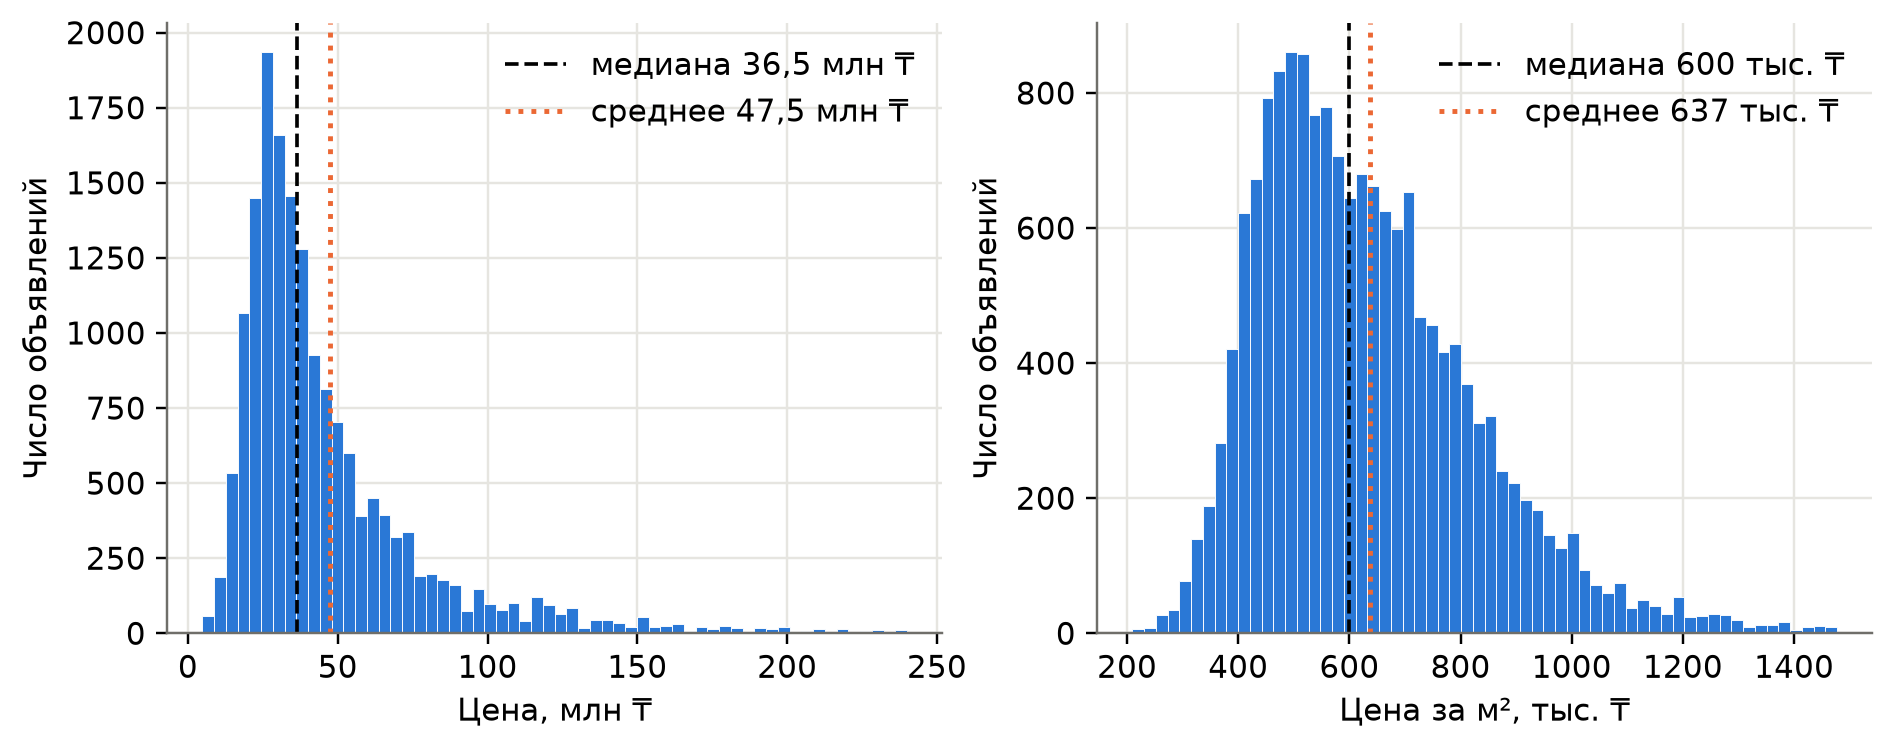

In [8]:
data["ppm2_k"] = data["price_per_m2_kzt"] / 1e3      # тыс. ₸ за м²
data["price_mln"] = data[C.TARGET] / 1e6
ppm2, price = data["ppm2_k"], data["price_mln"]


def describe(s):
    return {"n": int(s.size), "mean": s.mean(), "std": s.std(), "min": s.min(), "q05": s.quantile(0.05), "q25": s.quantile(0.25),
            "median": s.median(), "q75": s.quantile(0.75), "q95": s.quantile(0.95), "max": s.max(), "skew": float(stats.skew(s))}


eda_target = pd.DataFrame({"цена, млн ₸": describe(price), "цена за м², тыс. ₸": describe(ppm2),
                           "log(цены)": describe(np.log(data[C.TARGET]))}).T
save_csv(eda_target, "eda_target.csv", index=True)
table(eda_target, "Распределение цены и цены за м²", digits=2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, s, lab, unit, d in ((ax[0], price, "Цена, млн ₸", "млн ₸", 1), (ax[1], ppm2, "Цена за м², тыс. ₸", "тыс. ₸", 0)):
    a.hist(s, bins=60, range=(s.min(), s.quantile(0.995)), color=BLUE, edgecolor="white", linewidth=0.3)
    a.axvline(s.median(), color="black", ls="--", lw=1.2, label=f"медиана {ru(s.median(), d)} {unit}")
    a.axvline(s.mean(), color=ORANGE, ls=":", lw=1.6, label=f"среднее {ru(s.mean(), d)} {unit}")
    a.set(xlabel=lab, ylabel="Число объявлений")
    a.legend()
savefig("fig01_price_distribution", "Гистограммы цены и цены за м² (показаны значения до 99,5-го процентиля): распределение цены сильно скошено вправо "
        "(длинный хвост дорогих квартир), цена за м² ближе к симметричной; поэтому целевая переменная модели — логарифм цены.")

#### ▶ Цена по районам (район — по координатам)

,n,доля_%,цена_медиана_млн,ppm2_медиана_тыс,ppm2_q25_тыс,ppm2_q75_тыс,площадь_медиана,год_медиана
district,,,,,,,,
Есиль,3 903,23.3,50.0,714.3,593.1,872.0,72.0,2 021.0
Нура,4 981,29.7,39.7,679.5,563.8,796.5,62.3,2 023.0
Сарайшык,2 924,17.4,33.0,571.4,488.6,675.0,60.5,2 022.0
Алматы,2 023,12.1,30.0,496.7,429.5,585.0,63.5,2 012.0
Сарыарка,2 057,12.3,26.0,483.9,425.5,561.2,52.8,2 012.0
Байконур,891,5.3,31.0,455.6,401.3,513.4,66.5,2 008.0


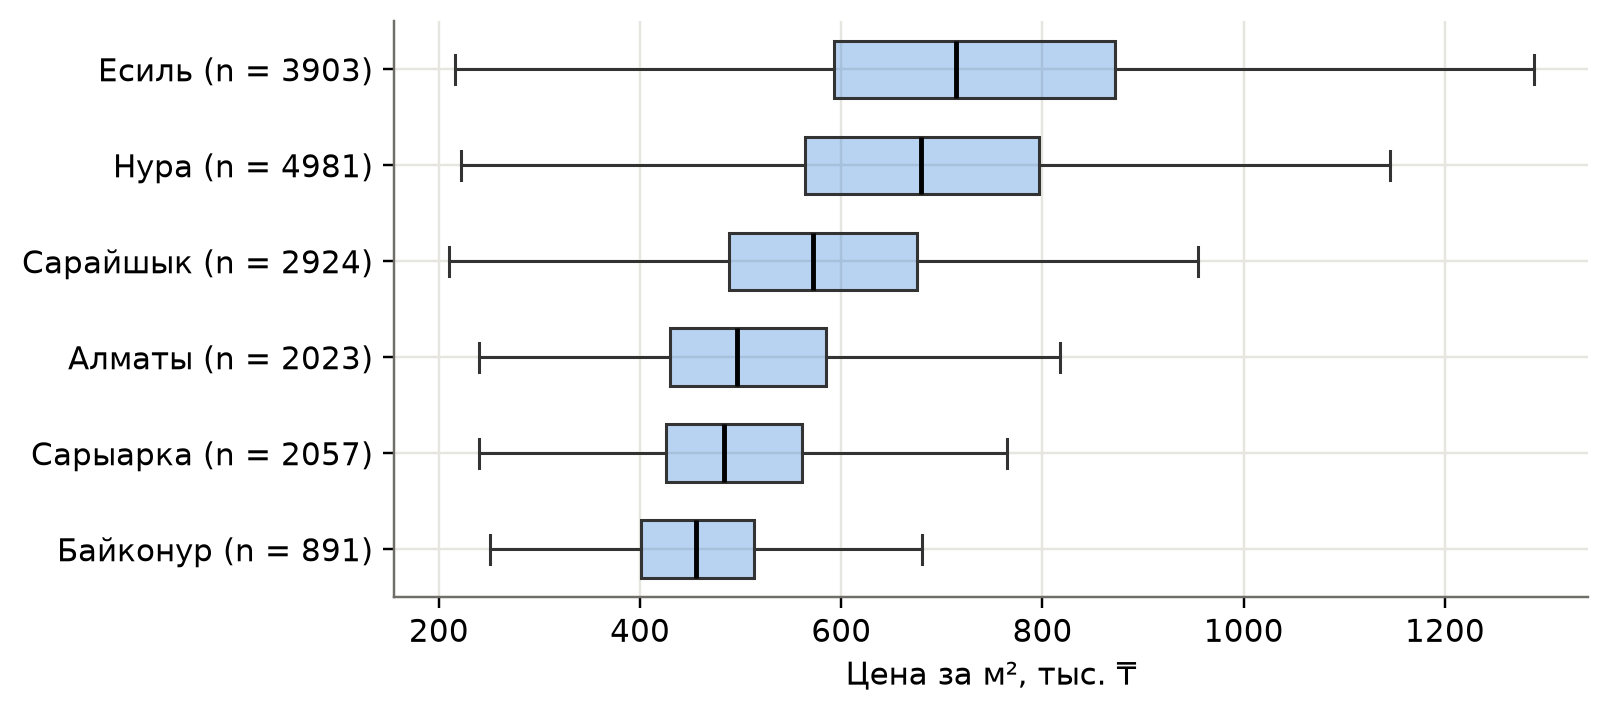

In [9]:
def group_stats(col, order=None):
    g = data.groupby(col, observed=True)
    out = pd.DataFrame({"n": g.size(), "доля_%": g.size() / len(data) * 100, "цена_медиана_млн": g["price_mln"].median(),
                        "ppm2_медиана_тыс": g["ppm2_k"].median(), "ppm2_q25_тыс": g["ppm2_k"].quantile(0.25),
                        "ppm2_q75_тыс": g["ppm2_k"].quantile(0.75), "площадь_медиана": g["area"].median(),
                        "год_медиана": g["year_built"].median()})
    return out.loc[order] if order is not None else out.sort_values("ppm2_медиана_тыс", ascending=False)


def boxes(ax, col, order, labels=None, color=BLUE):
    horiz = {"orientation": "horizontal"} if matplotlib.__version_info__ >= (3, 10) else {"vert": False}
    ax.boxplot([data.loc[data[col] == k, "ppm2_k"] for k in order], widths=0.6, showfliers=False, patch_artist=True, **horiz,
               boxprops=dict(facecolor=color + "55", edgecolor="#333"), medianprops=dict(color="black", lw=1.6),
               whiskerprops=dict(color="#333"), capprops=dict(color="#333"))
    ax.set_yticks(range(1, len(order) + 1), labels or order)
    ax.set_xlabel("Цена за м², тыс. ₸")
    ax.invert_yaxis()


eda_district = group_stats("district")
save_csv(eda_district, "eda_district.csv", index=True)
table(eda_district, "Цена по районам (район — по координатам)", digits=1, bars=["ppm2_медиана_тыс"])
fig, ax = plt.subplots(figsize=(7, 3.4))
boxes(ax, "district", list(eda_district.index), [f"{d} (n = {int(n)})" for d, n in eda_district["n"].items()])
savefig("fig02_price_per_m2_by_district", "Ящики с усами цены за м² по шести районам (усы — 1,5 межквартильного размаха, выбросы скрыты): "
        "левобережные Есиль и Нура заметно дороже правобережных Сарыарки и Байконура, но распределения перекрываются.")

#### ▶ Цена по типу дома

,n,доля_%,цена_медиана_млн,ppm2_медиана_тыс,ppm2_q25_тыс,ppm2_q75_тыс,площадь_медиана,год_медиана
house_type,,,,,,,,
монолитный,8 757,52.2,43.0,657.1,530.5,809.9,68.1,2 022.0
не указано,1 022,6.1,33.0,573.5,466.6,704.7,60.0,2 021.0
кирпичный,6 222,37.1,32.0,554.1,461.5,679.2,59.9,2 020.0
иной,209,1.2,32.0,517.6,433.5,649.4,60.2,2 017.0
панельный,569,3.4,22.8,447.5,391.3,512.2,50.0,1 987.0


#### ▶ Цена по периоду постройки

,n,доля_%,цена_медиана_млн,ppm2_медиана_тыс,ppm2_q25_тыс,ppm2_q75_тыс,площадь_медиана,год_медиана
year_period,,,,,,,,
до 1970,129,0.8,18.0,395.3,360.1,454.2,45.2,1 965.0
1970–1979,245,1.5,21.0,425.3,382.7,472.5,48.0,1 975.0
1980–1989,333,2.0,20.6,424.7,381.0,471.4,49.0,1 986.0
1990–1999,271,1.6,27.0,427.1,383.7,475.3,64.0,1 993.0
2000–2004,272,1.6,40.0,469.1,414.7,550.0,90.0,2 003.0
2005–2009,1 371,8.2,40.0,491.8,430.2,560.5,82.4,2 008.0
2010–2014,1 670,10.0,35.0,493.3,440.8,579.0,71.0,2 012.0
2015–2019,2 644,15.8,39.9,597.8,500.0,727.3,70.0,2 017.0
2020–2022,3 251,19.4,39.9,666.7,548.0,796.8,63.0,2 021.0


#### ▶ Цена по числу комнат

,n,доля_%,цена_медиана_млн,ppm2_медиана_тыс,ppm2_q25_тыс,ppm2_q75_тыс,площадь_медиана,год_медиана
rooms,,,,,,,,
1,3 889,23.2,23.0,585.6,498.6,686.3,39.0,2 022.0
2,6 101,36.4,34.0,601.0,490.4,750.0,57.2,2 021.0
3,4 866,29.0,51.0,583.9,467.1,750.0,87.8,2 020.0
4,1 622,9.7,86.0,693.5,510.3,884.6,126.8,2 019.0
5,269,1.6,139.9,755.8,517.7,1 033.3,191.6,2 017.0
6,32,0.2,140.0,642.4,487.0,872.1,220.0,2 014.0


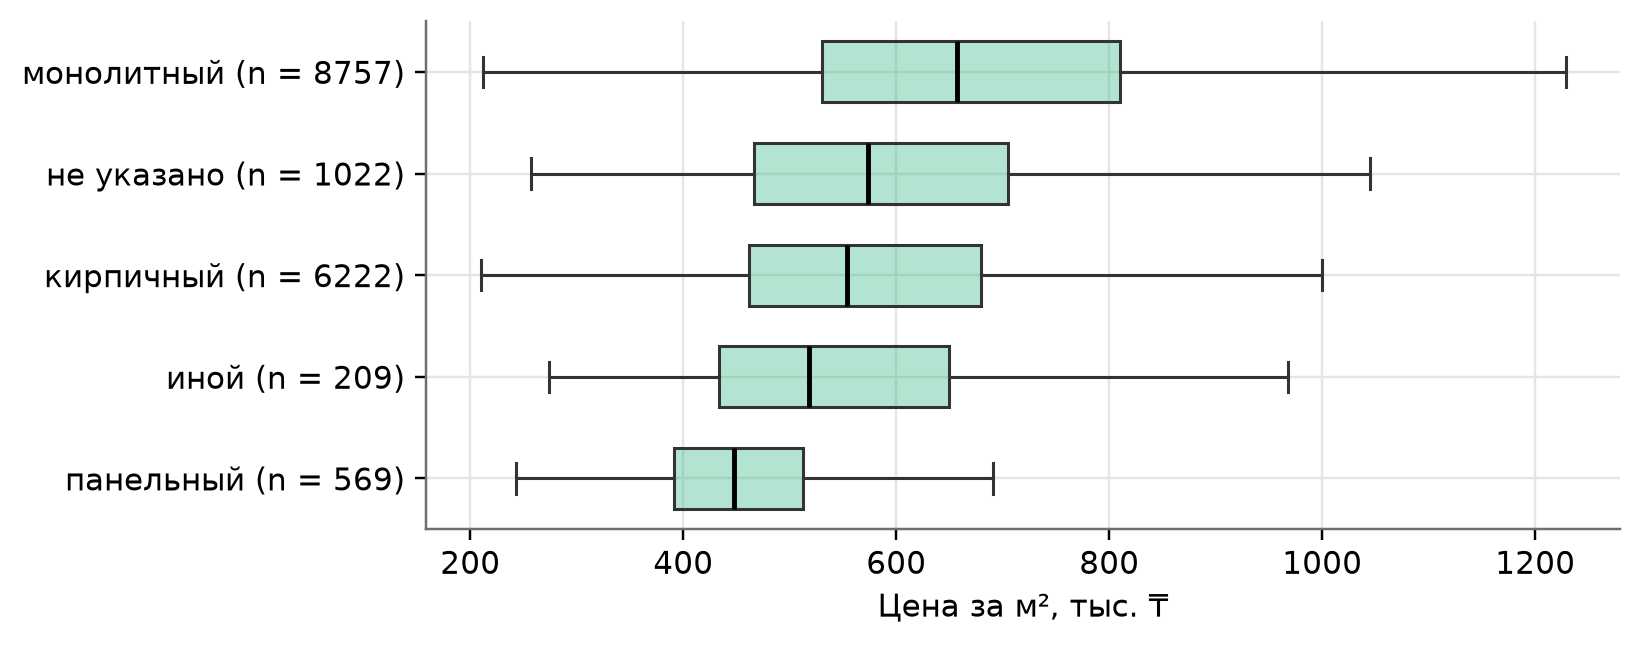

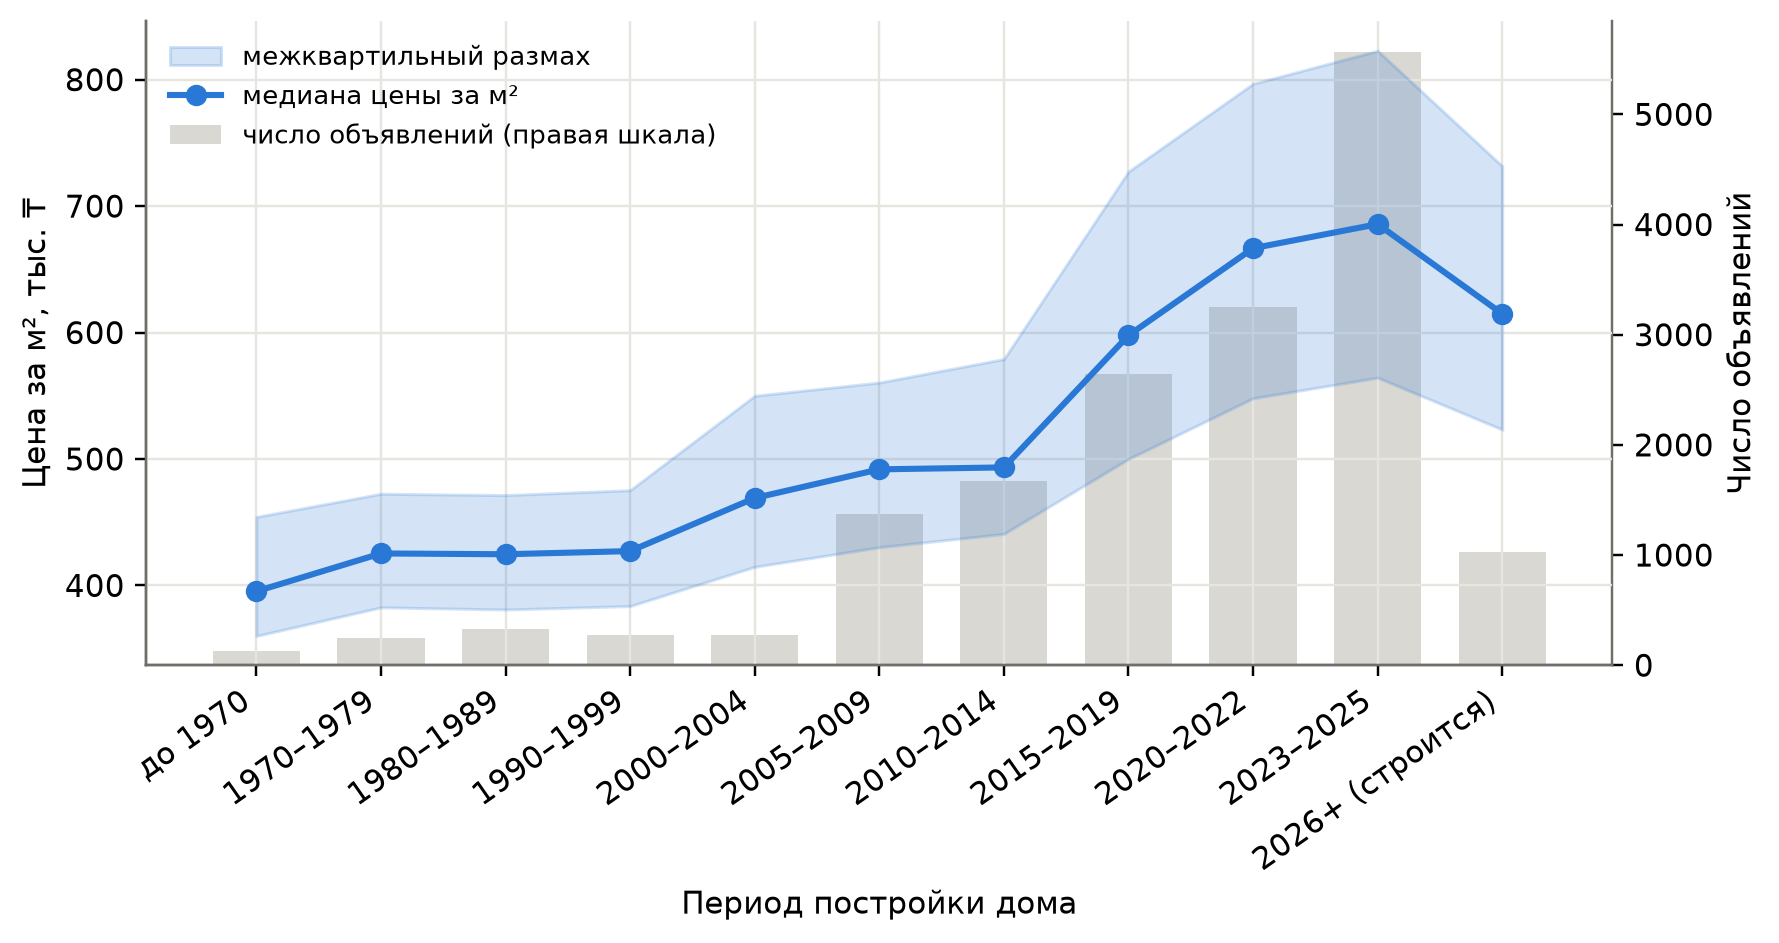

In [10]:
eda_house = group_stats("house_type")
save_csv(eda_house, "eda_house_type.csv", index=True)
data["year_period"] = pd.cut(data["year_built"], [0, 1969, 1979, 1989, 1999, 2004, 2009, 2014, 2019, 2022, 2025, 9999],
                             labels=["до 1970", "1970–1979", "1980–1989", "1990–1999", "2000–2004", "2005–2009", "2010–2014",
                                     "2015–2019", "2020–2022", "2023–2025", "2026+ (строится)"])
eda_year = group_stats("year_period", order=list(data["year_period"].cat.categories))
save_csv(eda_year, "eda_year_built.csv", index=True)
eda_rooms = group_stats("rooms", order=sorted(data["rooms"].unique()))
save_csv(eda_rooms, "eda_rooms.csv", index=True)
table(eda_house, "Цена по типу дома", digits=1, bars=["ppm2_медиана_тыс"])
table(eda_year, "Цена по периоду постройки", digits=1, bars=["ppm2_медиана_тыс"])
table(eda_rooms, "Цена по числу комнат", digits=1)

fig, ax = plt.subplots(figsize=(7, 3.0))
boxes(ax, "house_type", list(eda_house.index), [f"{d} (n = {int(n)})" for d, n in eda_house["n"].items()], color=TEAL)
savefig("fig03_price_per_m2_by_house_type", "Цена за м² по типу дома: монолитные дома дороже кирпичных, панельные — самые дешёвые; "
        "объявления без указания типа дома по цене близки к кирпичным.")

fig, ax = plt.subplots(figsize=(8.6, 3.8))
x = np.arange(len(eda_year))
axn = ax.twinx()                                     # число объявлений — правая шкала, позади линии
axn.bar(x, eda_year["n"], color="#d9d8d3", width=0.7, label="число объявлений (правая шкала)")
axn.set_ylabel("Число объявлений")
axn.grid(False)
axn.spines["right"].set_visible(True)
ax.set_zorder(axn.get_zorder() + 1)
ax.patch.set_visible(False)
ax.fill_between(x, eda_year["ppm2_q25_тыс"], eda_year["ppm2_q75_тыс"], color=BLUE, alpha=0.2, label="межквартильный размах")
ax.plot(x, eda_year["ppm2_медиана_тыс"], color=BLUE, marker="o", lw=2, label="медиана цены за м²")
ax.set(ylabel="Цена за м², тыс. ₸", xlabel="Период постройки дома")
ax.set_xticks(x, eda_year.index, rotation=35, ha="right")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axn.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8.5)
savefig("fig04_price_per_m2_by_year", "Медиана и межквартильный размах цены за м² по периодам постройки (левая шкала) и число объявлений (столбцы, правая шкала): "
        "цена за м² растёт от старого фонда к домам 2023–2025 годов и ниже у строящихся домов; больше всего объявлений — о квартирах в домах 2020–2025 годов.")

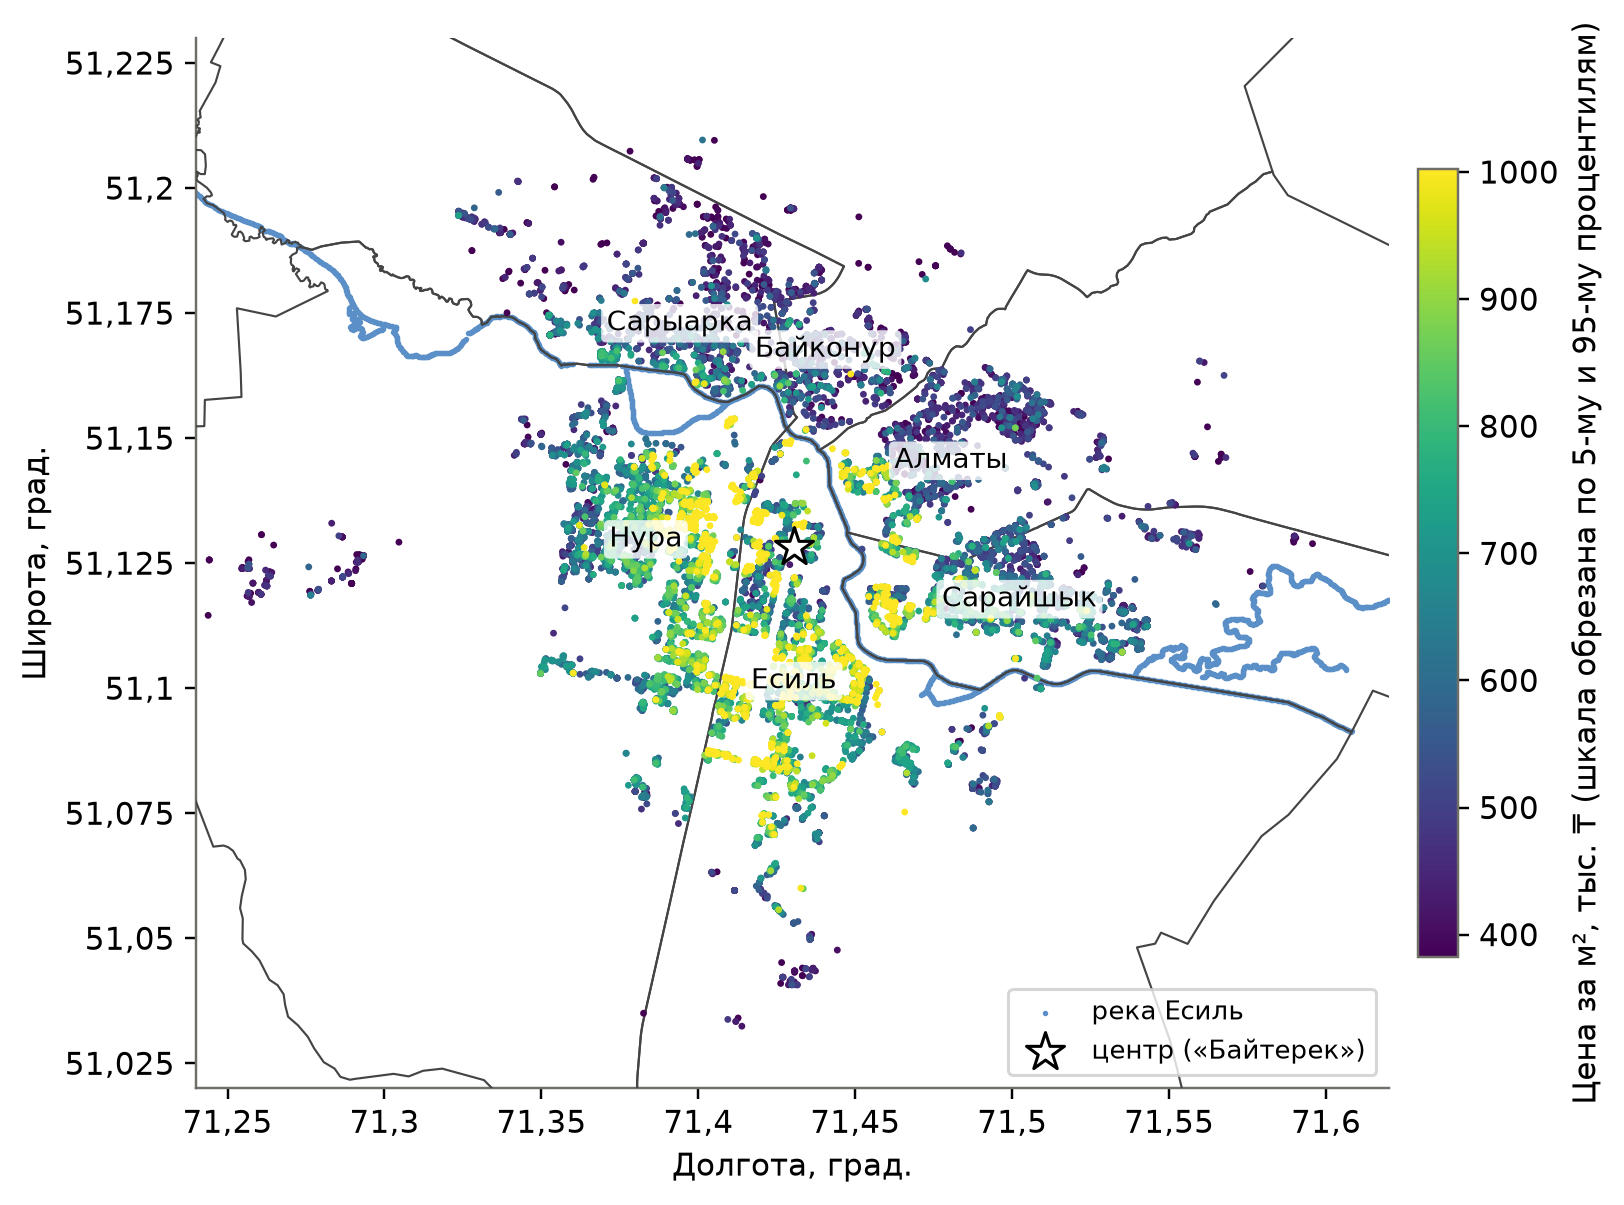

In [11]:
def city_map(ax, boundaries=True, river=True, center=True):
    """Общая подложка карт: границы районов, русло Есиля, центр."""
    if boundaries:
        for d, rings in geo.districts.items():
            for r in rings:
                ax.plot(r[:, 1], r[:, 0], color="#444", lw=0.7, zorder=3)
    if river:
        ax.scatter(geo.river_pts[:, 1], geo.river_pts[:, 0], s=0.6, color="#5b8fc7", zorder=2, label="река Есиль")
    if center:
        ax.scatter([C.CENTER[1]], [C.CENTER[0]], marker="*", s=170, color="white", edgecolor="black", zorder=6, label="центр («Байтерек»)")
    ax.set(xlim=(71.24, 71.62), ylim=(51.02, 51.23), xlabel="Долгота, град.", ylabel="Широта, град.")
    ax.set_aspect(1 / np.cos(np.radians(V.LAT0)))
    ax.grid(False)
    ru_ticks(ax)


fig, ax = plt.subplots(figsize=(8.6, 6.2))
lo, hi = ppm2.quantile([0.05, 0.95])
order = np.argsort(ppm2.to_numpy())
sc = ax.scatter(data["longitude"].to_numpy()[order], data["latitude"].to_numpy()[order], c=ppm2.to_numpy()[order], s=5, vmin=lo, vmax=hi,
                cmap="viridis", zorder=4, linewidths=0)
city_map(ax)
for d, (la, lo_) in data.groupby("district")[["latitude", "longitude"]].median().iterrows():
    ax.annotate(d, (lo_, la), fontsize=9, ha="center", zorder=7, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
cb = fig.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
cb.set_label("Цена за м², тыс. ₸ (шкала обрезана по 5-му и 95-му процентилям)")
ax.legend(loc="lower right", fontsize=8.5, frameon=True, markerscale=1.0)
in_view = float((data["longitude"].between(71.24, 71.62) & data["latitude"].between(51.02, 51.23)).mean())
savefig("fig05_map_price_per_m2", "Карта объявлений, цвет — цена за м² (светлее — дороже), линии — границы районов по OSM: "
        "дорогие квартиры сосредоточены на левом берегу вокруг центра и вдоль Есиля, цена убывает к окраинам.")

#### ▶ Корреляция Спирмена числовых признаков с ценой и ценой за м² (20 сильнейших по цене за м²)

,rho_цена,rho_цена_за_м2,группа,подпись
ceiling_height,0.485,0.530,объектные,Высота потолков
dist_center_km,-0.570,-0.493,геоинфраструктурные,"До центра, км"
latitude,-0.262,-0.436,локационные,Широта
year_built,0.083,0.416,объектные,Год постройки
in_complex,0.282,0.337,объектные,Указан ЖК
dist_park_km,-0.411,-0.292,геоинфраструктурные,"До парка, км"
sec_videointercom,0.204,0.291,объектные,Видеодомофон
sec_guard,0.202,0.241,объектные,Охрана
n_university_500m,-0.087,-0.220,геоинфраструктурные,Вузов в 500 м
n_park_1km,0.374,0.219,геоинфраструктурные,Парков в 1 км


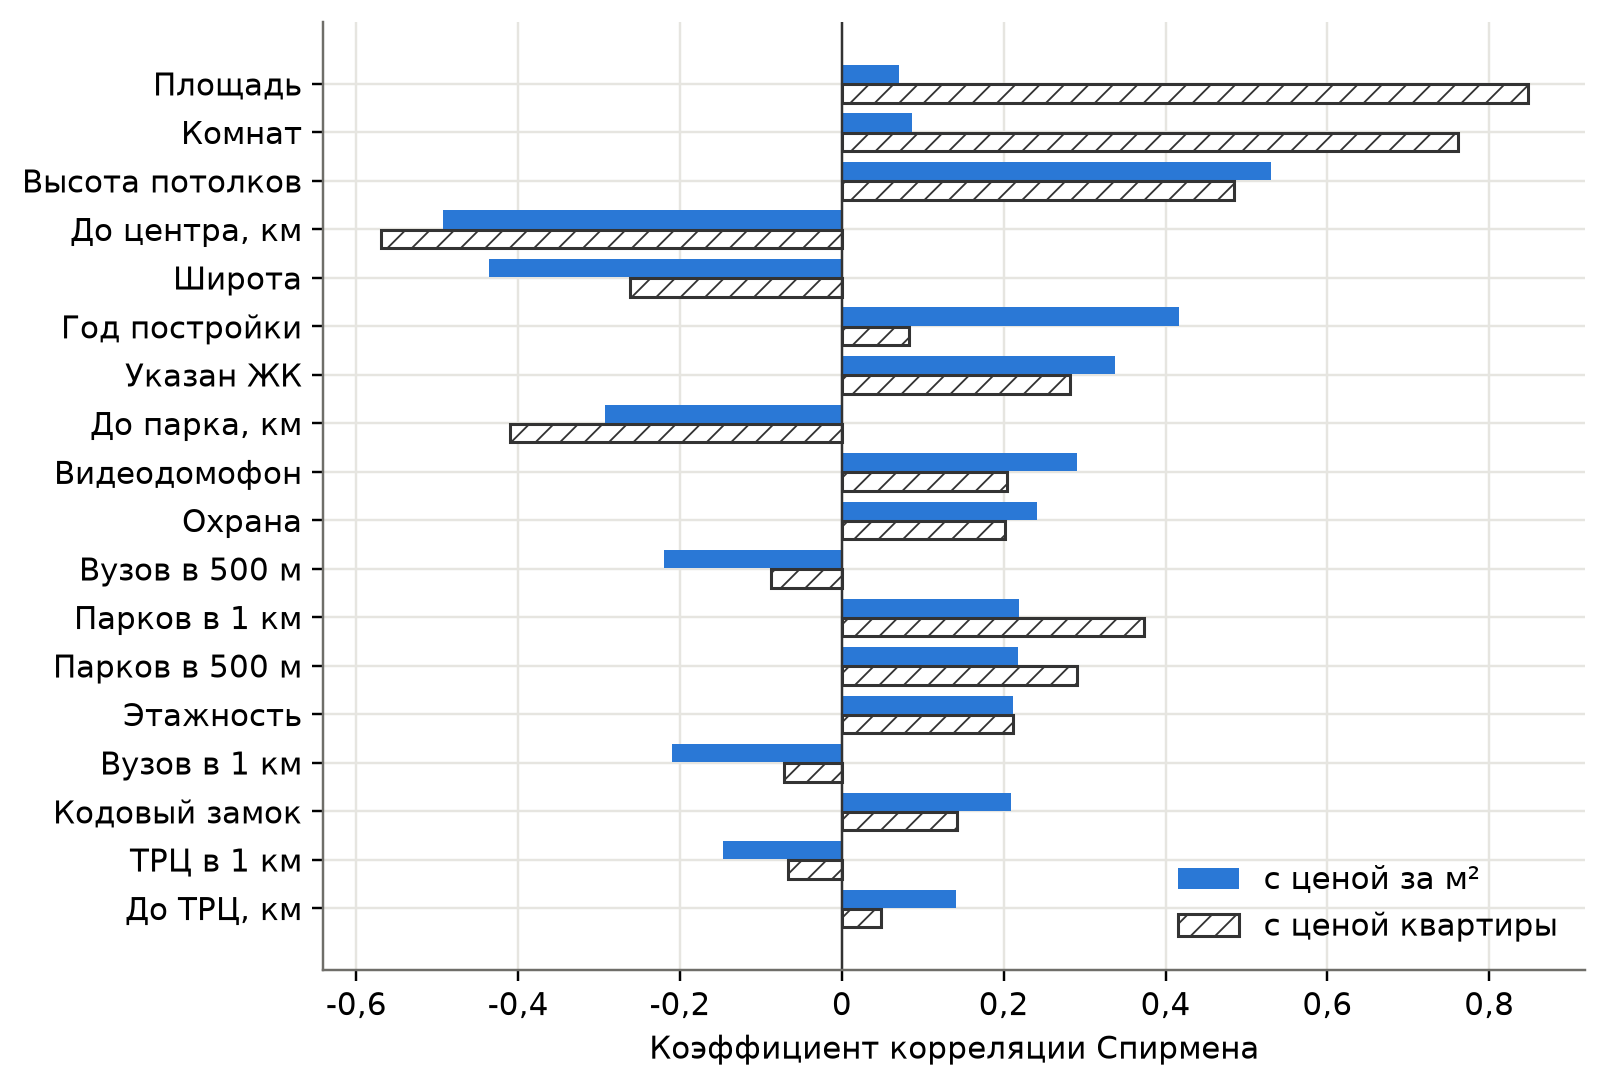

In [12]:
num_cols = [f for f in F.FEATURE_SETS["E"] if f not in F.CATEGORICAL]
eda_corr = pd.DataFrame({
    "rho_цена": data[num_cols].corrwith(data[C.TARGET], method="spearman"),
    "rho_цена_за_м2": data[num_cols].corrwith(data["price_per_m2_kzt"], method="spearman"),
})
eda_corr["группа"] = [F.group_of(f) for f in eda_corr.index]
eda_corr["подпись"] = [F.SHORT[f] for f in eda_corr.index]
eda_corr = eda_corr.reindex(eda_corr["rho_цена_за_м2"].abs().sort_values(ascending=False).index)
save_csv(eda_corr, "eda_correlations.csv", index=True)
table(eda_corr.head(20), "Корреляция Спирмена числовых признаков с ценой и ценой за м² (20 сильнейших по цене за м²)")

top = pd.concat([eda_corr.loc[["area", "rooms"]], eda_corr.drop(index=["area", "rooms"]).head(16)])[::-1]
fig, ax = plt.subplots(figsize=(7.4, 5.6))
yy = np.arange(len(top))
ax.barh(yy + 0.2, top["rho_цена_за_м2"], height=0.38, color=BLUE, label="с ценой за м²")
ax.barh(yy - 0.2, top["rho_цена"], height=0.38, color="white", edgecolor="#333", hatch="///", label="с ценой квартиры")
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(yy, top["подпись"])
ax.set_xlabel("Коэффициент корреляции Спирмена")
ax.legend(loc="lower right")
ru_ticks(ax, "x")
savefig("fig06_correlations", "Корреляция Спирмена признаков с ценой квартиры и с ценой за м²: цена квартиры определяется площадью и числом комнат, "
        "а цена за м² — годом постройки, высотой потолков, этажностью и положением (расстояние до центра, окружение).")

#### ▶ Цена за м² и расстояние до центра · ρ Спирмена = -0.493; в среднем -7.5 % на километр

,n,ppm2_медиана_тыс,ppm2_q25_тыс,ppm2_q75_тыс,цена_медиана_млн
center_bin,,,,,
0–1,475,649.4,523.7,984.1,65.0
1–2,927,686.3,555.2,891.6,55.5
2–3,2 341,794.1,652.8,920.7,58.0
3–4,3 830,689.5,558.8,800.0,43.5
4–5,3 285,569.8,482.1,695.1,35.8
5–6,2 941,532.3,456.5,633.3,28.0
6–7,1 486,520.0,446.3,622.0,26.8
7–8,893,500.0,430.0,565.0,24.0
8–9,266,451.9,397.4,513.8,22.5


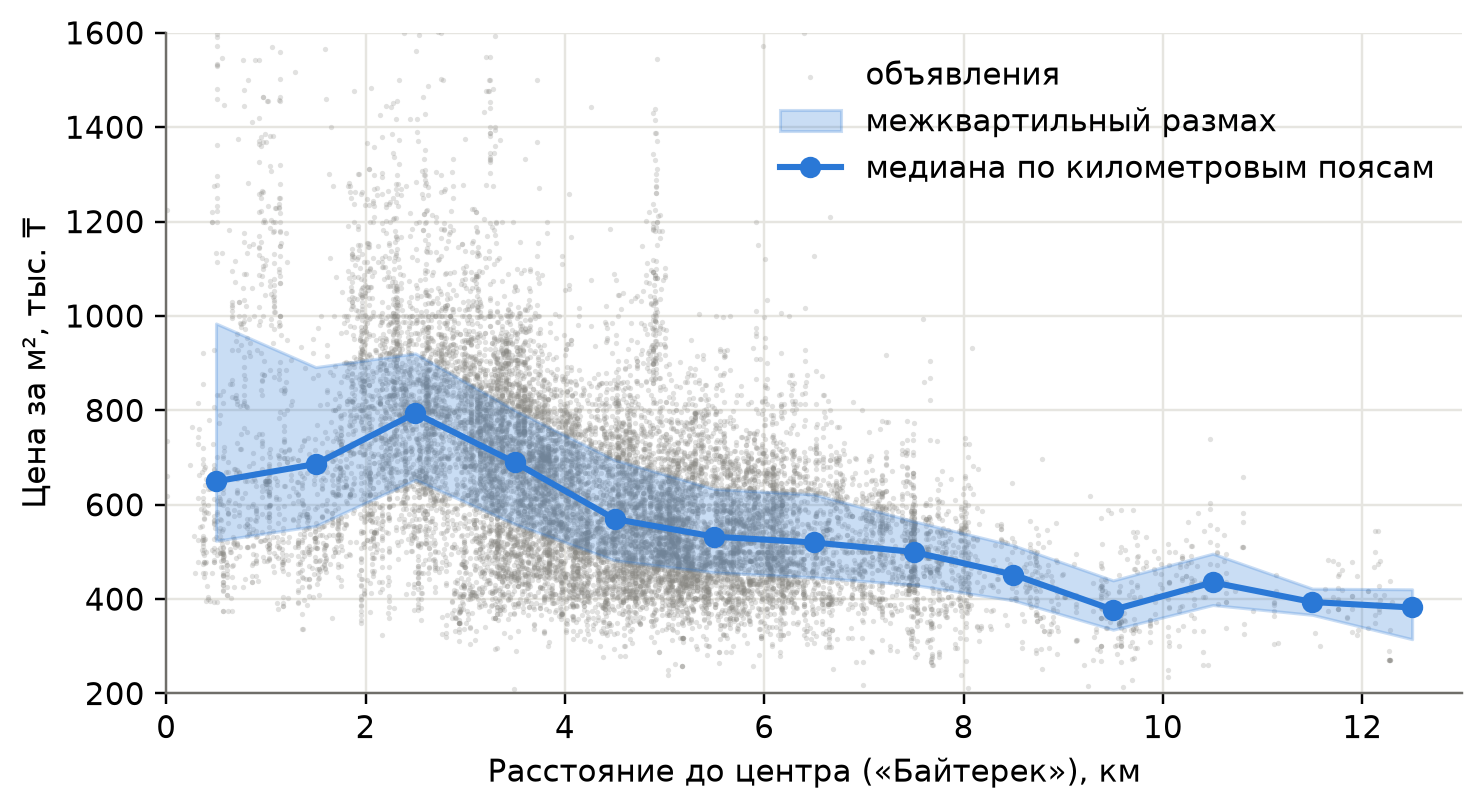

In [13]:
bins = np.arange(0, 12.5, 1.0)
data["center_bin"] = pd.cut(data["dist_center_km"], list(bins) + [np.inf], right=False,
                            labels=[f"{int(a)}–{int(a) + 1}" for a in bins[:-1]] + ["12+"])
eda_center = data.groupby("center_bin", observed=True).agg(n=("ppm2_k", "size"), ppm2_медиана_тыс=("ppm2_k", "median"),
                                                          ppm2_q25_тыс=("ppm2_k", lambda s: s.quantile(0.25)),
                                                          ppm2_q75_тыс=("ppm2_k", lambda s: s.quantile(0.75)),
                                                          цена_медиана_млн=("price_mln", "median"))
save_csv(eda_center, "eda_center_distance.csv", index=True)
rho_center = stats.spearmanr(data["dist_center_km"], data["ppm2_k"])
slope = stats.linregress(data["dist_center_km"], np.log(data["price_per_m2_kzt"]))
center_stats = {"spearman_rho_ppm2": float(rho_center.statistic), "spearman_p": float(rho_center.pvalue),
                "log_ppm2_slope_per_km": float(slope.slope), "ppm2_change_per_km_%": float(np.expm1(slope.slope) * 100),
                "r2_linear_log_ppm2": float(slope.rvalue ** 2), "share_within_5km_%": float((data["dist_center_km"] <= 5).mean() * 100),
                "share_within_10km_%": float((data["dist_center_km"] <= 10).mean() * 100),
                "dist_center_median_km": float(data["dist_center_km"].median())}
table(eda_center, f"Цена за м² и расстояние до центра · ρ Спирмена = {rho_center.statistic:.3f}; в среднем {center_stats['ppm2_change_per_km_%']:+.1f} % на километр", digits=1)

fig, ax = plt.subplots(figsize=(7.6, 3.9))
m = data["dist_center_km"] <= 13
ax.scatter(data.loc[m, "dist_center_km"], data.loc[m, "ppm2_k"], s=3, color=GRAY, alpha=0.25, linewidths=0, label="объявления")
xc = np.arange(len(eda_center)) + 0.5
ax.fill_between(xc, eda_center["ppm2_q25_тыс"], eda_center["ppm2_q75_тыс"], color=BLUE, alpha=0.25, label="межквартильный размах")
ax.plot(xc, eda_center["ppm2_медиана_тыс"], color=BLUE, marker="o", lw=2, label="медиана по километровым поясам")
ax.set(xlabel="Расстояние до центра («Байтерек»), км", ylabel="Цена за м², тыс. ₸", ylim=(200, 1600), xlim=(0, 13))
ax.legend(loc="upper right")
savefig("fig07_price_vs_center_distance", "Цена за м² против расстояния до центра: медиана максимальна в поясе 2–3 км от «Байтерека» и убывает к окраинам, "
        "но разброс внутри каждого километрового пояса велик — одного расстояния для прогноза недостаточно.")

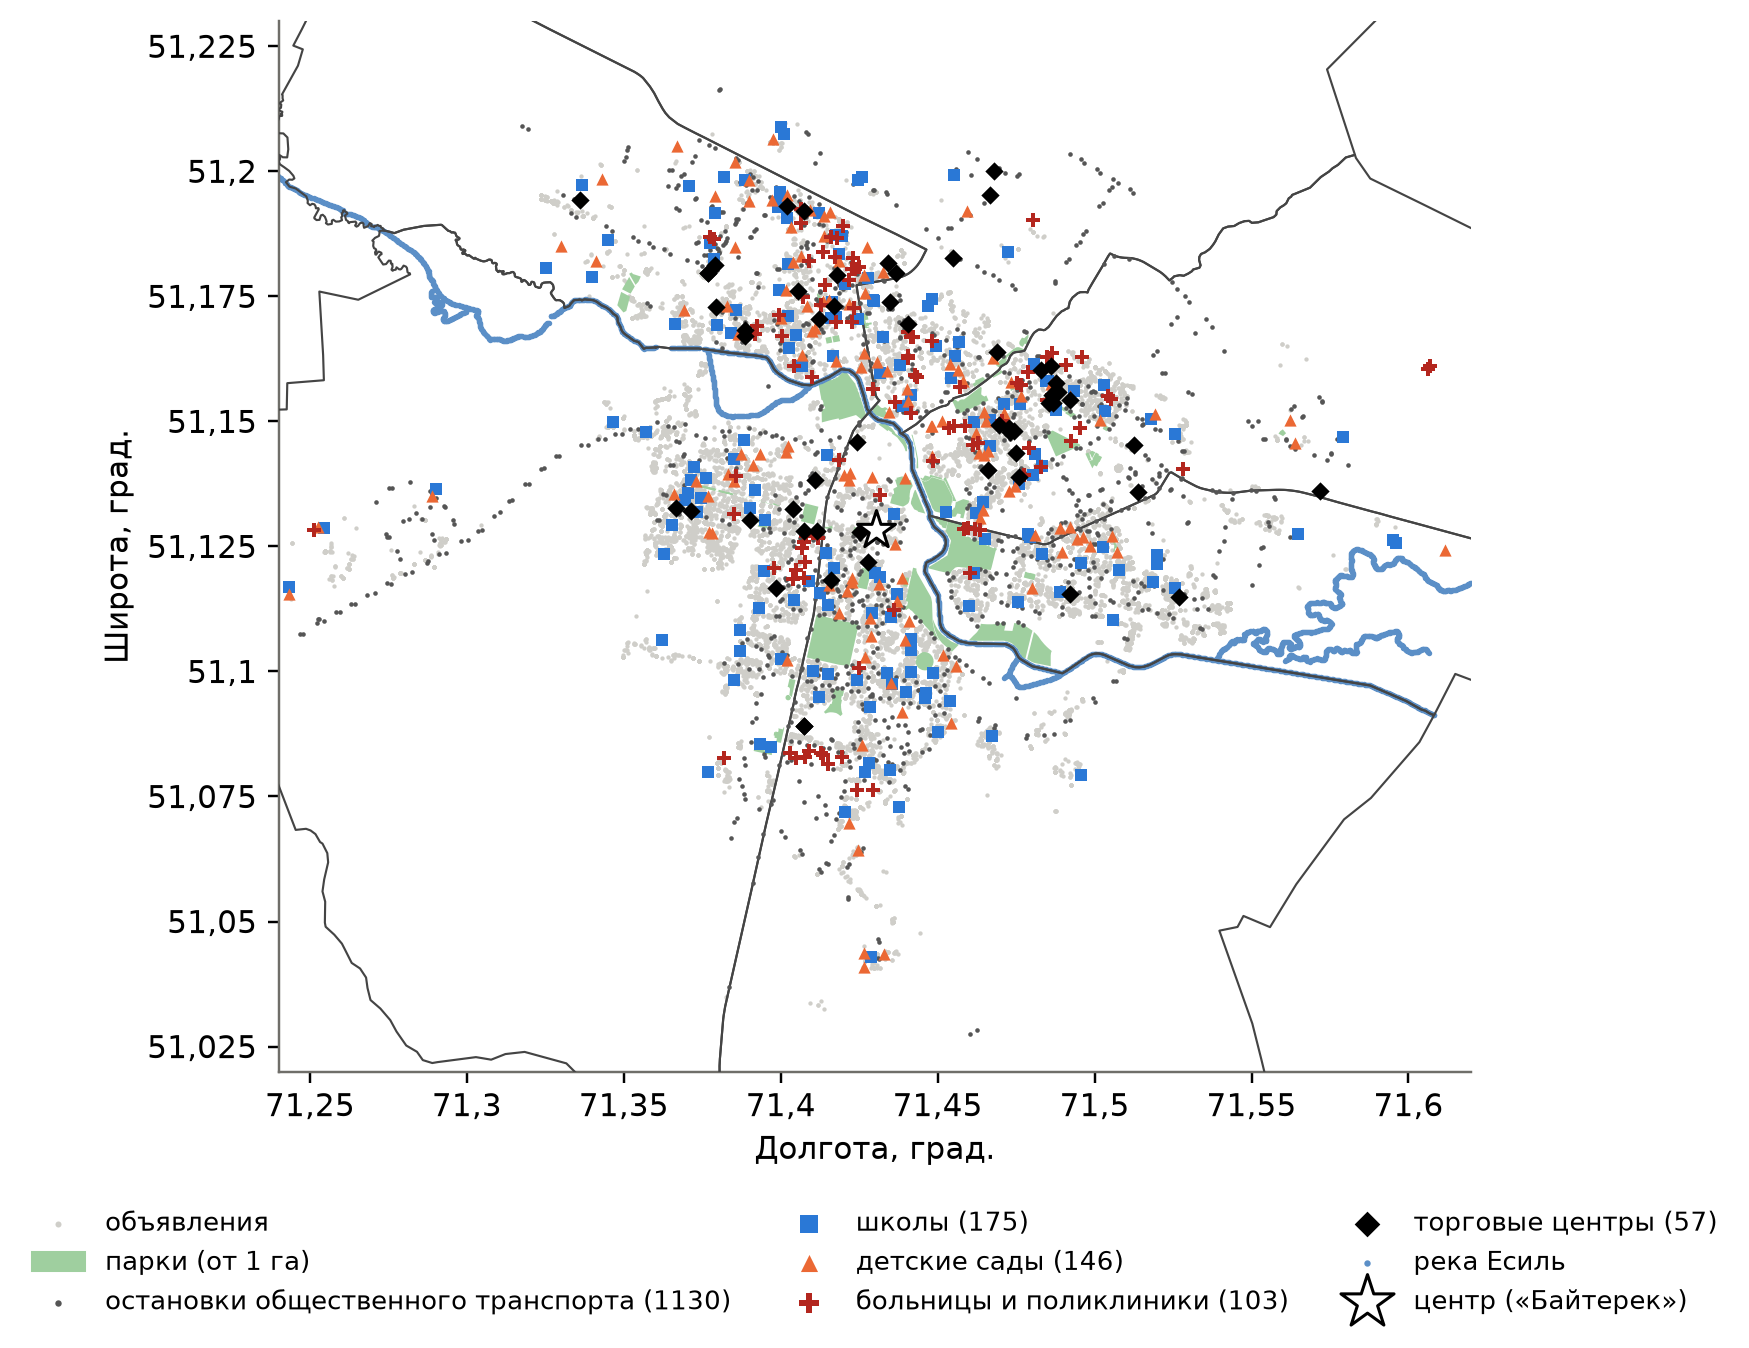

In [14]:
fig, ax = plt.subplots(figsize=(8.6, 6.2))
ax.scatter(data["longitude"], data["latitude"], s=2, color="#cfcec9", linewidths=0, zorder=1, label="объявления")
for i in np.unique(geo.park_ids):
    p = geo.park_pts[geo.park_ids == i]
    ax.fill(p[:, 1], p[:, 0], color="#9fcf9f", zorder=2, lw=0)
ax.fill([], [], color="#9fcf9f", label="парки (от 1 га)")
for layer, mk, col, s in (("bus_stop", ".", "#555555", 9), ("school", "s", BLUE, 16), ("kindergarten", "^", ORANGE, 16),
                          ("healthcare", "P", "#b3261e", 22), ("mall", "D", "black", 18)):
    p = geo.points[layer]
    ax.scatter(p[:, 1], p[:, 0], marker=mk, s=s, color=col, linewidths=0, zorder=4, label=f"{osm.LAYERS[layer][0]} ({len(p)})")
city_map(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), fontsize=8.5, ncols=3, markerscale=1.4)
savefig("fig08_osm_objects_map", "Объекты OpenStreetMap, по которым считаются геопризнаки (остановки, школы, детские сады, больницы, торговые центры, парки, русло Есиля), "
        "на фоне объявлений: покрытие плотное в застроенной части города и редкое на окраинах.")

data_summary = {
    "rows_raw": len(raw), "rows_clean": len(data), "rows_removed": len(raw) - len(data),
    "rows_removed_%": (len(raw) - len(data)) / len(raw) * 100, "rows_kept_%": len(data) / len(raw) * 100,
    "duplicates_exact": int(journal.loc[2, "удалено_строк"]), "duplicates_same_object": int(journal.loc[3, "удалено_строк"]),
    "duplicates_total": int(journal.loc[[2, 3], "удалено_строк"].sum()),
    "duplicates_total_%": float(journal.loc[[2, 3], "удалено_строк"].sum() / len(raw) * 100),
    "outside_city": int(journal.loc[journal["этап"] == "география", "удалено_строк"].sum()),
    "outliers_removed": int(journal.loc[journal["этап"] == "выбросы", "удалено_строк"].sum()),
    "under_construction": int(data["under_construction"].sum()), "under_construction_%": float(data["under_construction"].mean() * 100),
    "district_agreement_%": district_agreement * 100, "district_relabelled": int(journal.loc[journal["действие"].str.startswith("метка района"), "изменено_значений"].iloc[0]),
    "district_filled": int(journal.loc[journal["действие"].str.startswith("пропуск района"), "изменено_значений"].iloc[0]),
    "unique_coordinates": int(data.groupby(["latitude", "longitude"]).ngroups), "unique_complexes": int(data.loc[data["in_complex"] == 1, "residential_complex_name"].nunique()),
    "in_complex_%": float(data["in_complex"].mean() * 100), "features_total": len(fdict), "features_object": len(F.OBJECT),
    "features_location": len(F.DISTRICT + F.COORDS), "features_geo": len(GEO_FEATURES), "map_view_share_%": in_view * 100,
    "price_median_mln": float(price.median()), "price_mean_mln": float(price.mean()), "ppm2_median_k": float(ppm2.median()),
    "ppm2_mean_k": float(ppm2.mean()), "area_median": float(data["area"].median()), "year_median": float(data["year_built"].median()),
    "district_ppm2_max_to_min": float(eda_district["ppm2_медиана_тыс"].max() / eda_district["ppm2_медиана_тыс"].min()),
    "geo_features_time_s": geo_time, "center_distance": center_stats, "bounds": {
        "area": [C.AREA_MIN, C.AREA_MAX], "rooms_max": C.ROOMS_MAX, "ppm2": [C.PPM2_MIN, C.PPM2_MAX], "ceiling": [C.CEIL_MIN, C.CEIL_MAX]},
}

## 7. Разбиение и схемы проверки · `шаг 5`
Отложенный тест — 20 % (seed 42, стратификация по району). Подбор гиперпараметров, перекрёстная и пространственная проверка, абляция идут только на обучающей части; тест используется один раз для итоговых оценок.

#### ▶ Схемы проверки · у 59.7 % тестовых объявлений дом (координаты) встречается в обучении

,фолдов,обучение,проверка,что проверяет
схема,,,,
отложенный тест,1,13 423,3 356,итоговая оценка на новых объявлениях
перекрёстная 5 × 3,15,10 738,2 685,"устойчивость оценки, парные сравнения"
"пространственная, 5 фолдов по ячейкам 2 × 2 км",5,10 738,2 685,"перенос на места, которых не было в обучении (для сравнения D и E — две сетки ячеек, исходная и сдвинутая на 1 км: 10 фолдов)"
5 районов → 6-й,6,11 186,2 237,перенос на целый новый район


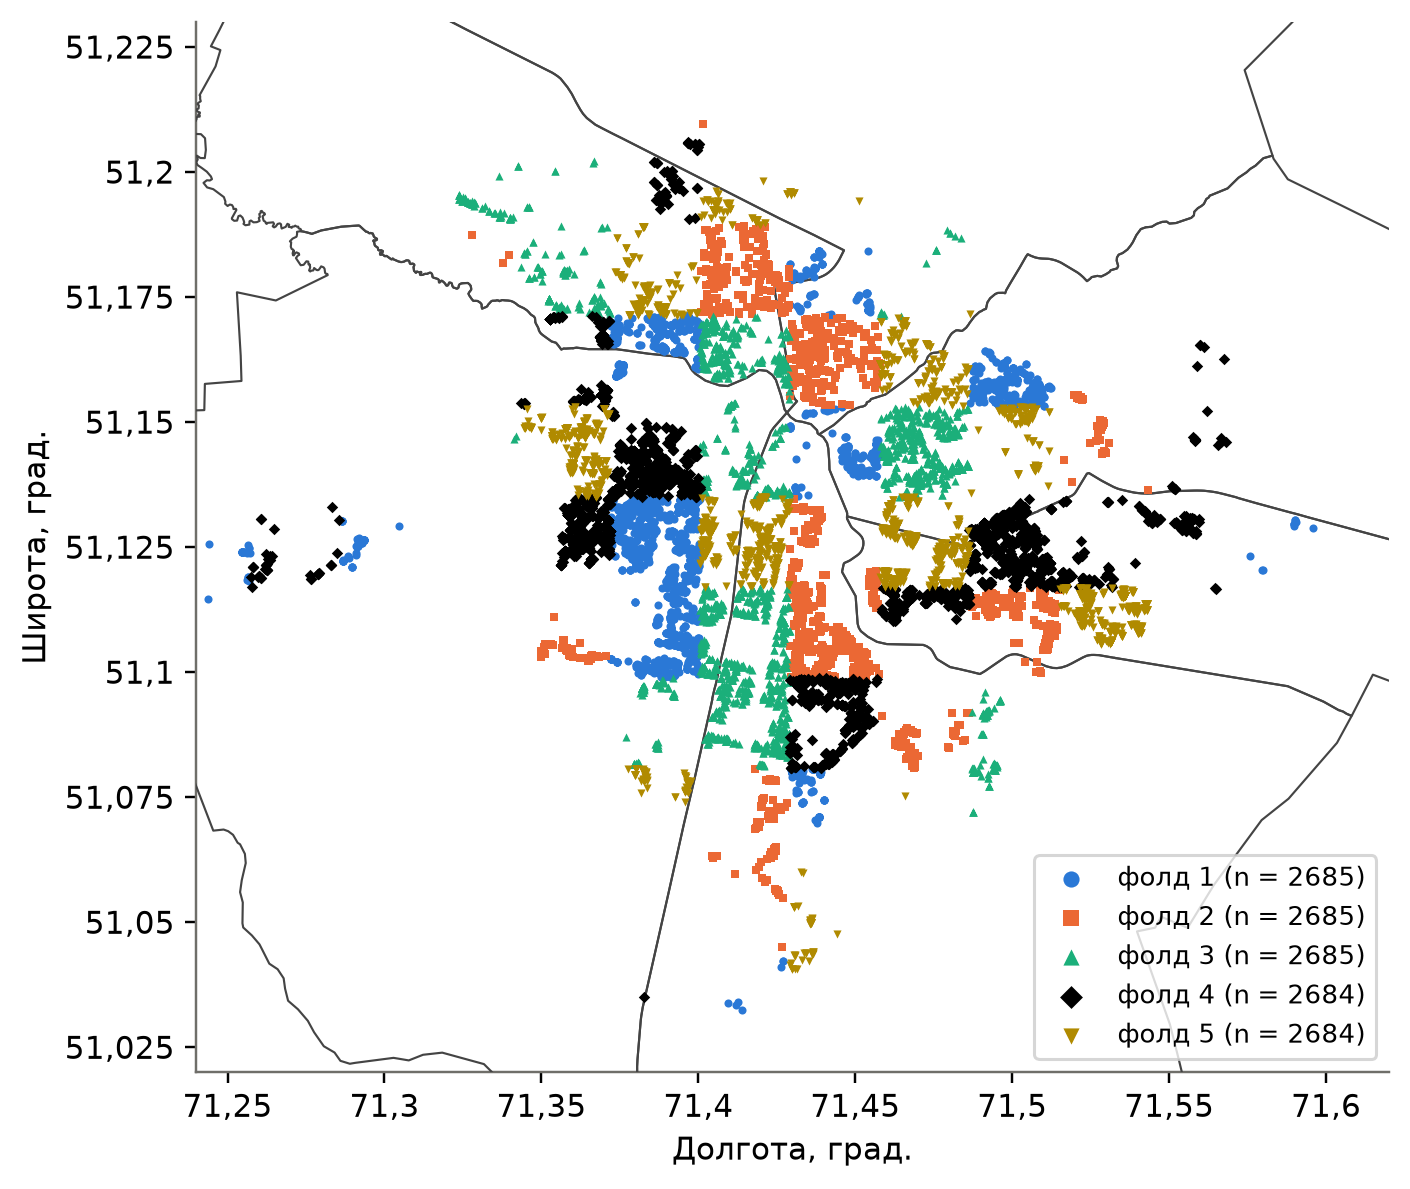

In [15]:
from sklearn.neighbors import BallTree

tr_idx, te_idx = V.holdout_split(data)
train, test = data.iloc[tr_idx].reset_index(drop=True), data.iloc[te_idx].reset_index(drop=True)
y_train, y_test = train[C.TARGET].to_numpy(float), test[C.TARGET].to_numpy(float)
pd.DataFrame({"listing_id": data["listing_id"], "part": np.where(np.isin(np.arange(len(data)), te_idx), "test", "train")}).to_csv(C.PROCESSED / "holdout_split.csv", index=False)

cv_splits = V.repeated_splits(len(train), 5, 3)                                    # 5 фолдов × 3 повтора
cells = V.spatial_cells(train["latitude"], train["longitude"])                     # ячейки 2 × 2 км
sp_splits = V.spatial_splits(cells, 5, SEED)                                       # ячейка целиком в одном фолде
cells2 = V.spatial_cells(train["latitude"], train["longitude"], shift_km=V.CELL_KM / 2)   # вторая сетка: сдвиг на полячейки (1 км)
sp_splits2 = V.spatial_splits(cells2, 5, SEED)                                     # второе разбиение — для главного сравнения D и E
lodo_splits = V.group_splits(train["district"])                                    # 5 районов -> 6-й


def near_train_share(splits, radius_m=300):
    """Доля проверочных объявлений фолда, у которых ближайшее обучающее ближе radius_m: блоки без буферной зоны."""
    xy = np.radians(train[["latitude", "longitude"]].to_numpy(float))
    out = []
    for tr, te in splits:
        dist, _ = BallTree(xy[tr], metric="haversine").query(xy[te], k=1)
        out.append(float((dist[:, 0] * 6371000 < radius_m).mean() * 100))
    return out


near_train = near_train_share(sp_splits) + near_train_share(sp_splits2)
SPLITS = {"cv": cv_splits, "cv5": cv_splits[:5], "spatial": sp_splits, "spatial2": sp_splits2, "lodo": lodo_splits}

train_xy = set(zip(train["latitude"], train["longitude"]))
seen_house = np.array([(a, b) in train_xy for a, b in zip(test["latitude"], test["longitude"])])
split_info = {
    "seed": SEED, "n_train": len(train), "n_test": len(test), "test_share_%": len(test) / len(data) * 100,
    "cv_folds": len(cv_splits), "cv_n_splits": 5, "cv_n_repeats": 3, "cv_fold_test_mean": float(np.mean([len(s[1]) for s in cv_splits])),
    "cv_fold_train_mean": float(np.mean([len(s[0]) for s in cv_splits])),
    "spatial_cell_km": V.CELL_KM, "spatial_cells": int(len(np.unique(cells))), "spatial_folds": len(sp_splits),
    "spatial_folds_D_vs_E": len(sp_splits) + len(sp_splits2), "spatial_shift_km": V.CELL_KM / 2, "spatial_cells_shifted": int(len(np.unique(cells2))),
    "spatial2_same_fold_share_%": V.split_agreement(sp_splits, sp_splits2) * 100,
    "spatial_fold_train_mean": float(np.mean([len(s[0]) for s in sp_splits + sp_splits2])), "spatial_fold_test_mean": float(np.mean([len(s[1]) for s in sp_splits + sp_splits2])),
    "spatial_test_within_300m_of_train_%_min": float(min(near_train)), "spatial_test_within_300m_of_train_%_max": float(max(near_train)),
    "spatial_test_within_300m_of_train_%_mean": float(np.mean(near_train)),   # буферной зоны между блоками нет       # 100 % означало бы, что второе разбиение повторяет первое
    "spatial_fold_test_min": int(min(len(s[1]) for s in sp_splits)), "spatial_fold_test_max": int(max(len(s[1]) for s in sp_splits)),
    "lodo_folds": len(lodo_splits), "test_rows_with_house_in_train_%": float(seen_house.mean() * 100),
    "test_rows_new_house_%": float((~seen_house).mean() * 100), "test_rows_new_house": int((~seen_house).sum()),
    "train_price_median_mln": float(np.median(y_train) / 1e6), "test_price_median_mln": float(np.median(y_test) / 1e6),
}
schemes = pd.DataFrame([
    {"схема": "отложенный тест", "фолдов": 1, "обучение": len(train), "проверка": len(test), "что проверяет": "итоговая оценка на новых объявлениях"},
    {"схема": "перекрёстная 5 × 3", "фолдов": len(cv_splits), "обучение": round(split_info["cv_fold_train_mean"]), "проверка": round(split_info["cv_fold_test_mean"]), "что проверяет": "устойчивость оценки, парные сравнения"},
    {"схема": f"пространственная, 5 фолдов по ячейкам {V.CELL_KM:g} × {V.CELL_KM:g} км", "фолдов": len(sp_splits), "обучение": round(np.mean([len(s[0]) for s in sp_splits])), "проверка": round(np.mean([len(s[1]) for s in sp_splits])), "что проверяет": "перенос на места, которых не было в обучении (для сравнения D и E — две сетки ячеек, исходная и сдвинутая на 1 км: 10 фолдов)"},
    {"схема": "5 районов → 6-й", "фолдов": len(lodo_splits), "обучение": round(np.mean([len(s[0]) for s in lodo_splits])), "проверка": round(np.mean([len(s[1]) for s in lodo_splits])), "что проверяет": "перенос на целый новый район"},
])
save_csv(schemes, "validation_schemes.csv")
table(schemes.set_index("схема"), f"Схемы проверки · у {split_info['test_rows_with_house_in_train_%']:.1f} % тестовых объявлений дом (координаты) встречается в обучении")

fig, ax = plt.subplots(figsize=(8.6, 6.2))
fold_of = np.zeros(len(train), int)
for f, (_, te) in enumerate(sp_splits):
    fold_of[te] = f
for f, (mk, col) in enumerate(zip("os^Dv", (BLUE, ORANGE, TEAL, "black", "#b08a00"))):
    mm = fold_of == f
    ax.scatter(train.loc[mm, "longitude"], train.loc[mm, "latitude"], s=7, marker=mk, color=col, linewidths=0, zorder=4,
               label=f"фолд {f + 1} (n = {mm.sum()})")
city_map(ax, river=False, center=False)
ax.legend(loc="lower right", fontsize=8.5, frameon=True, markerscale=2)
savefig("fig09_spatial_folds_map", "Пространственная проверка: объявления обучающей части, цвет и форма маркера — номер фолда; "
        "каждая ячейка 2 × 2 км целиком попадает в один фолд, поэтому модель проверяется на местах, которых не видела.")

## 8. Модели и подбор гиперпараметров · `шаг 4`
Цель — log(цены), метрики — в тенге. Случайный поиск: 3 фолда на обучающей части, критерий — RMSE логарифма цены. XGBoost и LightGBM установлены, но не загружаются (в системе нет `libomp`), поэтому бустинг представлен HistGradientBoosting и CatBoost.

In [16]:
import inspect

# Отпечаток кэша: данные, наборы признаков, пространства поиска и код обучения и проверки
_code = [M.build_estimator, M.PriceModel, M.DistrictMedianBaseline, M.metrics, M._target_encoder, M._split, M._log_feature,
         V.fit_score, V.evaluate_splits, V.fit_holdout, V.random_search, V.holdout_split, V.repeated_splits, V.spatial_cells,
         V.spatial_splits, V.group_splits]
_conf = json.dumps([F.FEATURE_SETS, F.EXTRA_SETS, M.SEARCH_SPACE, M.DEFAULTS, M.N_ITER, SEED, V.CELL_KM, M.N_JOBS], ensure_ascii=False, sort_keys=True)
FP = hashlib.sha1(pd.util.hash_pandas_object(data[F.EXTRA_SETS["E+ЖК"] + [C.TARGET]]).to_numpy().tobytes() + _conf.encode()
                  + "".join(inspect.getsource(f) for f in _code).encode()).hexdigest()[:10]
FP_A = FP + "-" + hashlib.sha1(inspect.getsource(A).encode() + inspect.getsource(P).encode()).hexdigest()[:6]     # + код интерпретации и пакета
for old in CACHE.glob("*.joblib"):
    if not old.name.endswith((f"_{FP}.joblib", f"_{FP_A}.joblib")):
        old.unlink()                      # кэш от других данных или другого кода
TIMING = {}
PROGRESS = os.environ.get("NIRM3_LOG")       # необязательный файл для отметок о ходе счёта
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"  # рабочие процессы тоже не пишут __pycache__


def cached(name, compute, fp=None):
    """Тяжёлый шаг считается один раз; ключ кэша — отпечаток данных и кода моделей."""
    path = CACHE / f"{name}_{fp or FP}.joblib"
    if path.exists() and not FORCE:
        obj, secs = joblib.load(path)
    else:
        t0 = time.perf_counter()
        obj = compute()
        secs = time.perf_counter() - t0
        joblib.dump((obj, secs), path, compress=3)
        if PROGRESS:
            with open(PROGRESS, "a", encoding="utf-8") as fh:
                fh.write(f"{time.strftime('%H:%M:%S')} {name}: {secs:.0f} с\n")
    TIMING[name] = secs
    return obj


E_SET, D_SET = F.FEATURE_SETS["E"], F.FEATURE_SETS["D"]
search = {k: cached(f"search_{k}", lambda k=k: V.random_search(k, E_SET, train)) for k in ("ridge", "rf", "hgb", "catboost")}
search["catboost_D"] = cached("search_catboost_D", lambda: V.random_search("catboost", D_SET, train))    # те же конфигурации на наборе D
PARAMS = {k: search[k][0] for k in ("ridge", "rf", "hgb", "catboost")}
PARAMS["baseline"] = {}

hp = {}
for k, (best, res) in search.items():
    kind = k.split("_")[0]
    hp[k] = {"model": M.MODEL_LABELS[kind], "feature_set": "D" if k.endswith("_D") else "E", "best_params": best,
             "cv_rmse_log": float(res.loc[0, "rmse_log"]), "cv_rmse_log_worst": float(res["rmse_log"].max()), "cv_MAPE_%": float(res.loc[0, "MAPE_%"]),
             "n_tried": len(res), "cv_folds": 3, "search_space": M.SEARCH_SPACE[kind], "time_s": TIMING[f"search_{k}"]}
save_json(hp, "hyperparams.json")
save_csv(pd.concat([r.assign(search=k) for k, (_, r) in search.items()], ignore_index=True), "hyperparam_search.csv")
table(pd.DataFrame([{"модель": v["model"], "набор": v["feature_set"], "перебрано": v["n_tried"], "лучшие параметры": json.dumps(v["best_params"], ensure_ascii=False),
                     "RMSE log, лучший": v["cv_rmse_log"], "RMSE log, худший": v["cv_rmse_log_worst"], "время, с": v["time_s"]}
                    for v in hp.values()]).set_index("модель"), "Подбор гиперпараметров (обучающая часть, 3 фолда; время — при параллельном счёте фолдов)", digits=4)

#### ▶ Подбор гиперпараметров (обучающая часть, 3 фолда; время — при параллельном счёте фолдов)

,набор,перебрано,лучшие параметры,"RMSE log, лучший","RMSE log, худший","время, с"
модель,,,,,,
Ridge,E,16,"{""alpha"": 21.5443}",0.1902,0.1990,4.6997
Random Forest,E,8,"{""n_estimators"": 300, ""min_samples_leaf"": 1, ""max_features"": 0.3, ""max_depth"": null}",0.1482,0.1550,57.9537
HistGradientBoosting,E,8,"{""min_samples_leaf"": 20, ""max_leaf_nodes"": 31, ""max_iter"": 600, ""max_features"": 0.5, ""learning_rate"": 0.08, ""l2_regularization"": 1.0}",0.1328,0.1364,16.6549
CatBoost,E,6,"{""rsm"": 0.5, ""learning_rate"": 0.1, ""l2_leaf_reg"": 3.0, ""iterations"": 700, ""depth"": 8}",0.1321,0.1348,23.6513
CatBoost,D,6,"{""rsm"": 0.5, ""learning_rate"": 0.1, ""l2_leaf_reg"": 3.0, ""iterations"": 700, ""depth"": 8}",0.1405,0.1437,19.7309


## 9. Сравнение моделей · `шаги 4–5`
Все модели — на полном наборе E. Базовая оценка: медиана цены за м² по району на обучении × площадь.

In [17]:
def run_schemes(kind, feats, params, tag, schemes=("cv", "spatial", "lodo")):
    """Метрики по фолдам выбранных схем проверки."""
    parts = [V.evaluate_splits(kind, feats, params, train, SPLITS[n], SEED, {"scheme": n}) for n in schemes]
    out = pd.concat(parts, ignore_index=True).assign(model=kind, feature_set=tag)
    return out if "group" in out else out.assign(group=np.nan)


final = cached("holdout_E", lambda: V.fit_holdout({k: (k, E_SET, PARAMS[k]) for k in M.MODEL_ORDER}, train, test))
folds_models = pd.concat([cached(f"folds_{k}_E", lambda k=k: run_schemes(k, E_SET, PARAMS[k], "E")) for k in M.MODEL_ORDER], ignore_index=True)
save_csv(folds_models, "folds_models.csv")

metrics_test = pd.DataFrame([{"model": k, "модель": M.MODEL_LABELS[k], **{m: final[k][m] for m in M.METRIC_COLS},
                              "fit_s": final[k]["fit_s"], "predict_ms_per_1000": final[k]["predict_ms_per_1000"]} for k in M.MODEL_ORDER])
save_csv(metrics_test, "metrics_test.csv")
table(metrics_test.drop(columns="model").set_index("модель"), f"Отложенный тест ({len(test)} объявлений), набор E", low=["MAE_млн", "RMSE_млн", "MAPE_%", "MdAPE_%"], best=["R2", "R2_log"])


def summary_of(folds, scheme):
    s = V.summarize(folds[folds["scheme"] == scheme], "model")
    s.insert(1, "модель", s["model"].map(M.MODEL_LABELS))
    return s


def pm(s, cols=("MAE_млн", "RMSE_млн", "MAPE_%", "MdAPE_%", "R2"), d=(2, 2, 2, 2, 3)):
    """Таблица вида «среднее ± ст. откл.» для вывода."""
    out = pd.DataFrame(index=s.index)
    for c, k in zip(cols, d):
        out[c] = [f"{a:.{k}f} ± {b:.{k}f}" for a, b in zip(s[f"{c}_mean"], s[f"{c}_std"])]
    return out


metrics_cv, metrics_spatial, metrics_lodo = (summary_of(folds_models, s) for s in ("cv", "spatial", "lodo"))
save_csv(metrics_cv, "metrics_cv.csv")
save_csv(metrics_spatial, "metrics_spatial.csv")
save_csv(metrics_lodo, "metrics_lodo.csv")
table(pm(metrics_cv.set_index("модель")), "Перекрёстная проверка 5 × 3 на обучающей части: среднее ± ст. откл. по 15 фолдам")
table(pm(metrics_spatial.set_index("модель")), f"Пространственная проверка (ячейки {V.CELL_KM:g} км): среднее ± ст. откл. по {len(sp_splits)} фолдам")
table(pm(metrics_lodo.set_index("модель")), "Проверка «5 районов → 6-й»: среднее ± ст. откл. по 6 районам")

lodo_by_district = folds_models[folds_models["scheme"] == "lodo"].pivot(index="group", columns="model", values="MAPE_%")[M.MODEL_ORDER]
lodo_by_district.index.name = "проверочный район"
save_csv(lodo_by_district, "lodo_mape_by_district.csv", index=True)
table(lodo_by_district.rename(columns=MODEL_SHORT), "MAPE, % при проверке на районе, которого не было в обучении", digits=2)

#### ▶ Отложенный тест (3356 объявлений), набор E

,MAE_млн,RMSE_млн,MAPE_%,MdAPE_%,R2,R2_log,fit_s,predict_ms_per_1000
модель,,,,,,,,
Базовая (медиана ₸/м² района × площадь),10.467,18.618,20.262,16.257,0.708,0.796,0.003,0.792
Ridge,7.406,14.218,13.889,10.773,0.830,0.900,0.134,5.318
Random Forest,5.275,10.444,10.080,7.512,0.908,0.943,8.788,51.523
HistGradientBoosting,4.964,9.563,9.487,7.150,0.923,0.950,2.836,18.332
CatBoost,4.871,9.374,9.295,7.107,0.926,0.952,10.092,5.567


#### ▶ Перекрёстная проверка 5 × 3 на обучающей части: среднее ± ст. откл. по 15 фолдам

,MAE_млн,RMSE_млн,MAPE_%,MdAPE_%,R2
модель,,,,,
Базовая (медиана ₸/м² района × площадь),11.00 ± 0.35,20.95 ± 1.22,20.65 ± 0.34,16.30 ± 0.31,0.678 ± 0.017
Ridge,7.94 ± 0.31,16.50 ± 1.14,14.46 ± 0.26,11.18 ± 0.29,0.800 ± 0.014
Random Forest,5.73 ± 0.24,12.08 ± 0.94,10.65 ± 0.17,7.96 ± 0.21,0.893 ± 0.010
HistGradientBoosting,5.18 ± 0.17,10.40 ± 0.60,9.73 ± 0.14,7.43 ± 0.17,0.921 ± 0.006
CatBoost,5.13 ± 0.18,10.51 ± 0.76,9.63 ± 0.13,7.36 ± 0.14,0.919 ± 0.007


#### ▶ Пространственная проверка (ячейки 2 км): среднее ± ст. откл. по 5 фолдам

,MAE_млн,RMSE_млн,MAPE_%,MdAPE_%,R2
модель,,,,,
Базовая (медиана ₸/м² района × площадь),11.19 ± 1.93,20.97 ± 3.12,21.04 ± 2.22,17.11 ± 1.95,0.665 ± 0.034
Ridge,8.50 ± 1.99,17.20 ± 3.40,15.57 ± 2.13,12.03 ± 1.62,0.776 ± 0.028
Random Forest,8.24 ± 2.17,16.96 ± 4.13,14.95 ± 1.96,11.38 ± 1.59,0.784 ± 0.044
HistGradientBoosting,7.48 ± 1.76,14.82 ± 3.64,13.76 ± 1.52,10.46 ± 1.10,0.836 ± 0.029
CatBoost,7.55 ± 1.75,15.57 ± 3.51,13.75 ± 1.67,10.55 ± 1.41,0.818 ± 0.028


#### ▶ Проверка «5 районов → 6-й»: среднее ± ст. откл. по 6 районам

,MAE_млн,RMSE_млн,MAPE_%,MdAPE_%,R2
модель,,,,,
Базовая (медиана ₸/м² района × площадь),13.19 ± 4.00,21.38 ± 7.76,29.12 ± 6.73,25.88 ± 6.02,0.513 ± 0.138
Ridge,8.68 ± 4.42,15.47 ± 7.39,17.76 ± 3.34,13.91 ± 3.08,0.760 ± 0.084
Random Forest,8.14 ± 3.81,15.20 ± 7.80,16.82 ± 2.06,13.25 ± 1.82,0.773 ± 0.090
HistGradientBoosting,7.77 ± 3.63,14.31 ± 7.25,15.74 ± 2.23,12.32 ± 2.04,0.799 ± 0.077
CatBoost,7.60 ± 3.65,14.65 ± 7.34,15.03 ± 1.87,11.47 ± 1.64,0.790 ± 0.079


#### ▶ MAPE, % при проверке на районе, которого не было в обучении

model,Базовая,Ridge,Random Forest,HistGB,CatBoost
проверочный район,,,,,
Алматы,32.71,16.81,19.55,17.41,16.82
Байконур,38.13,17.40,16.93,17.45,14.89
Есиль,26.00,24.44,18.91,18.26,17.74
Нура,22.95,15.98,14.42,13.93,13.64
Сарайшык,21.17,15.51,16.02,14.47,14.03
Сарыарка,33.73,16.42,15.10,12.91,13.05


#### ▶ Критерий Фридмана (средние ранги: меньше — лучше)

#### ▶ Попарные сравнения по MAPE, %, перекрёстная проверка (разность A − B: положительная — модель B лучше)

,mean_A,mean_B,diff_A_minus_B,folds_B_better,p_wilcoxon,p_holm,p_NB,p_NB_holm
пара,,,,,,,,
Базовая − Ridge,20.6528,14.4646,6.1882,15,0.0001,0.0006,0.0000,0.0000
Базовая − Random Forest,20.6528,10.6478,10.0051,15,0.0001,0.0006,0.0000,0.0000
Базовая − HistGB,20.6528,9.7294,10.9235,15,0.0001,0.0006,0.0000,0.0000
Базовая − CatBoost,20.6528,9.6276,11.0252,15,0.0001,0.0006,0.0000,0.0000
Ridge − Random Forest,14.4646,10.6478,3.8168,15,0.0001,0.0006,0.0000,0.0000
Ridge − HistGB,14.4646,9.7294,4.7352,15,0.0001,0.0006,0.0000,0.0000
Ridge − CatBoost,14.4646,9.6276,4.8370,15,0.0001,0.0006,0.0000,0.0000
Random Forest − HistGB,10.6478,9.7294,0.9184,15,0.0001,0.0006,0.0000,0.0000
Random Forest − CatBoost,10.6478,9.6276,1.0202,15,0.0001,0.0006,0.0000,0.0000


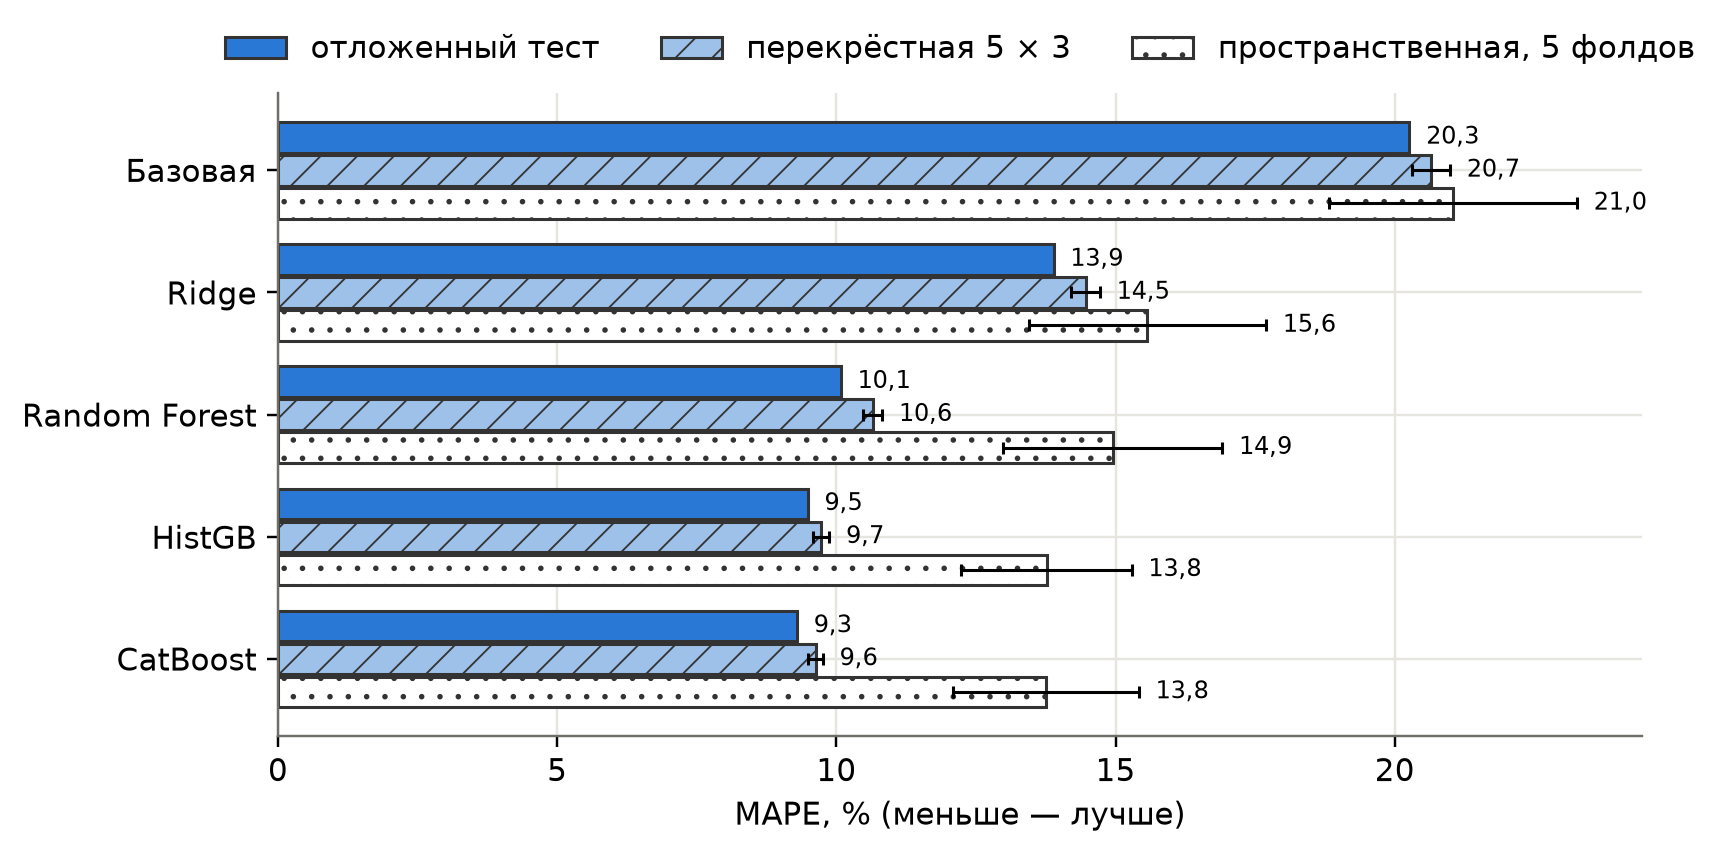

In [18]:
# Статистическое сравнение по фолдам: Фридман, затем попарно Уилкоксон с поправкой Холма (и t-критерий Надо — Бенжио)
BEST = metrics_cv.sort_values("MAPE_%_mean").iloc[0]["model"]
n_tr, n_te = split_info["cv_fold_train_mean"], split_info["cv_fold_test_mean"]
stat_rows, pair_parts = [], []
for scheme, label in (("cv", "перекрёстная 5 × 3"), ("spatial", "пространственная, 5 фолдов")):
    for metric in ("MAPE_%", "MAE_млн"):
        wide = folds_models[folds_models["scheme"] == scheme].pivot(index="fold", columns="model", values=metric)[M.MODEL_ORDER]
        chi2, p, ranks = V.friedman(wide)
        stat_rows.append({"scheme": scheme, "схема": label, "metric": metric, "friedman_chi2": chi2, "df": wide.shape[1] - 1, "p": p,
                          "n_folds": len(wide), **{f"rank_{k}": ranks[k] for k in M.MODEL_ORDER}})
        if scheme == "cv":                 # на 5 пространственных фолдах критерий Уилкоксона не может дать p < 0,0625
            pair_parts.append(V.pairwise_tests(wide, n_tr, n_te).assign(scheme=scheme, metric=metric))
stat_friedman = save_csv(pd.DataFrame(stat_rows), "stat_friedman.csv")
stat_pairs = save_csv(pd.concat(pair_parts, ignore_index=True), "stat_pairwise_models.csv")
table(stat_friedman.drop(columns=["scheme"]).set_index(["схема", "metric"]), "Критерий Фридмана (средние ранги: меньше — лучше)", digits=4)
show = stat_pairs[(stat_pairs["metric"] == "MAPE_%")].copy()
show["пара"] = show["A"].map(MODEL_SHORT) + " − " + show["B"].map(MODEL_SHORT)
table(show.set_index("пара")[["mean_A", "mean_B", "diff_A_minus_B", "folds_B_better", "p_wilcoxon", "p_holm", "p_NB", "p_NB_holm"]],
      "Попарные сравнения по MAPE, %, перекрёстная проверка (разность A − B: положительная — модель B лучше)", digits=4)

fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(M.MODEL_ORDER))
for i, (lab, src, col, hatch) in enumerate((("отложенный тест", metrics_test.set_index("model")["MAPE_%"], BLUE, ""),
                                           ("перекрёстная 5 × 3", metrics_cv.set_index("model"), "#9ec1ea", "//"),
                                           ("пространственная, 5 фолдов", metrics_spatial.set_index("model"), "white", ".."))):
    vals = src.loc[M.MODEL_ORDER] if i == 0 else src.loc[M.MODEL_ORDER, "MAPE_%_mean"]
    err = None if i == 0 else src.loc[M.MODEL_ORDER, "MAPE_%_std"]
    ax.barh(yy + (i - 1) * 0.27, vals, height=0.25, color=col, edgecolor="#333", hatch=hatch, xerr=err, error_kw=dict(lw=1, capsize=2), label=lab)
    for y0, v, e in zip(yy + (i - 1) * 0.27, vals, [0] * 5 if err is None else err):
        ax.text(v + e + 0.3, y0, ru(v, 1), va="center", fontsize=8)
ax.set_yticks(yy, [MODEL_SHORT[k] for k in M.MODEL_ORDER])
ax.invert_yaxis()
ax.set_xlabel("MAPE, % (меньше — лучше)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncols=3)
savefig("fig10_model_comparison", "MAPE пяти моделей на отложенном тесте, при перекрёстной и при пространственной проверке (отрезки — ст. откл. по фолдам): "
        "ансамбли деревьев примерно вдвое точнее базовой оценки; на новых местах ошибка всех моделей выше.")

## 10. Вклад открытых геоданных: абляция · `шаг 6`
Лестница наборов A → E для лучшей модели и для Ridge на одних и тех же фолдах и с одними гиперпараметрами (подобраны на E). Главное сравнение D против E при пространственной проверке идёт на 10 фолдах: пять по исходной сетке ячеек и пять по сетке, сдвинутой на 1 км.

In [19]:
ABL_SETS = {**F.FEATURE_SETS, "A+OSM": F.EXTRA_SETS["A+OSM"]}
ABL_LABELS = {**F.SET_LABELS, "A+OSM": "A + геопризнаки OSM (без района и координат)"}
ABL_MODELS = [BEST, "ridge"]
ABL_SCHEMES = {"A": ("cv", "spatial"), "B": ("cv", "spatial"), "C": ("cv", "spatial"), "D": ("cv", "spatial", "spatial2", "lodo"),
               "A+OSM": ("cv", "spatial", "lodo")}


def ablation_folds(kind, tag):
    if tag == "E":                                    # cv, spatial, lodo уже посчитаны в разделе 9; добавляется второе пространственное разбиение (сдвинутая сетка)
        extra = cached(f"folds_{kind}_E_spatial2", lambda: run_schemes(kind, E_SET, PARAMS[kind], "E", ("spatial2",)))
        return pd.concat([folds_models[folds_models["model"] == kind], extra], ignore_index=True)
    return cached(f"folds_{kind}_{tag}", lambda: run_schemes(kind, ABL_SETS[tag], PARAMS[kind], tag, ABL_SCHEMES[tag]))


abl_folds = pd.concat([ablation_folds(k, t) for k in ABL_MODELS for t in ABL_SETS], ignore_index=True)
sp10 = abl_folds[abl_folds["scheme"].isin(["spatial", "spatial2"]) & abl_folds["feature_set"].isin(["D", "E"])].copy()
sp10["fold"] += np.where(sp10["scheme"] == "spatial2", 5, 0)          # 10 пространственных фолдов для D и E
sp10["scheme"] = "spatial10"
abl_folds = pd.concat([abl_folds[abl_folds["scheme"] != "spatial2"], sp10], ignore_index=True)
save_csv(abl_folds, "ablation_folds.csv")

holdout_abl = cached("holdout_ablation_pred", lambda: {k: {m: v for m, v in r.items() if m != "model"} for k, r in V.fit_holdout(
    {f"{k}|{t}": (k, ABL_SETS[t], PARAMS[k]) for k in ABL_MODELS for t in ABL_SETS if t != "E"}, train, test).items()})
abl_test = pd.DataFrame([{"model": k, "feature_set": t, **{m: (final[k] if t == "E" else holdout_abl[f"{k}|{t}"])[m] for m in M.METRIC_COLS}}
                         for k in ABL_MODELS for t in ABL_SETS])

abl_rows = []
for (k, t, s), g in abl_folds.groupby(["model", "feature_set", "scheme"], sort=False):
    row = {"model": k, "feature_set": t, "scheme": s, "n_features": len(ABL_SETS[t]), "n_folds": len(g)}
    for mcol in M.METRIC_COLS:
        row[f"{mcol}_mean"], row[f"{mcol}_std"] = g[mcol].mean(), g[mcol].std(ddof=1)
    abl_rows.append(row)
abl_summary = pd.DataFrame(abl_rows).merge(abl_test.rename(columns={m: f"{m}_test" for m in M.METRIC_COLS}), on=["model", "feature_set"])
abl_summary.insert(2, "набор", abl_summary["feature_set"].map(ABL_LABELS))
save_csv(abl_summary, "ablation_summary.csv")

for k in ABL_MODELS:
    s = abl_summary[abl_summary["model"] == k]
    view = pd.DataFrame({"признаков": s[s.scheme == "cv"].set_index("набор")["n_features"]})
    for sch, lab in (("cv", "перекрёстная"), ("spatial", "пространственная"), ("lodo", "5 районов → 6-й")):
        ss = s[s.scheme == sch].set_index("набор").reindex(view.index)
        view[f"MAPE, % · {lab}"] = [f"{a:.2f} ± {b:.2f}" if a == a else "—" for a, b in zip(ss["MAPE_%_mean"], ss["MAPE_%_std"])]
        if sch != "lodo":
            view[f"MAE, млн ₸ · {lab}"] = [f"{a:.2f} ± {b:.2f}" for a, b in zip(ss["MAE_млн_mean"], ss["MAE_млн_std"])]
    view["MAPE, % · тест"] = s[s.scheme == "cv"].set_index("набор")["MAPE_%_test"].round(2)
    view["R² · тест"] = s[s.scheme == "cv"].set_index("набор")["R2_test"].round(3)
    table(view, f"Абляция признаков · {M.MODEL_LABELS[k]} (среднее ± ст. откл. по фолдам)")

#### ▶ Абляция признаков · CatBoost (среднее ± ст. откл. по фолдам)

,признаков,"MAPE, % · перекрёстная","MAE, млн ₸ · перекрёстная","MAPE, % · пространственная","MAE, млн ₸ · пространственная","MAPE, % · 5 районов → 6-й","MAPE, % · тест",R² · тест
набор,,,,,,,,
A: объектные,28,14.69 ± 0.27,7.50 ± 0.25,16.29 ± 1.55,8.34 ± 1.48,—,14.610,0.846
B: A + район,29,13.25 ± 0.23,6.91 ± 0.21,15.25 ± 1.33,7.93 ± 1.25,—,12.970,0.872
C: A + координаты,30,10.38 ± 0.18,5.53 ± 0.19,13.13 ± 1.34,7.14 ± 1.59,—,10.110,0.920
D: A + район + координаты,31,10.33 ± 0.13,5.50 ± 0.16,13.32 ± 1.53,7.22 ± 1.65,17.68 ± 6.59,10.090,0.918
E: D + геопризнаки OSM,64,9.63 ± 0.13,5.13 ± 0.18,13.75 ± 1.67,7.55 ± 1.75,15.03 ± 1.87,9.290,0.926
A + геопризнаки OSM (без района и координат),61,9.72 ± 0.15,5.18 ± 0.19,14.21 ± 2.31,7.73 ± 2.30,15.57 ± 2.36,9.470,0.921


#### ▶ Абляция признаков · Ridge (среднее ± ст. откл. по фолдам)

,признаков,"MAPE, % · перекрёстная","MAE, млн ₸ · перекрёстная","MAPE, % · пространственная","MAE, млн ₸ · пространственная","MAPE, % · 5 районов → 6-й","MAPE, % · тест",R² · тест
набор,,,,,,,,
A: объектные,28,18.06 ± 0.34,9.49 ± 0.35,18.35 ± 1.98,9.64 ± 2.03,—,17.360,0.785
B: A + район,29,16.86 ± 0.36,8.98 ± 0.33,17.21 ± 1.66,9.15 ± 1.72,—,16.280,0.802
C: A + координаты,30,17.26 ± 0.34,9.21 ± 0.35,17.66 ± 1.84,9.39 ± 1.87,—,16.590,0.791
D: A + район + координаты,31,16.87 ± 0.36,8.99 ± 0.34,17.30 ± 1.66,9.18 ± 1.73,21.20 ± 2.05,16.290,0.802
E: D + геопризнаки OSM,64,14.46 ± 0.26,7.94 ± 0.31,15.57 ± 2.13,8.50 ± 1.99,17.76 ± 3.34,13.890,0.830
A + геопризнаки OSM (без района и координат),61,14.92 ± 0.25,8.08 ± 0.34,16.13 ± 2.41,8.65 ± 2.17,18.29 ± 3.00,14.430,0.825


In [20]:
# Значимость шагов лестницы: парные сравнения на одних и тех же фолдах, поправка Холма внутри (модель, схема, метрика)
STEPS = [("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("D", "E"), ("A", "A+OSM"), ("C", "A+OSM")]
# t-критерий Надо — Бенжио считается там, где фолды повторяются: перекрёстная 5 × 3 и 10 пространственных фолдов по двум сеткам
NB_SIZES = {"cv": (n_tr, n_te), "spatial10": (split_info["spatial_fold_train_mean"], split_info["spatial_fold_test_mean"])}
parts = []
for k in ABL_MODELS:
    for scheme, pairs in (("cv", STEPS), ("spatial", STEPS), ("spatial10", [("D", "E")]), ("lodo", [("D", "E"), ("D", "A+OSM")])):
        for metric in ("MAPE_%", "MAE_млн"):
            wide = abl_folds[(abl_folds["model"] == k) & (abl_folds["scheme"] == scheme)].pivot(index="fold", columns="feature_set", values=metric)
            pw = V.pairwise_tests(wide, *NB_SIZES.get(scheme, (None, None)), pairs=pairs)
            parts.append(pw.assign(model=k, scheme=scheme, metric=metric))
abl_tests = pd.concat(parts, ignore_index=True)
abl_tests["improvement"] = abl_tests["diff_A_minus_B"]            # снижение ошибки при переходе от набора A к набору B
abl_tests["improvement_rel_%"] = abl_tests["diff_rel_%"]
abl_tests["change"], abl_tests["change_rel_%"] = -abl_tests["improvement"], -abl_tests["improvement_rel_%"]      # то же со знаком изменения ошибки
abl_tests["step"] = abl_tests["A"] + " → " + abl_tests["B"]
save_csv(abl_tests, "ablation_tests.csv")
for k in ABL_MODELS:
    v = abl_tests[(abl_tests["model"] == k) & (abl_tests["metric"] == "MAPE_%")]
    table(v.set_index(["scheme", "step"])[["mean_A", "mean_B", "improvement", "improvement_rel_%", "folds_B_better", "n_folds", "p_wilcoxon", "p_holm", "p_NB"]],
          f"Шаги абляции по MAPE, % · {M.MODEL_LABELS[k]} (improvement > 0 — добавление признаков снизило ошибку; на 5 фолдах p Уилкоксона не бывает меньше 0,0625, на 6 — меньше 0,0313)", digits=4)

#### ▶ Шаги абляции по MAPE, % · CatBoost (improvement > 0 — добавление признаков снизило ошибку; на 5 фолдах p Уилкоксона не бывает меньше 0,0625, на 6 — меньше 0,0313)

#### ▶ Шаги абляции по MAPE, % · Ridge (improvement > 0 — добавление признаков снизило ошибку; на 5 фолдах p Уилкоксона не бывает меньше 0,0625, на 6 — меньше 0,0313)

In [21]:
# Где возникает выигрыш E над D на отложенном тесте: дома, известные модели (те же координаты есть в обучении), против новых домов
seen_rows = []
for k in ABL_MODELS:
    for name, mask in (("дом есть в обучении", seen_house), ("дом новый для модели", ~seen_house), ("весь тест", np.ones(len(test), bool))):
        mD, mE = M.metrics(y_test[mask], holdout_abl[f"{k}|D"]["pred"][mask]), M.metrics(y_test[mask], final[k]["pred"][mask])
        seen_rows.append({"model": k, "segment": name, "n": int(mask.sum()), "MAPE_D": mD["MAPE_%"], "MAPE_E": mE["MAPE_%"], "improvement_пп": mD["MAPE_%"] - mE["MAPE_%"],
                          "improvement_rel_%": (mD["MAPE_%"] - mE["MAPE_%"]) / mD["MAPE_%"] * 100, "MAE_D_млн": mD["MAE_млн"], "MAE_E_млн": mE["MAE_млн"]})
abl_seen = save_csv(pd.DataFrame(seen_rows), "ablation_seen_vs_new.csv")
table(abl_seen.assign(model=abl_seen["model"].map(MODEL_SHORT)).set_index(["model", "segment"]),
      "D против E на отложенном тесте: известные модели дома и новые дома (improvement > 0 — набор E точнее)")

#### ▶ D против E на отложенном тесте: известные модели дома и новые дома (improvement > 0 — набор E точнее)

#### ▶ CatBoost: D против E при каждой из 6 конфигураций поиска (3 фолда, обучающая часть) · E точнее в 6 из 6

,param_learning_rate,param_l2_leaf_reg,param_depth,rmse_log_D,rmse_log_E,MAPE_D,MAPE_E,improvement_пп,improvement_rel_%,best_for_D,best_for_E
config,,,,,,,,,,,
0,0.0800,1.0000,6,0.1426,0.1337,10.6891,9.9895,0.6996,6.5450,False,False
1,0.1000,1.0000,6,0.1414,0.1323,10.6149,9.8763,0.7386,6.9585,False,False
2,0.1500,10.0000,6,0.1427,0.1339,10.7147,10.0307,0.6840,6.3839,False,False
3,0.1500,3.0000,6,0.1411,0.1334,10.6048,9.9649,0.6399,6.0340,False,False
4,0.0800,3.0000,6,0.1437,0.1348,10.7689,10.0890,0.6798,6.3130,False,False
5,0.1000,3.0000,8,0.1405,0.1321,10.5128,9.7879,0.7249,6.8957,True,True


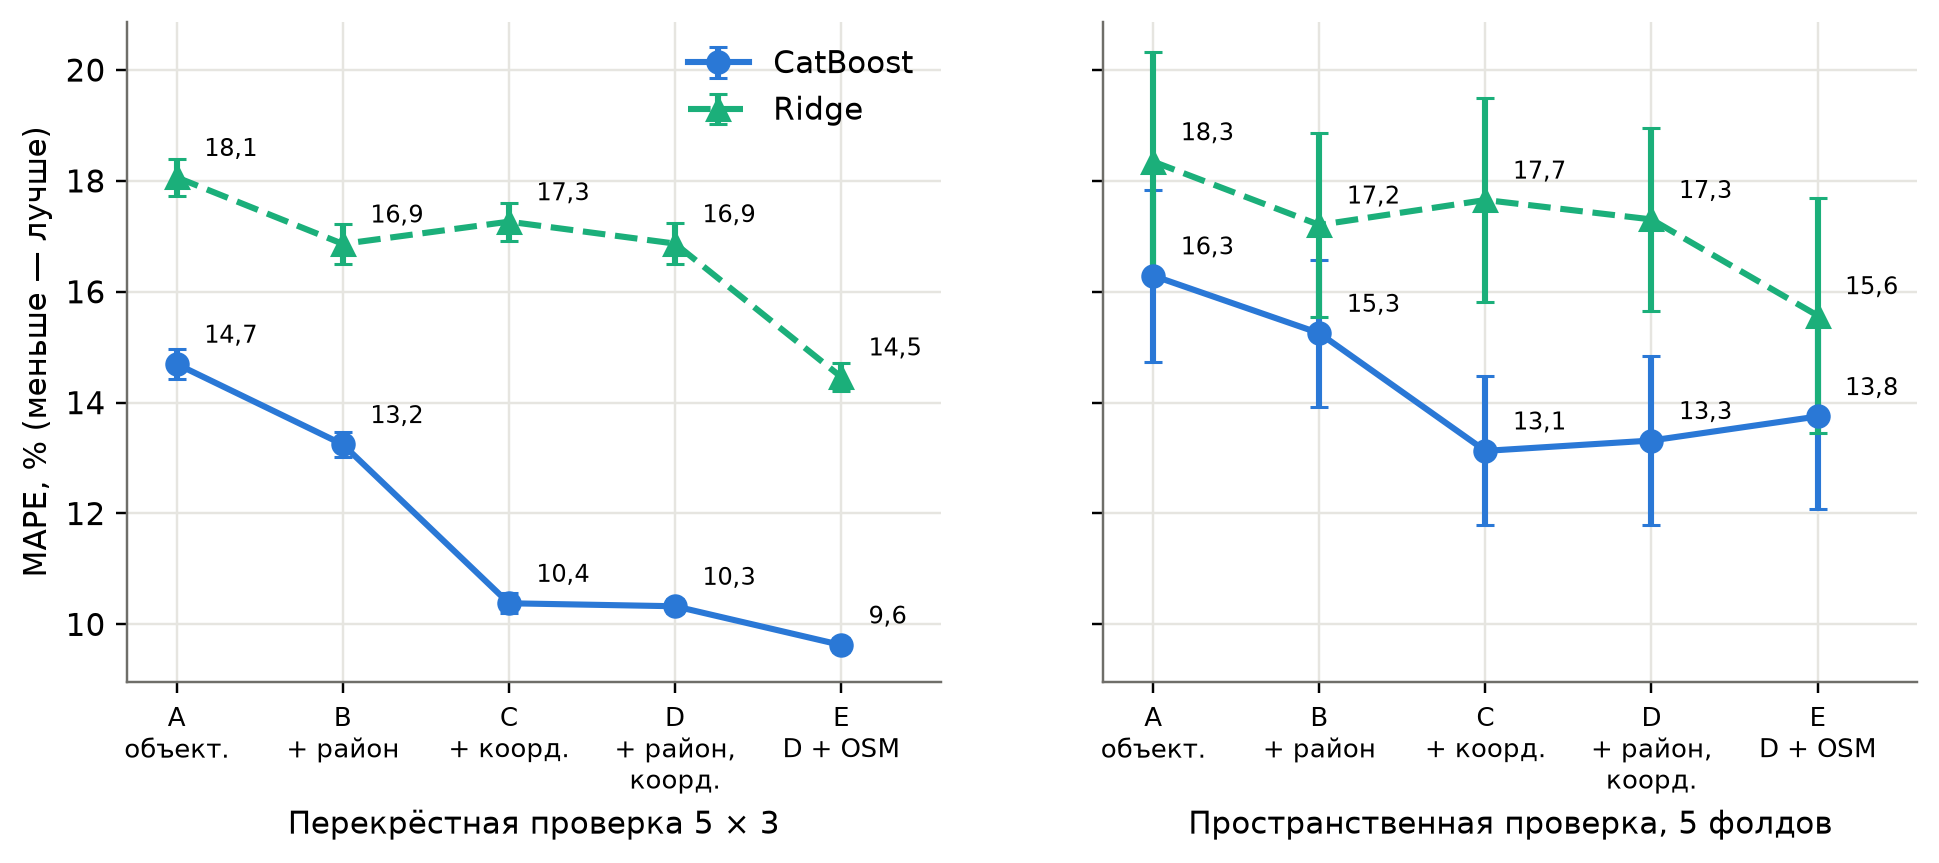

In [22]:
# Устойчивость главного сравнения к гиперпараметрам: одни и те же конфигурации случайного поиска на наборах D и E (3 фолда)
sE, sD = (search[k][1].set_index("config") for k in ("catboost", "catboost_D"))
pcols = [c for c in sE.columns if c.startswith("param_") and sE[c].nunique() > 1]
abl_robust = sE[pcols].join(pd.DataFrame({"rmse_log_D": sD["rmse_log"], "rmse_log_E": sE["rmse_log"], "MAPE_D": sD["MAPE_%"], "MAPE_E": sE["MAPE_%"]})).sort_index()
abl_robust["improvement_пп"] = abl_robust["MAPE_D"] - abl_robust["MAPE_E"]
abl_robust["improvement_rel_%"] = abl_robust["improvement_пп"] / abl_robust["MAPE_D"] * 100
abl_robust["best_for_D"], abl_robust["best_for_E"] = abl_robust["rmse_log_D"] == abl_robust["rmse_log_D"].min(), abl_robust["rmse_log_E"] == abl_robust["rmse_log_E"].min()
save_csv(abl_robust, "ablation_robustness.csv", index=True)
robust_info = {"configs": len(abl_robust), "configs_E_better": int((abl_robust["improvement_пп"] > 0).sum()),
               "improvement_пп_min": float(abl_robust["improvement_пп"].min()), "improvement_пп_max": float(abl_robust["improvement_пп"].max()),
               "best_D_MAPE": float(abl_robust.loc[abl_robust["best_for_D"], "MAPE_D"].iloc[0]), "best_E_MAPE": float(abl_robust.loc[abl_robust["best_for_E"], "MAPE_E"].iloc[0]),
               "same_best_config": bool((abl_robust["best_for_D"] & abl_robust["best_for_E"]).any())}
robust_info["best_vs_best_improvement_пп"] = robust_info["best_D_MAPE"] - robust_info["best_E_MAPE"]
table(abl_robust, f"CatBoost: D против E при каждой из {len(abl_robust)} конфигураций поиска (3 фолда, обучающая часть) · E точнее в {robust_info['configs_E_better']} из {robust_info['configs']}", digits=4)

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
ladder = list(F.FEATURE_SETS)
for a, scheme, lab in ((ax[0], "cv", "Перекрёстная проверка 5 × 3"), (ax[1], "spatial", "Пространственная проверка, 5 фолдов")):
    for k in ABL_MODELS:
        s = abl_summary[(abl_summary["model"] == k) & (abl_summary["scheme"] == scheme)].set_index("feature_set").loc[ladder]
        col, _, mk = MODEL_STYLE[k]
        a.errorbar(range(len(ladder)), s["MAPE_%_mean"], yerr=s["MAPE_%_std"], color=col, marker=mk, ms=7, lw=2, capsize=3,
                   ls="-" if k == BEST else "--", label=MODEL_SHORT[k])
        for i, v in enumerate(s["MAPE_%_mean"]):
            a.annotate(ru(v, 1), (i, v), textcoords="offset points", xytext=(9, 7), ha="left", fontsize=8)
    a.set_xticks(range(len(ladder)), ["A\nобъект.", "B\n+ район", "C\n+ коорд.", "D\n+ район,\nкоорд.", "E\nD + OSM"], fontsize=8.5)
    a.set_xlabel(lab)
    a.set_xlim(-0.3, len(ladder) - 0.4)
ax[0].set_ylabel("MAPE, % (меньше — лучше)")
ax[0].legend()
savefig("fig11_ablation", "Абляция признаков: MAPE на наборах A (объектные), B (A + район), C (A + координаты), D (A + район + координаты), E (D + геопризнаки OSM) для CatBoost и Ridge "
        "при перекрёстной (слева) и пространственной (справа) проверке, отрезки — ст. откл. по фолдам. При случайном разбиении геопризнаки снижают ошибку обеих моделей; "
        "на новых местах они помогают только Ridge, а у CatBoost набор E не лучше набора D.")

## 11. Название ЖК — признак высокой кардинальности · `шаг 4`
В основные наборы не входит. Здесь — вариант «E + ЖК»: CatBoost кодирует категорию упорядоченной целевой статистикой, остальные модели — `TargetEncoder` внутри конвейера, то есть код считается только по обучающей части фолда. Проверка — на отложенном тесте и первых пяти фолдах перекрёстной проверки.

In [23]:
JK_SET = F.EXTRA_SETS["E+ЖК"]
cx_folds = pd.concat([cached(f"folds_{k}_EJK", lambda k=k: run_schemes(k, JK_SET, PARAMS[k], "E+ЖК", ("cv5",))) for k in ABL_MODELS], ignore_index=True)
cx_hold = cached("holdout_EJK", lambda: {k: {m: v for m, v in r.items() if m not in ("model", "pred")} for k, r in
                                         V.fit_holdout({k: (k, JK_SET, PARAMS[k]) for k in ABL_MODELS}, train, test).items()})
e5 = abl_folds[(abl_folds["feature_set"] == "E") & (abl_folds["scheme"] == "cv") & (abl_folds["fold"] < 5)]
both = pd.concat([e5, cx_folds], ignore_index=True)
cx_rows = []
for k in ABL_MODELS:
    wide = both[both["model"] == k].pivot(index="fold", columns="feature_set", values="MAPE_%")
    pw = V.pairwise_tests(wide, np.mean([len(s[0]) for s in cv_splits[:5]]), np.mean([len(s[1]) for s in cv_splits[:5]]), pairs=[("E", "E+ЖК")]).iloc[0]
    cx_rows.append({"model": k, "scheme": "cv5", "MAPE_E": pw["mean_A"], "MAPE_E_ЖК": pw["mean_B"], "improvement_пп": pw["diff_A_minus_B"],
                    "improvement_rel_%": pw["diff_rel_%"], "folds_ЖК_better": pw["folds_B_better"], "n_folds": pw["n_folds"], "p_wilcoxon": pw["p_wilcoxon"], "p_NB": pw["p_NB"]})
    cx_rows.append({"model": k, "scheme": "test", "MAPE_E": final[k]["MAPE_%"], "MAPE_E_ЖК": cx_hold[k]["MAPE_%"],
                    "improvement_пп": final[k]["MAPE_%"] - cx_hold[k]["MAPE_%"], "improvement_rel_%": (final[k]["MAPE_%"] - cx_hold[k]["MAPE_%"]) / final[k]["MAPE_%"] * 100})
complex_variant = pd.DataFrame(cx_rows)
complex_variant["change_пп"] = -complex_variant["improvement_пп"]
save_csv(complex_variant, "complex_variant.csv")
save_csv(cx_folds, "complex_folds.csv")
complex_info = {"unique_names_train": int(train.loc[train["in_complex"] == 1, "residential_complex_name"].nunique()),
                "test_rows_complex_unseen_%": float((~test["residential_complex_name"].isin(set(train["residential_complex_name"]))).mean() * 100),
                "names_with_one_listing": int((train["residential_complex_name"].value_counts() == 1).sum())}
table(complex_variant.assign(model=complex_variant["model"].map(MODEL_SHORT)).set_index(["model", "scheme"]),
      f"Набор E против «E + название ЖК» по MAPE, % · названий в обучении: {complex_info['unique_names_train']}", digits=4)

#### ▶ Набор E против «E + название ЖК» по MAPE, % · названий в обучении: 1151

## 12. Интерпретация лучшей модели · `шаг 7`
Перестановочная важность — на отложенном тесте (10 перемешиваний); SHAP — точные значения для деревьев, в единицах log(цены): вклад 0,10 ≈ +10,5 % к цене.

In [24]:
best_model, best_pred = final[BEST]["model"], final[BEST]["pred"]
perm = cached("perm_importance", lambda: A.permutation_importance(best_model, test, y_test, n_repeats=10), FP_A)
sv, shap_base = cached("shap_test", lambda: A.shap_values(best_model, test), FP_A)
shap_imp = A.shap_summary(sv, best_model.features)
perm["label"], perm["group"] = perm["feature"].map(F.SHORT), perm["feature"].map(F.group_of)
perm["rank_perm"] = np.arange(1, len(perm) + 1)
shap_imp["rank_shap"] = np.arange(1, len(shap_imp) + 1)
save_csv(perm, "permutation_importance.csv")
save_csv(shap_imp, "shap_importance.csv")

top10 = shap_imp.head(10).merge(perm[["feature", "dMAPE_пп_mean", "dMAPE_пп_std", "dMAE_млн_mean", "rank_perm"]], on="feature")
top10 = top10[["rank_shap", "feature", "label", "group", "mean_abs_shap", "share_%", "dMAPE_пп_mean", "dMAPE_пп_std", "dMAE_млн_mean", "rank_perm"]]
save_csv(top10, "top10_factors.csv")
table(top10.set_index("rank_shap"), f"Десять главных факторов цены · {M.MODEL_LABELS[BEST]}, набор E (средний модуль SHAP и рост MAPE на тесте при перемешивании, п. п.)")

group_imp = cached("group_importance", lambda: A.group_importance(best_model, test, y_test, sv), FP_A)
save_csv(group_imp, "group_importance.csv")
table(group_imp.set_index("group"), "Важность групп признаков: доля в сумме средних модулей SHAP и рост MAPE при совместном перемешивании группы")

#### ▶ Десять главных факторов цены · CatBoost, набор E (средний модуль SHAP и рост MAPE на тесте при перемешивании, п. п.)

,feature,label,group,mean_abs_shap,share_%,dMAPE_пп_mean,dMAPE_пп_std,dMAE_млн_mean,rank_perm
rank_shap,,,,,,,,,
1,area,Площадь,объектные,0.260,28.686,30.797,0.453,14.198,1
2,dist_center_km,"До центра, км",геоинфраструктурные,0.091,10.013,5.175,0.134,2.480,3
3,rooms,Комнат,объектные,0.076,8.409,4.600,0.159,2.673,4
4,year_built,Год постройки,объектные,0.072,7.983,5.639,0.167,3.189,2
5,ceiling_height,Высота потолков,объектные,0.048,5.292,1.450,0.064,0.789,6
6,district,Район,локационные,0.043,4.707,1.584,0.033,0.778,5
7,latitude,Широта,локационные,0.022,2.464,0.914,0.070,0.404,7
8,condition,Состояние,объектные,0.019,2.089,0.740,0.061,0.332,8
9,furniture,Мебель,объектные,0.018,1.960,0.487,0.042,0.226,10


#### ▶ Важность групп признаков: доля в сумме средних модулей SHAP и рост MAPE при совместном перемешивании группы

,n_features,shap_share_%,perm_dMAPE_пп,perm_dMAPE_пп_std,perm_dMAE_млн
group,,,,,
объектные,28,64.310,48.430,0.647,19.896
локационные,3,8.212,3.800,0.082,1.773
геоинфраструктурные,33,27.479,11.004,0.216,5.451


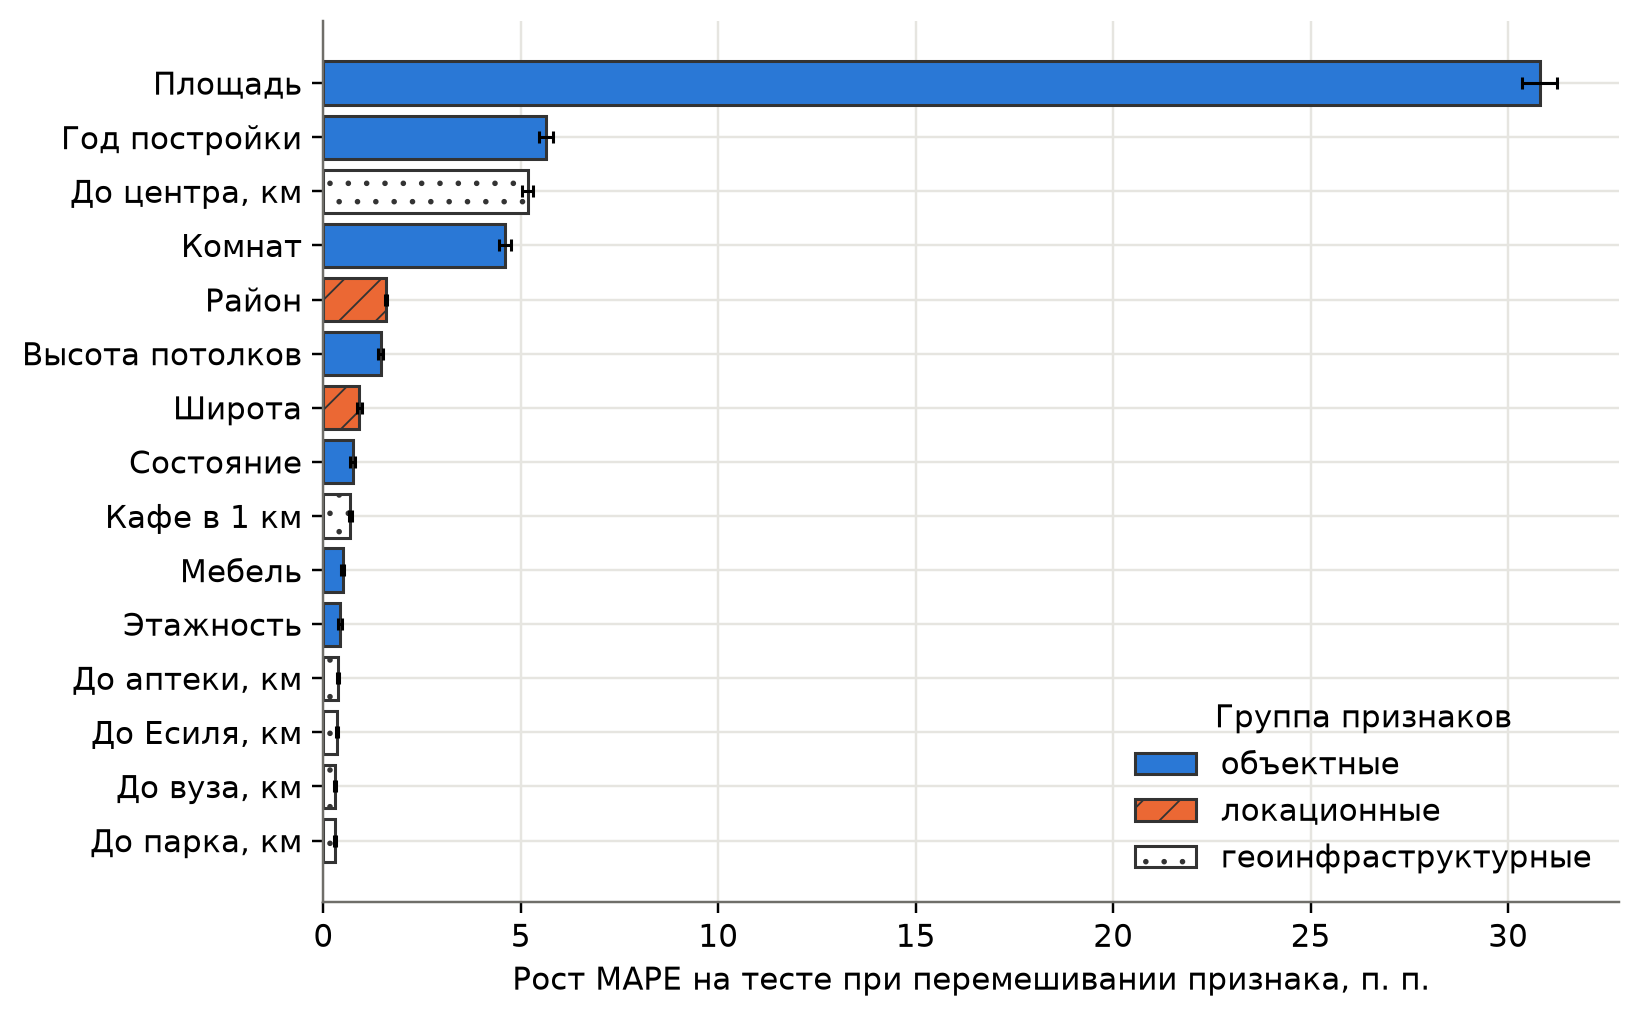

In [25]:
GROUP_STYLE = {"объектные": (BLUE, ""), "локационные": (ORANGE, "//"), "геоинфраструктурные": ("white", "..")}
fig, ax = plt.subplots(figsize=(7.6, 5.2))
p15 = perm.head(15)[::-1]
for i, r in enumerate(p15.itertuples()):
    col, hatch = GROUP_STYLE[r.group]
    ax.barh(i, r.dMAPE_пп_mean, xerr=r.dMAPE_пп_std, color=col, edgecolor="#333", hatch=hatch, error_kw=dict(lw=1, capsize=2))
ax.set_yticks(range(len(p15)), p15["label"])
ax.set_xlabel("Рост MAPE на тесте при перемешивании признака, п. п.")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc=c, ec="#333", hatch=h, label=g) for g, (c, h) in GROUP_STYLE.items()], loc="lower right", title="Группа признаков")
ru_ticks(ax, "x")
savefig("fig12_permutation_importance", "Перестановочная важность 15 признаков на тесте (рост MAPE в процентных пунктах, отрезки — ст. откл. по 10 перемешиваниям), штриховка — группа признака: "
        "перемешивание площади разрушает прогноз, далее идут год постройки, расстояние до центра и число комнат.")

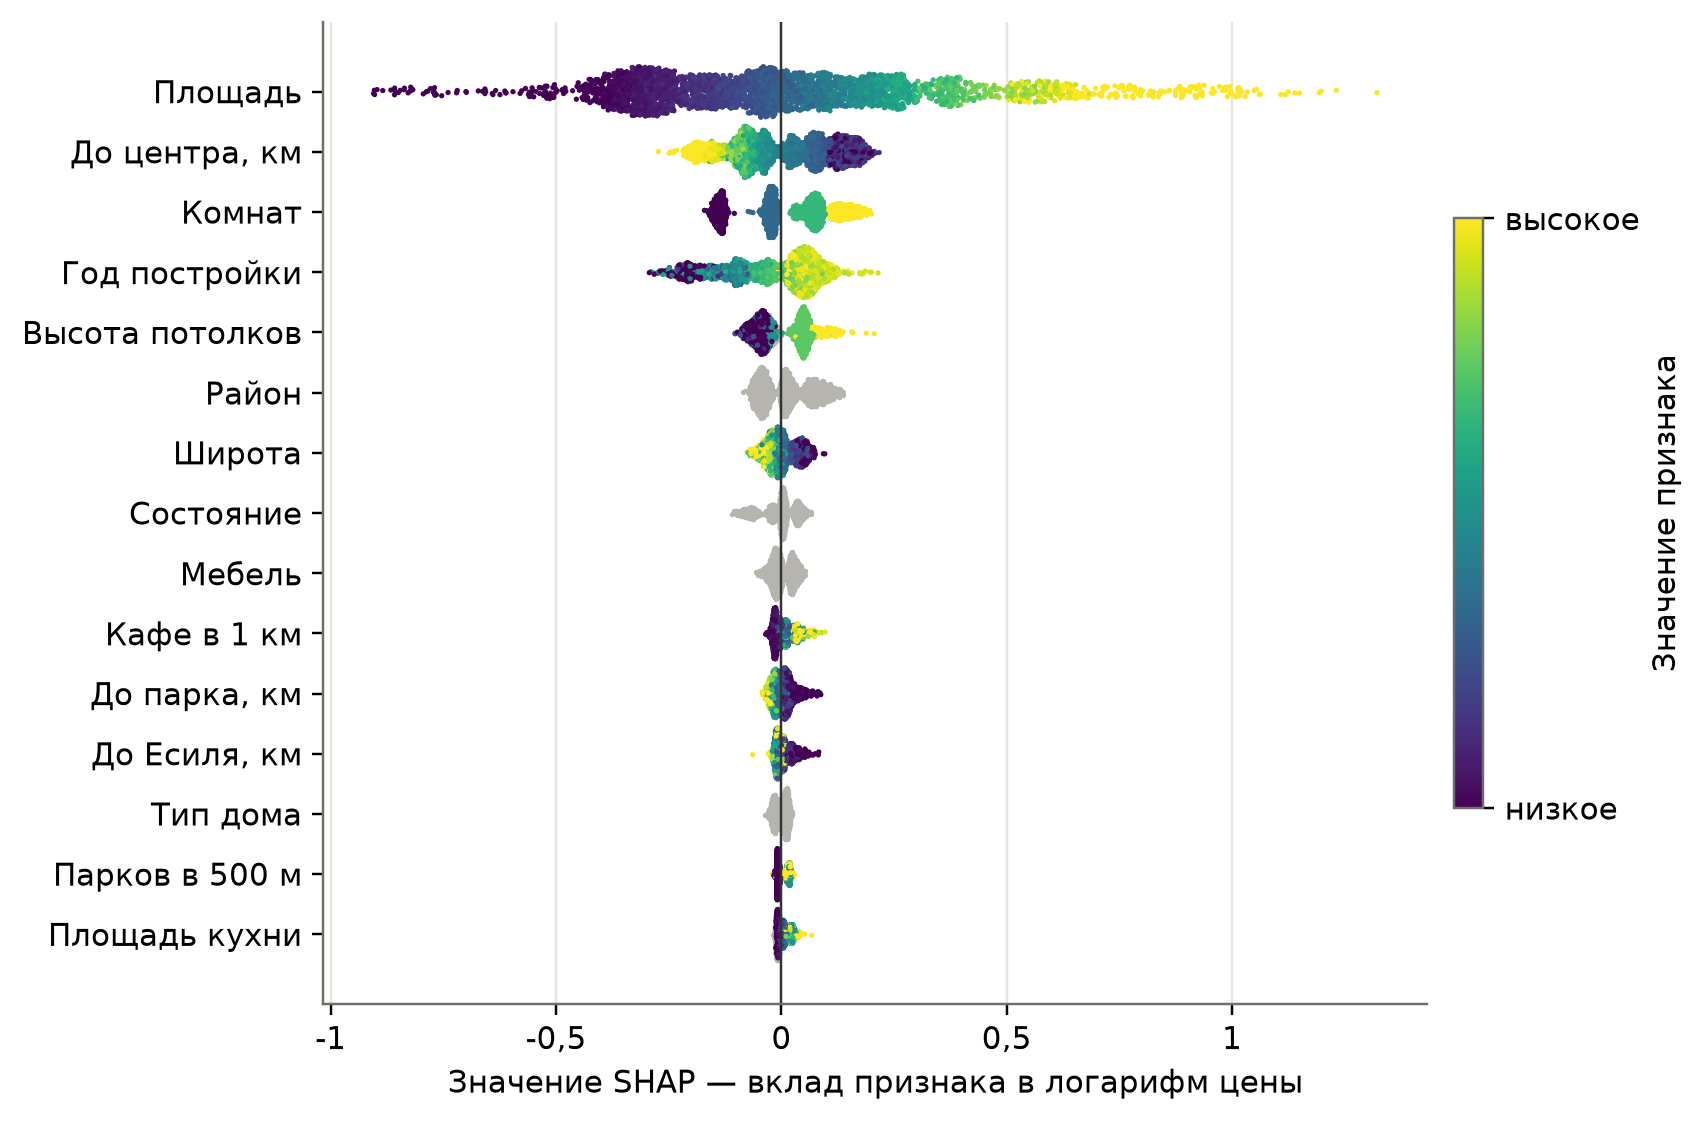

In [26]:
def beeswarm(ax, sv, X, features, top=15):
    """Диаграмма SHAP: строка — признак, точка — объявление, цвет — значение признака (серый — категориальный)."""
    order = np.argsort(-np.abs(sv).mean(axis=0))[:top][::-1]
    rng = np.random.default_rng(SEED)
    sc = None
    for row, j in enumerate(order):
        s = sv[:, j]
        hist, edges = np.histogram(s, bins=70)
        dens = hist[np.clip(np.digitize(s, edges) - 1, 0, len(hist) - 1)] / hist.max()
        yj = row + (rng.random(len(s)) - 0.5) * 0.85 * np.sqrt(dens)
        f = features[j]
        if f in F.CATEGORICAL:
            ax.scatter(s, yj, s=3, color="#b5b4ae", linewidths=0)
        else:
            v = X[f].to_numpy(float)
            lo, hi = np.nanpercentile(v, [5, 95])
            c = np.clip((v - lo) / (hi - lo if hi > lo else 1), 0, 1)
            ok = ~np.isnan(v)
            ax.scatter(s[~ok], yj[~ok], s=3, color="#b5b4ae", linewidths=0)
            sc = ax.scatter(s[ok], yj[ok], s=3, c=c[ok], cmap="viridis", vmin=0, vmax=1, linewidths=0)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_yticks(range(len(order)), [F.SHORT[features[j]] for j in order])
    ax.set_xlabel("Значение SHAP — вклад признака в логарифм цены")
    ax.grid(axis="y", visible=False)
    return sc


fig, ax = plt.subplots(figsize=(7.8, 5.8))
sc = beeswarm(ax, sv, test, best_model.features)
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02, ticks=[0, 1])
cb.ax.set_yticklabels(["низкое", "высокое"])
cb.set_label("Значение признака")
ru_ticks(ax, "x")
savefig("fig13_shap_summary", "Сводная диаграмма SHAP для 15 главных признаков: каждая точка — тестовое объявление, положение — вклад признака в логарифм цены, цвет — значение признака "
        "(серым — категориальный признак или пропуск). Большая площадь, новый дом и близость к центру повышают прогноз.")

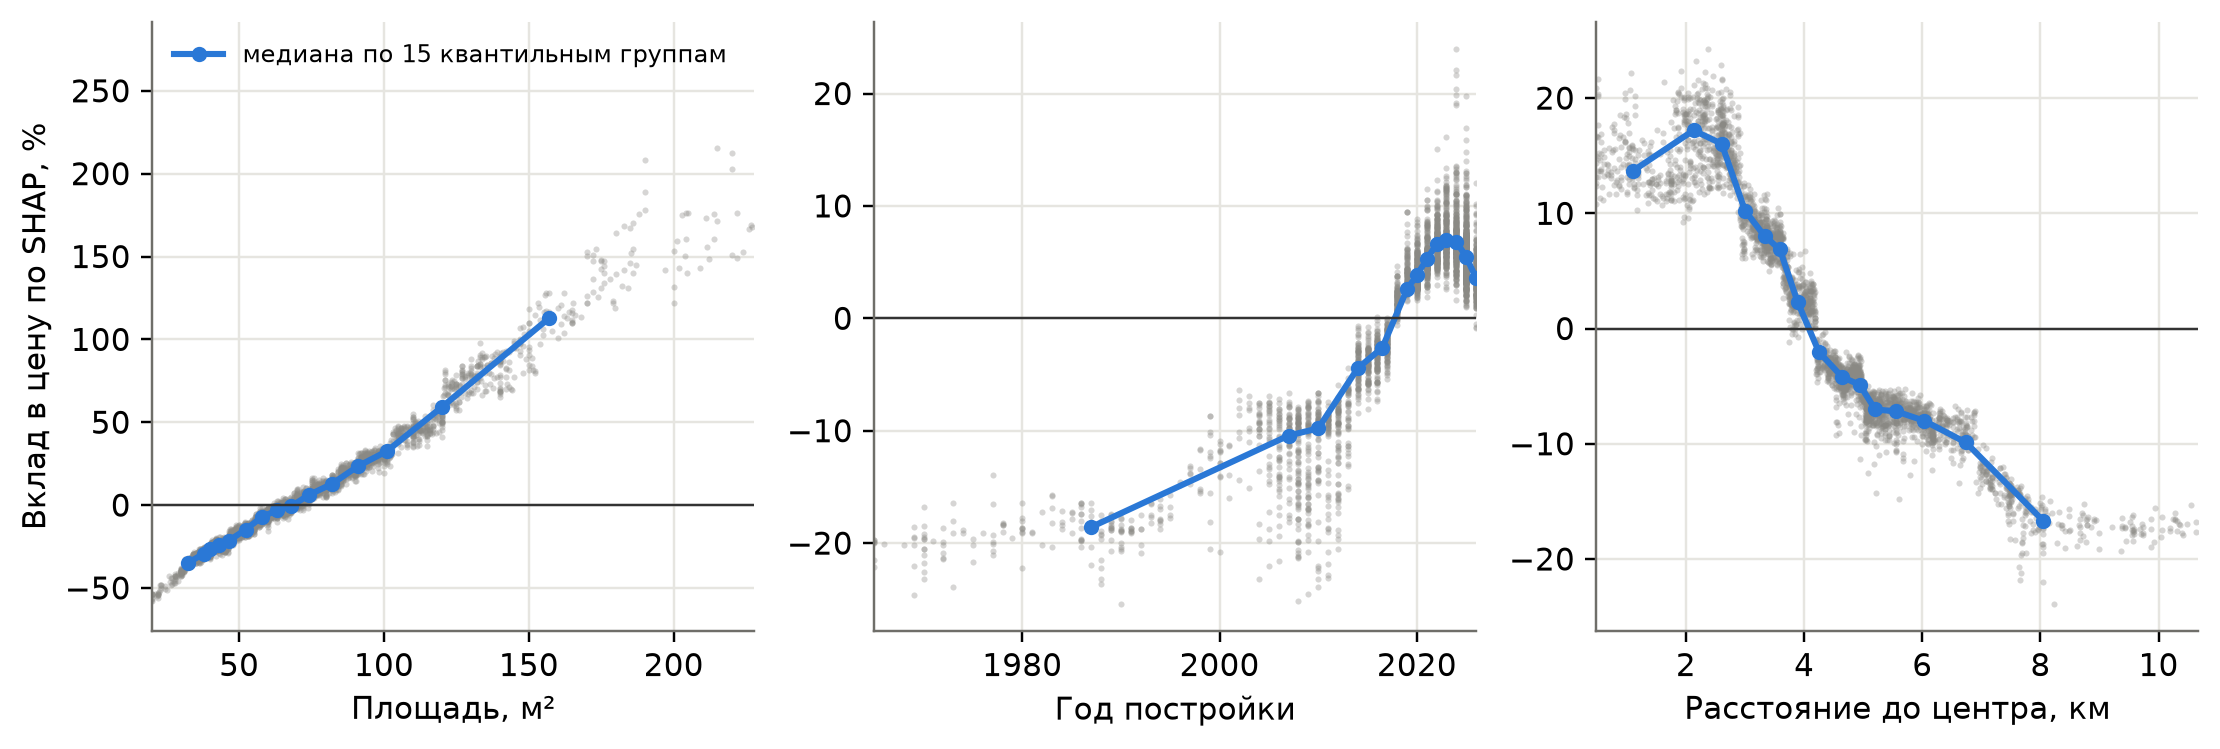

In [27]:
DEP = ["area", "year_built", "dist_center_km"]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
dep_rows = []
for a, f in zip(ax, DEP):
    j = best_model.features.index(f)
    x, eff = test[f].to_numpy(float), np.expm1(sv[:, j]) * 100
    a.scatter(x, eff, s=4, color=GRAY, alpha=0.35, linewidths=0)
    q = np.unique(np.quantile(x, np.linspace(0, 1, 16)))
    mid = pd.Series(eff).groupby(pd.cut(x, q, include_lowest=True), observed=True).median()
    xm = pd.Series(x).groupby(pd.cut(x, q, include_lowest=True), observed=True).median()
    a.plot(xm, mid, color=BLUE, marker="o", ms=4, lw=2, label="медиана по 15 квантильным группам")
    a.axhline(0, color="#333", lw=0.8)
    a.set(xlabel={"area": "Площадь, м²", "year_built": "Год постройки", "dist_center_km": "Расстояние до центра, км"}[f],
          xlim=np.quantile(x, [0.005, 0.995]))
    dep_rows += [{"feature": f, "x_median": float(a_), "effect_%_median": float(b_)} for a_, b_ in zip(xm, mid)]
ax[0].set_ylabel("Вклад в цену по SHAP, %")
ax[0].legend(fontsize=8, loc="upper left")
save_csv(pd.DataFrame(dep_rows), "shap_dependence.csv")
savefig("fig14_shap_dependence", "Зависимость вклада SHAP (в процентах к цене) от значения признака для площади, года постройки и расстояния до центра: "
        "вклад площади растёт монотонно; новые дома дороже старых; вклад положения максимален в 2–3 км от центра и падает к окраинам.")

#### ▶ Частная зависимость: размах среднего прогноза при изменении одного признака (2-й – 98-й процентили)

,min,max,размах_млн,отношение
feature,,,,
area,23.97,92.15,68.18,3.84
year_built,34.41,51.27,16.86,1.49
dist_center_km,36.51,51.36,14.85,1.41
ceiling_height,42.56,50.03,7.47,1.18


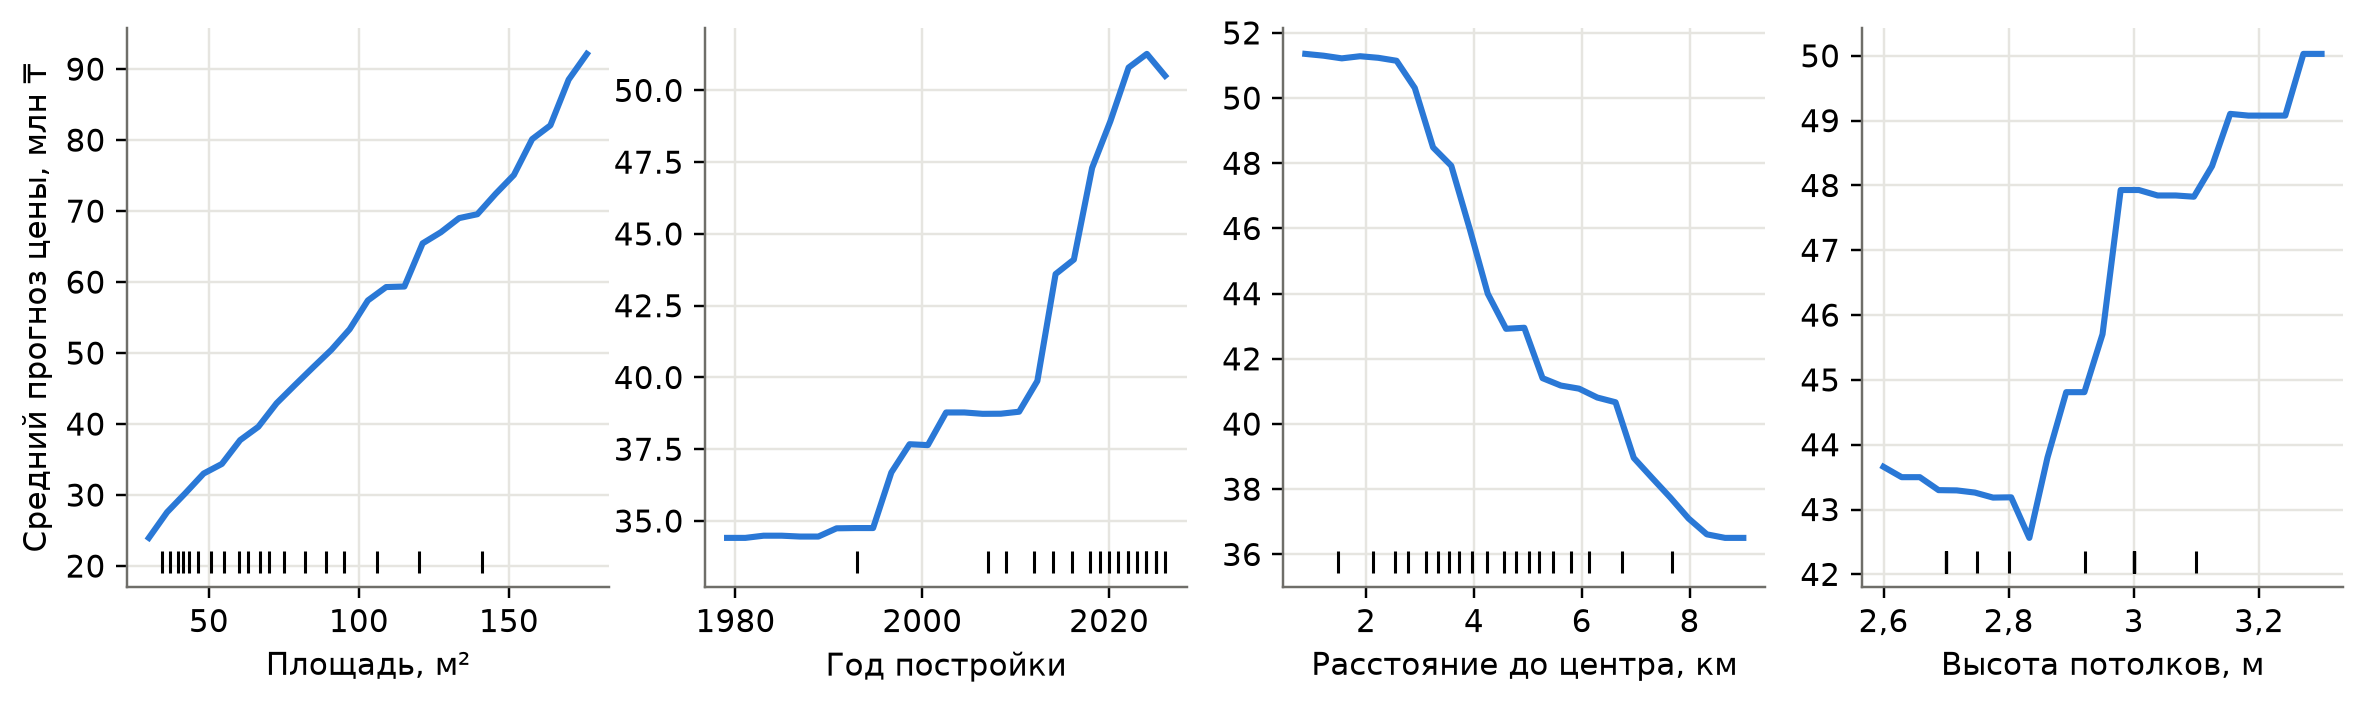

In [28]:
PDP_FEATURES = ["area", "year_built", "dist_center_km", "ceiling_height"]
pdp = cached("pdp", lambda: pd.concat([A.partial_dependence(best_model, test, f) for f in PDP_FEATURES], ignore_index=True), FP_A)
save_csv(pdp, "pdp.csv")
pdp_range = pdp.groupby("feature")["pd_mean_млн"].agg(["min", "max"]).assign(размах_млн=lambda d: d["max"] - d["min"], отношение=lambda d: d["max"] / d["min"]).loc[PDP_FEATURES]
save_csv(pdp_range, "pdp_range.csv", index=True)
fig, ax = plt.subplots(1, 4, figsize=(13, 3.3))
xl = {"area": "Площадь, м²", "year_built": "Год постройки", "dist_center_km": "Расстояние до центра, км", "ceiling_height": "Высота потолков, м"}
for a, f in zip(ax, PDP_FEATURES):
    d = pdp[pdp["feature"] == f]
    a.plot(d["value"], d["pd_mean_млн"], color=BLUE, lw=2)
    a.plot(test[f].dropna().quantile(np.linspace(0.05, 0.95, 19)), [a.get_ylim()[0]] * 19, "|", color="black", ms=7)
    a.set_xlabel(xl[f])
    ru_ticks(a, "x")
ax[0].set_ylabel("Средний прогноз цены, млн ₸")
table(pdp_range, "Частная зависимость: размах среднего прогноза при изменении одного признака (2-й – 98-й процентили)", digits=2)
savefig("fig15_partial_dependence", "Графики частной зависимости: средний прогноз цены при принудительной подстановке значения признака (засечки на оси — децили значений в тесте). "
        "Площадь меняет прогноз сильнее всего; год постройки, расстояние до центра и высота потолков дают меньший, но заметный сдвиг.")

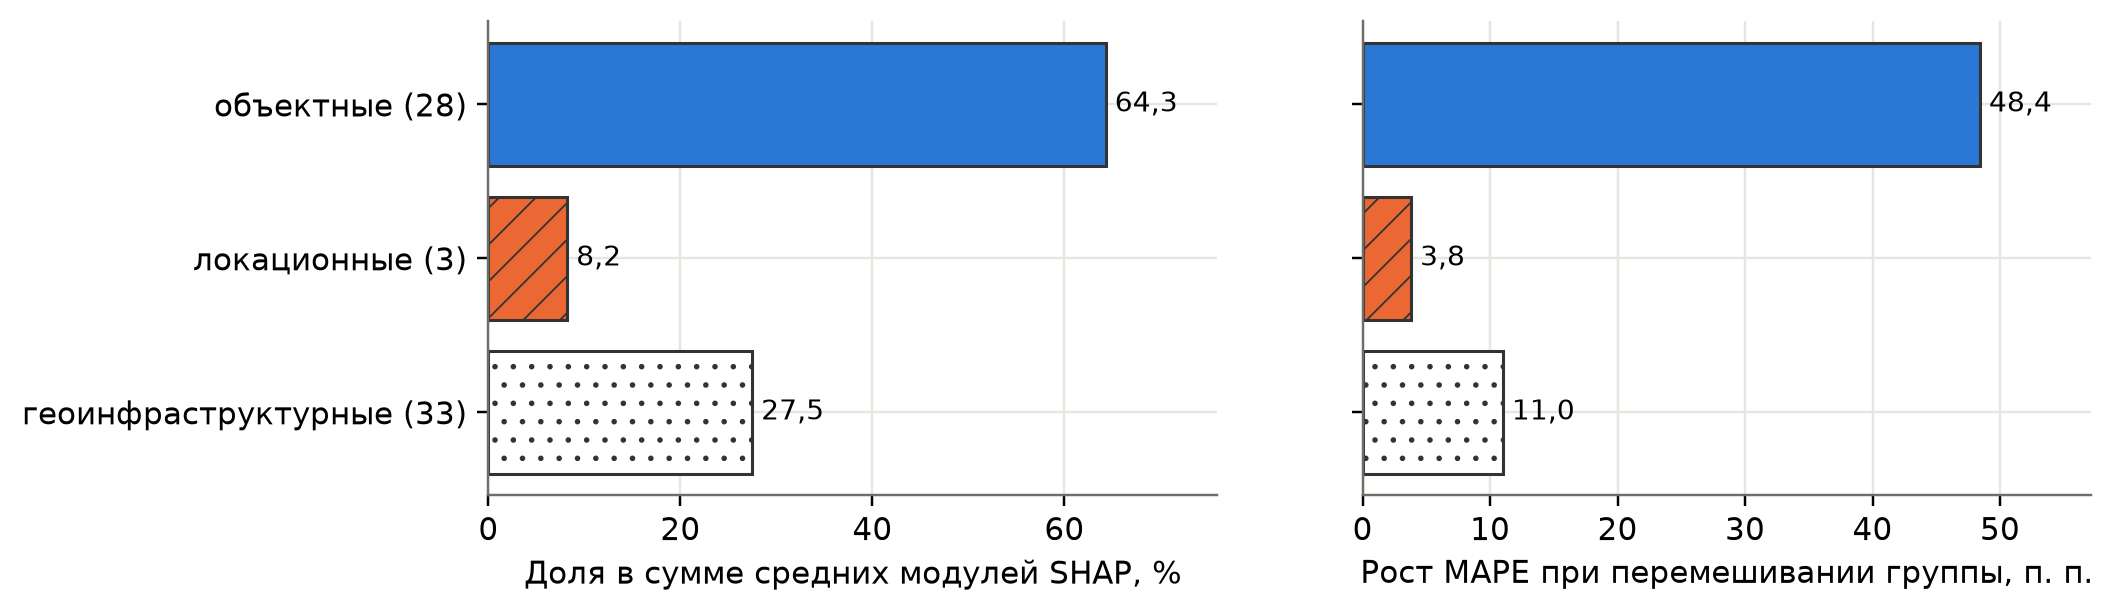

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 2.8))
gi = group_imp.set_index("group")
for a, col, lab in ((ax[0], "shap_share_%", "Доля в сумме средних модулей SHAP, %"), (ax[1], "perm_dMAPE_пп", "Рост MAPE при перемешивании группы, п. п.")):
    for i, g in enumerate(gi.index[::-1]):
        c, h = GROUP_STYLE[g]
        a.barh(i, gi.loc[g, col], color=c, edgecolor="#333", hatch=h)
        a.text(gi.loc[g, col], i, " " + ru(gi.loc[g, col], 1), va="center", fontsize=9)
    a.set_yticks(range(len(gi)), [f"{g} ({int(gi.loc[g, 'n_features'])})" for g in gi.index[::-1]])
    a.set_xlabel(lab)
    a.set_xlim(0, gi[col].max() * 1.18)
ax[1].set_yticklabels([])
savefig("fig16_group_importance", "Важность трёх групп признаков (в скобках — число признаков): доля в сумме средних модулей SHAP и рост MAPE при совместном перемешивании группы на тесте. "
        "Объектные признаки доминируют; локационные и геоинфраструктурные делят между собой информацию о положении.")

## 13. Анализ ошибок · `шаг 8`
Ошибки лучшей модели на отложенном тесте: по сегментам, остатки, десять худших прогнозов.

In [30]:
rel_err = (best_pred - y_test) / y_test * 100
ape = np.abs(rel_err)
resid = {
    "n_test": len(y_test), "MAPE_%": float(ape.mean()), "MdAPE_%": float(np.median(ape)), "mean_error_%": float(rel_err.mean()),
    "median_error_%": float(np.median(rel_err)), "share_within_5_%": float((ape <= 5).mean() * 100), "share_within_10_%": float((ape <= 10).mean() * 100),
    "share_within_20_%": float((ape <= 20).mean() * 100), "share_over_30_%": float((ape > 30).mean() * 100), "share_over_50_%": float((ape > 50).mean() * 100),
    "ape_q90_%": float(np.quantile(ape, 0.9)), "ape_q95_%": float(np.quantile(ape, 0.95)), "ape_max_%": float(ape.max()),
    "share_overestimated_%": float((rel_err > 0).mean() * 100), "log_resid_std": float(np.std(np.log(best_pred) - np.log(y_test))),
    "corr_abs_err_price_spearman": float(stats.spearmanr(ape, y_test).statistic),
}
seg = A.segment_errors(test, y_test, best_pred)
seg = pd.concat([seg, A.error_table(y_test, best_pred, np.where(seen_house, "дом есть в обучении", "дом новый для модели"), "дом (координаты)")], ignore_index=True)
save_csv(seg, "errors_by_segment.csv")
for name in seg["segment"].unique():
    table(seg[seg["segment"] == name].drop(columns="segment").set_index("value"), f"Ошибки на тесте · {name}", digits=2, bars=["MAPE_%"])

#### ▶ Ошибки на тесте · район

,n,MAPE_%,MdAPE_%,MAE_млн,смещение_%,медиана_цены_млн
value,,,,,,
Алматы,405,9.56,7.09,4.02,0.42,30.50
Байконур,178,9.90,7.49,3.67,0.54,29.90
Есиль,781,9.89,7.54,6.80,0.23,49.90
Нура,996,8.97,7.06,5.03,0.83,38.65
Сарайшык,585,8.74,6.45,4.24,0.85,35.00
Сарыарка,411,9.20,7.53,3.08,0.01,25.99


#### ▶ Ошибки на тесте · комнаты

,n,MAPE_%,MdAPE_%,MAE_млн,смещение_%,медиана_цены_млн
value,,,,,,
1,776,7.92,5.92,1.73,0.00,23.37
2,1 214,8.31,6.37,3.13,0.50,33.90
3,991,10.59,8.61,6.40,1.32,50.00
4,314,11.81,9.67,12.01,-0.14,87.00
5,54,12.59,13.12,17.01,-1.02,131.45
6,7,12.20,14.81,24.80,-7.68,140.00


#### ▶ Ошибки на тесте · ценовой квинтиль

,n,MAPE_%,MdAPE_%,MAE_млн,смещение_%,медиана_цены_млн
value,,,,,,
Q1 (дешёвые),672,8.84,6.20,1.61,3.90,20.50
Q2,671,8.02,6.16,2.24,1.13,28.00
Q3,687,8.47,6.79,3.10,0.90,36.00
Q4,658,9.29,7.30,4.70,0.16,50.00
Q5 (дорогие),668,11.89,9.64,12.79,-3.49,88.00


... (2 outputs left out)

#### ▶ Ошибки на тесте · новостройки / старый фонд

,n,MAPE_%,MdAPE_%,MAE_млн,смещение_%,медиана_цены_млн
value,,,,,,
старый фонд (до 2020),1 372,10.11,7.75,5.15,0.99,34.50
новостройки (2020+),1 984,8.73,6.79,4.68,0.21,37.50


#### ▶ Ошибки на тесте · дом (координаты)

,n,MAPE_%,MdAPE_%,MAE_млн,смещение_%,медиана_цены_млн
value,,,,,,
дом есть в обучении,2 004,9.08,6.87,4.52,0.66,35.40
дом новый для модели,1 352,9.61,7.44,5.39,0.33,37.67


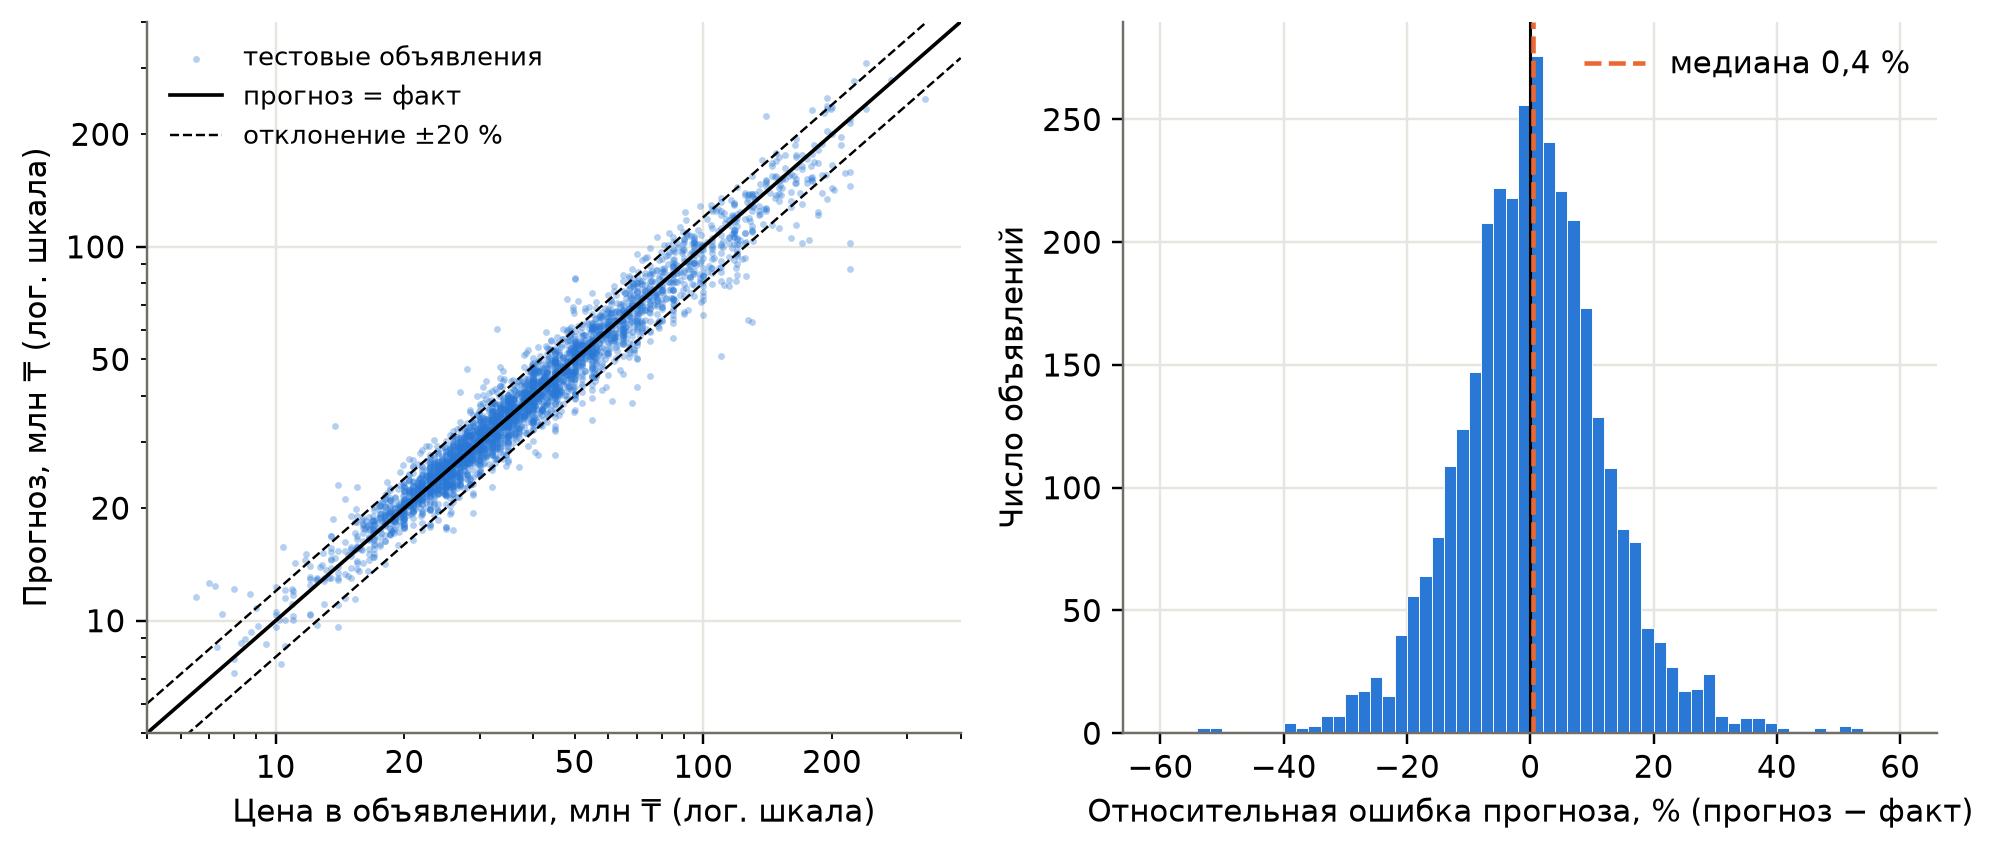

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
lim = [5, 400]
ax[0].scatter(y_test / 1e6, best_pred / 1e6, s=5, color=BLUE, alpha=0.35, linewidths=0, label="тестовые объявления")
ax[0].plot(lim, lim, color="black", lw=1.2, label="прогноз = факт")
ax[0].plot(lim, [v * 1.2 for v in lim], color="black", lw=0.8, ls="--", label="отклонение ±20 %")
ax[0].plot(lim, [v * 0.8 for v in lim], color="black", lw=0.8, ls="--")
ax[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Цена в объявлении, млн ₸ (лог. шкала)", ylabel="Прогноз, млн ₸ (лог. шкала)")
for a_ in (ax[0].xaxis, ax[0].yaxis):
    a_.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    a_.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}" if v in (20, 50, 200) else ""))
ax[0].legend(loc="upper left", fontsize=8.5)
ax[1].hist(rel_err, bins=60, range=(-60, 60), color=BLUE, edgecolor="white", linewidth=0.3)
ax[1].axvline(0, color="black", lw=1)
ax[1].axvline(np.median(rel_err), color=ORANGE, ls="--", lw=1.5, label=f"медиана {ru(np.median(rel_err), 1)} %")
ax[1].set(xlabel="Относительная ошибка прогноза, % (прогноз − факт)", ylabel="Число объявлений")
ax[1].legend()
savefig("fig17_actual_vs_predicted", "Слева — прогноз против цены в объявлении (логарифмические шкалы, пунктир — отклонение ±20 %), справа — распределение относительной ошибки в пределах ±60 %: "
        "точки лежат вдоль диагонали без систематического сдвига, распределение ошибок близко к симметричному.")

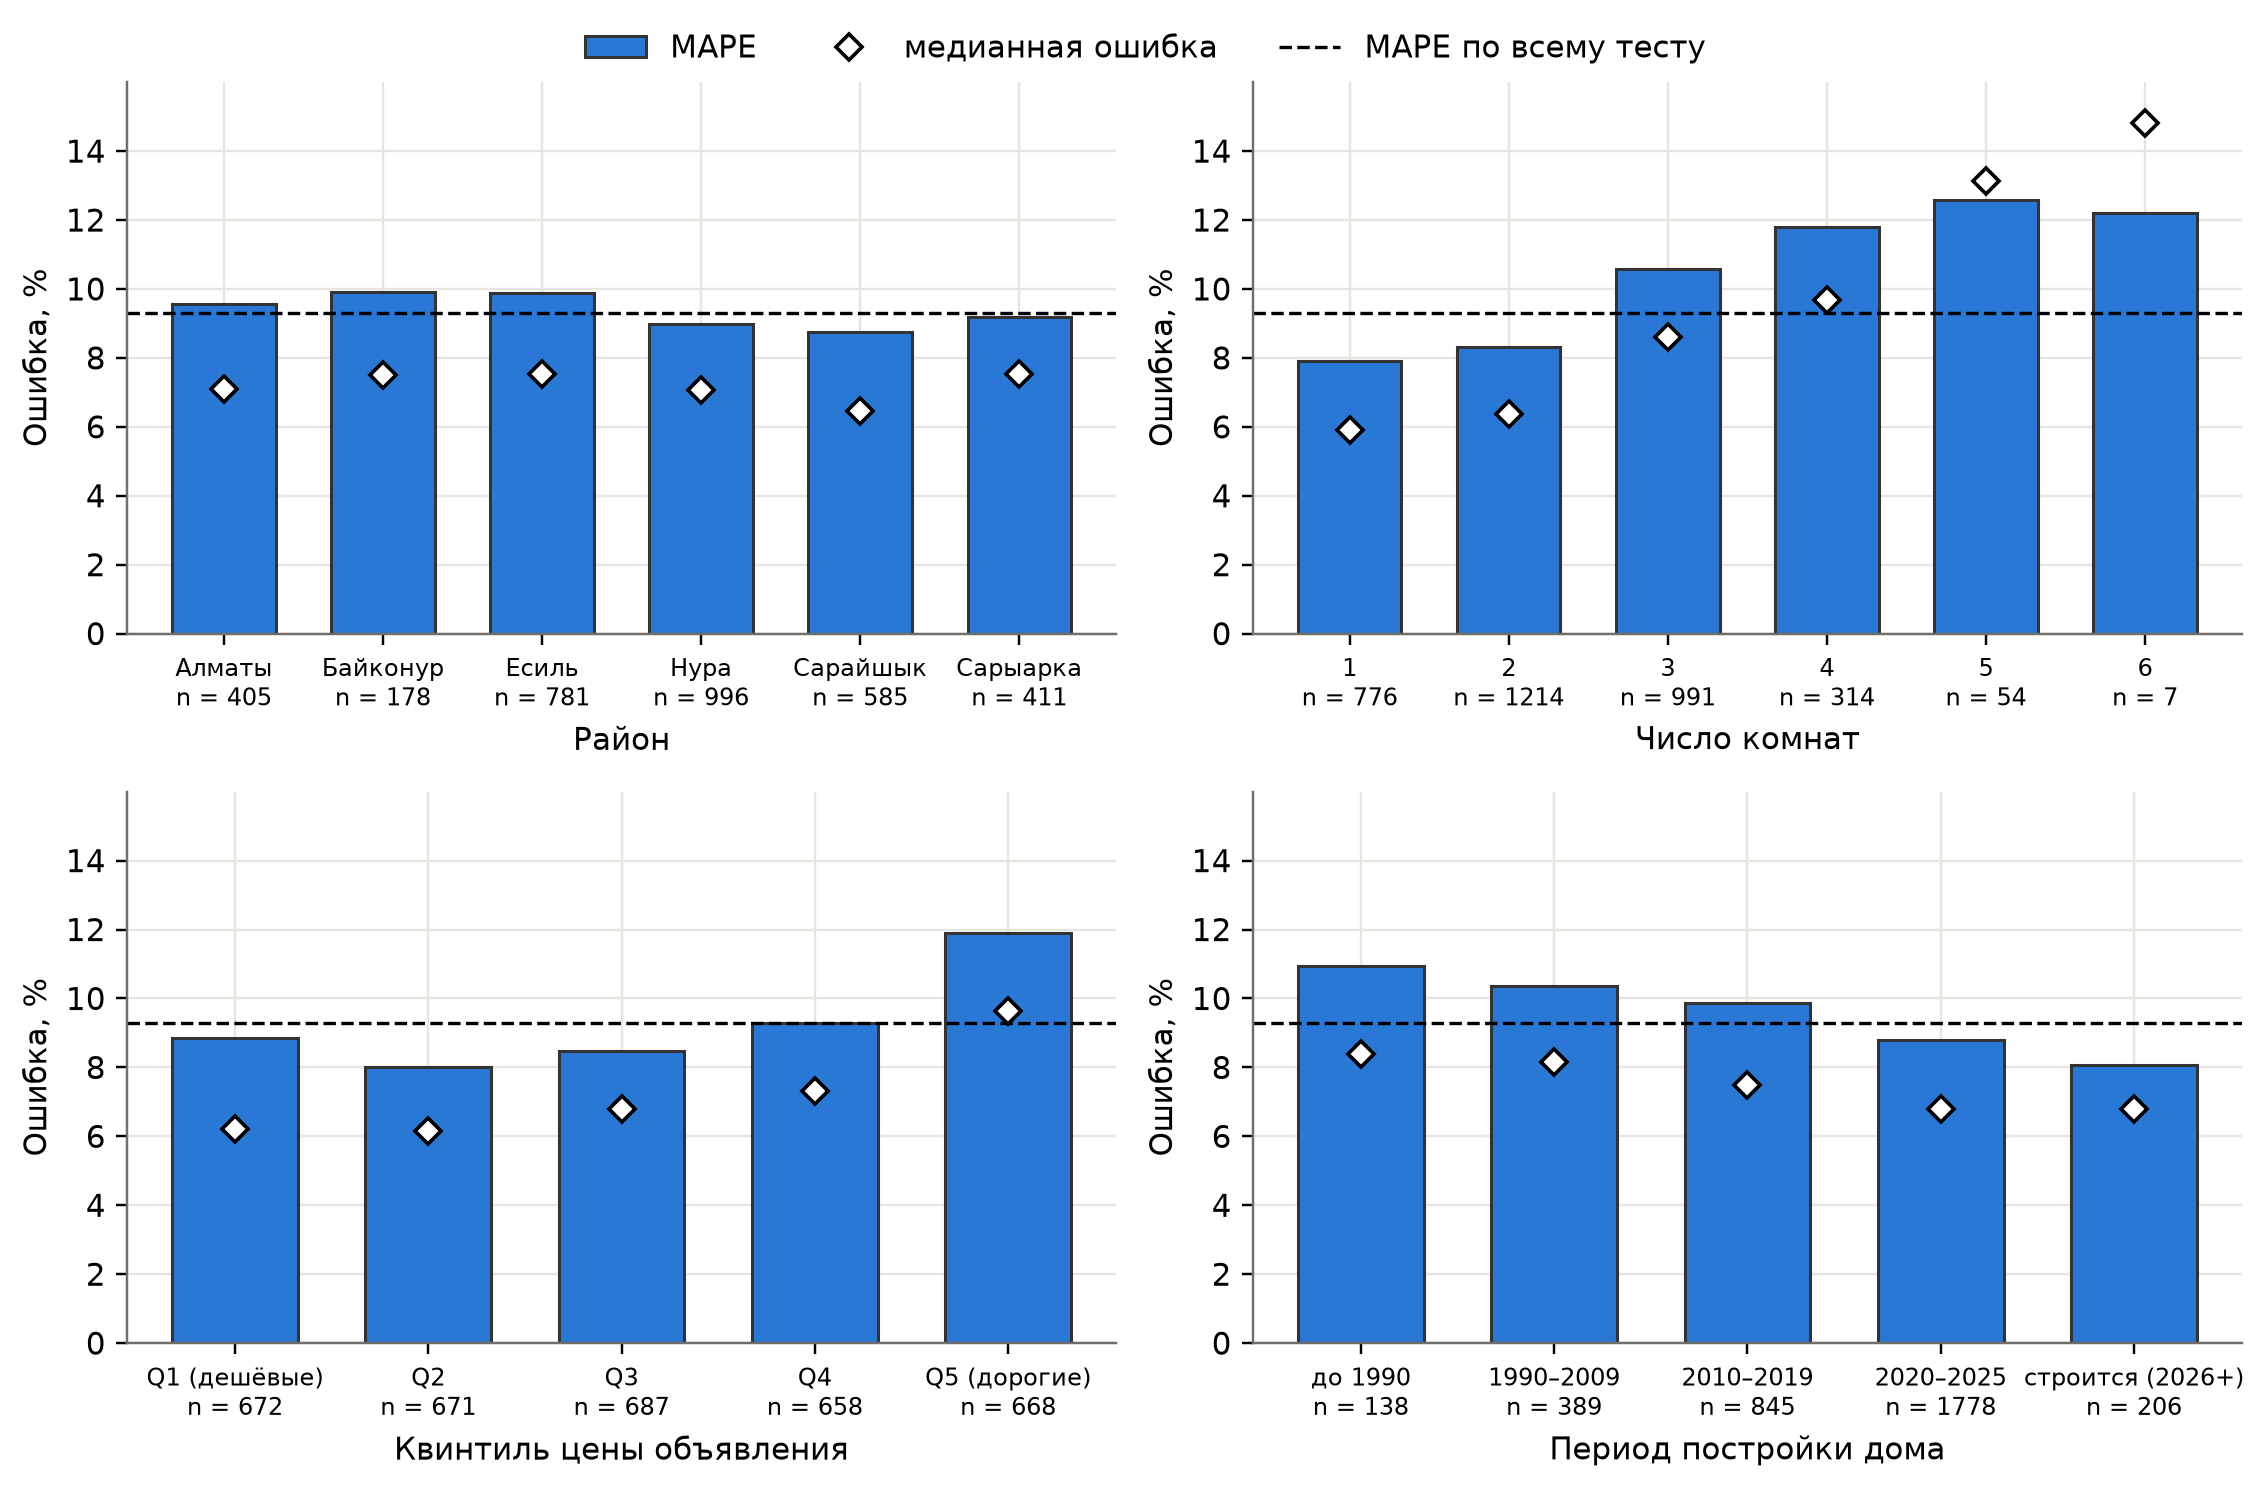

In [32]:
fig, ax = plt.subplots(2, 2, figsize=(10.5, 6.6))
SEG4 = ("район", "комнаты", "ценовой квинтиль", "период постройки")
ymax = seg.loc[seg["segment"].isin(SEG4), ["MAPE_%", "MdAPE_%"]].max().max() * 1.08
for a, name, xl_ in zip(ax.ravel(), SEG4, ("Район", "Число комнат", "Квинтиль цены объявления", "Период постройки дома")):
    d = seg[seg["segment"] == name]
    h1 = a.bar(range(len(d)), d["MAPE_%"], color=BLUE, edgecolor="#333", width=0.65, label="MAPE")
    h2, = a.plot(range(len(d)), d["MdAPE_%"], color="white", marker="D", ms=6, mec="black", mew=1.2, ls="none", label="медианная ошибка")
    h3 = a.axhline(resid["MAPE_%"], color="black", ls="--", lw=1.1, label="MAPE по всему тесту")
    a.set_xticks(range(len(d)), [f"{v}\nn = {n}" for v, n in zip(d["value"], d["n"])], fontsize=8)
    a.set(xlabel=xl_, ylabel="Ошибка, %", ylim=(0, ymax))
fig.legend(handles=[h1, h2, h3], loc="upper center", ncols=3, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
savefig("fig18_errors_by_segment", "MAPE (столбцы) и медианная абсолютная ошибка (ромбы) на тесте по районам, числу комнат, ценовым квинтилям и периоду постройки; пунктир — MAPE по всему тесту. "
        "Ошибка растёт с числом комнат и с ценой квартиры (наибольшая — в верхнем ценовом квинтиле) и выше в старом жилом фонде; между районами различия невелики.")

In [33]:
worst = A.worst_cases(test, y_test, best_pred, 10)
save_csv(worst, "worst_cases.csv")
table(worst.drop(columns="listing_id"), "Десять худших прогнозов на тесте", digits=1)

# Что общего у худших: сравнение худшего 1 % с тестом в целом
k_worst = max(10, round(0.01 * len(test)))
w = np.argsort(-ape)[:k_worst]
house_n = train.groupby(["latitude", "longitude"]).size()
n_same = np.array([house_n.get((a, b), 0) for a, b in zip(test["latitude"], test["longitude"])])
dmed = train.groupby("district")["price_per_m2_kzt"].median()
ppm2_rel = test["price_per_m2_kzt"].to_numpy() / test["district"].map(dmed).to_numpy()
traits = {
    "прогноз выше цены объявления, %": rel_err > 0, "цена за м² ниже 60 % медианы района, %": ppm2_rel < 0.6,
    "цена за м² выше 160 % медианы района, %": ppm2_rel > 1.6, "дом новый для модели (координат нет в обучении), %": ~seen_house,
    "ЖК не указан, %": test["in_complex"].to_numpy() == 0, "этаж не указан, %": test["floor"].isna().to_numpy(),
    "состояние не указано, %": (test["condition"] == cleaning.NO_VALUE).to_numpy(), "площадь больше 120 м², %": test["area"].to_numpy() > 120,
    "площадь меньше 30 м², %": test["area"].to_numpy() < 30, "дом до 1990 года, %": test["year_built"].to_numpy() < 1990,
    "дом строится, %": test["under_construction"].to_numpy() == 1,
}
worst_common = pd.DataFrame({"10 худших": {k: v[w[:10]].mean() * 100 for k, v in traits.items()},
                             f"худший 1 % ({k_worst})": {k: v[w].mean() * 100 for k, v in traits.items()},
                             "весь тест": {k: v.mean() * 100 for k, v in traits.items()}})
worst_common.index.name = "признак случая"
save_csv(worst_common, "worst_cases_common.csv", index=True)
worst_info = {"k_worst_1pct": int(k_worst), "worst10_min_abs_error_%": float(ape[w[9]]), "worst10_max_abs_error_%": float(ape[w[0]]),
              "worst1pct_min_abs_error_%": float(ape[w[-1]]), "worst10_overestimated": int((rel_err[w[:10]] > 0).sum()),
              "worst10_median_ppm2_to_district": float(np.median(ppm2_rel[w[:10]])), "worst1pct_median_ppm2_to_district": float(np.median(ppm2_rel[w]))}
table(worst_common, f"Что общего у худших прогнозов (доля случаев с признаком, %) · у 10 худших ошибка от {worst_info['worst10_min_abs_error_%']:.0f} до {worst_info['worst10_max_abs_error_%']:.0f} %", digits=1)

#### ▶ Десять худших прогнозов на тесте

,district,residential_complex_name,rooms,area,floor,total_floors,year_built,house_type,condition,dist_center_km,цена_млн,прогноз_млн,ошибка_%,цена_за_м2_тыс
0,Сарайшык,Азия Плюс,3,65.8,11.0,11.0,2 020,кирпичный,требует ремонта,3.5,13.8,33.2,140.3,209.7
1,Есиль,Uly Dala Park | Life,2,61.9,6.0,14.0,2 025,монолитный,не указано,3.6,33.0,60.2,82.4,532.8
2,Алматы,Восточный,1,17.0,1.0,10.0,2 009,кирпичный,свежий ремонт,5.4,7.0,12.6,80.5,411.8
3,Алматы,Отау,1,18.3,1.0,10.0,2 005,монолитный,не указано,5.7,6.5,11.6,77.8,355.2
4,Алматы,не указано,1,30.0,—,—,1 977,кирпичный,не указано,5.0,7.2,12.4,72.5,240.0
5,Сарайшык,Алтын Отау,3,132.0,9.0,9.0,2 021,монолитный,не указано,8.0,28.0,47.2,68.7,212.1
6,Есиль,Комфорт De Luxe,3,102.6,9.0,19.0,2 019,монолитный,свежий ремонт,2.1,50.0,82.6,65.1,487.3
7,Нура,не указано,3,63.0,4.0,4.0,2 016,кирпичный,не указано,13.0,14.0,23.1,65.0,222.2
8,Нура,Эдем,3,90.0,6.0,12.0,2 019,монолитный,не указано,2.4,50.0,82.0,63.9,555.6
9,Нура,Нурлы Дала,4,145.0,7.0,8.0,2 005,монолитный,не указано,1.3,220.0,87.1,-60.4,1 517.2


#### ▶ Что общего у худших прогнозов (доля случаев с признаком, %) · у 10 худших ошибка от 60 до 140 %

,10 худших,худший 1 % (34),весь тест
признак случая,,,
"прогноз выше цены объявления, %",90.0,67.6,51.6
"цена за м² ниже 60 % медианы района, %",40.0,29.4,2.0
"цена за м² выше 160 % медианы района, %",10.0,23.5,5.0
"дом новый для модели (координат нет в обучении), %",40.0,50.0,40.3
"ЖК не указан, %",20.0,38.2,20.6
"этаж не указан, %",10.0,2.9,6.3
"состояние не указано, %",70.0,73.5,58.4
"площадь больше 120 м², %",20.0,17.6,9.8
"площадь меньше 30 м², %",20.0,11.8,1.7


## 14. Итоговая модель и прототип сервиса · `шаг 9`
Пакет `models/price_model.joblib`: две модели (набор E — если заданы координаты; набор B — если известен только район), геоиндекс OSM и квантили отношения «факт / прогноз» на тесте для интервала. Интерфейс — `predict.py` (функция и командная строка).

In [34]:
assert BEST == P.FINAL_KIND, "итоговая модель в src/pipeline.py должна совпадать с лучшей по перекрёстной проверке"
bundle = cached("bundle", lambda: P.train_bundle(data, geo, PARAMS[BEST], SEED, BEST), FP_A)
bundle_path = P.save_bundle(bundle)
import predict as service

final_info = {
    "kind": BEST, "model": M.MODEL_LABELS[BEST], "params": PARAMS[BEST], "file": str(bundle_path.relative_to(C.ROOT)), "file_mb": bundle_path.stat().st_size / 1e6,
    "metrics": {k: {m: v for m, v in d.items()} for k, d in bundle["metrics"].items()}, "intervals_ratio_quantiles": bundle["intervals"],
    "coverage_80_cross_check": bundle["coverage_80"],
    "interval_80_width_%": {k: (q["q90"] - q["q10"]) * 100 for k, q in bundle["intervals"].items()},
    "interval_90_width_%": {k: (q["q95"] - q["q05"]) * 100 for k, q in bundle["intervals"].items()},
}
save_json(final_info, "final_model.json")
table(pd.DataFrame({k: {**{m: bundle["metrics"][k][m] for m in ("MAE_млн", "RMSE_млн", "MAPE_%", "MdAPE_%", "R2")}, "q10": bundle["intervals"][k]["q10"],
                        "q90": bundle["intervals"][k]["q90"], "покрытие 80 %-го интервала": bundle["coverage_80"][k]} for k in bundle["models"]}).T
      .rename(index={"full": "с координатами (набор E)", "district": "только район (набор B)"}),
      f"Итоговый пакет · {M.MODEL_LABELS[BEST]} · {final_info['file_mb']:.1f} МБ")

SCENARIOS = {
    "2-комн. в новом монолитном доме у «Байтерека»": {"area": 62, "rooms": 2, "floor": 7, "total_floors": 12, "year_built": 2019, "house_type": "монолитный", "latitude": 51.1283, "longitude": 71.4305},
    "1-комн. в панельном доме 1985 г., известен только район": {"area": 45, "rooms": 1, "floor": 3, "total_floors": 5, "year_built": 1985, "house_type": "панельный", "district": "Сарыарка"},
    "3-комн. в строящемся доме, минимум сведений": {"area": 80, "rooms": 3, "year_built": 2026, "district": "Нура"},
    "Некорректный ввод: этаж выше этажности": {"area": 62, "rooms": 2, "floor": 15, "total_floors": 9, "year_built": 2015, "district": "Есиль"},
    "Некорректный ввод: точка вне Астаны": {"area": 62, "rooms": 2, "year_built": 2015, "latitude": 43.24, "longitude": 76.9},
}
examples, rows = {}, []
for name, flat in SCENARIOS.items():
    try:
        r = service.predict(flat, bundle=bundle)
        examples[name] = {"input": flat, "output": r}
        rows.append({"сценарий": name, "модель": f"набор {r['feature_set']}", "прогноз, млн ₸": r["price"] / 1e6, "интервал 80 %, млн ₸": f"{r['interval_80'][0] / 1e6:.1f} – {r['interval_80'][1] / 1e6:.1f}",
                     "главные факторы": "; ".join(f"{f['label']} {f['effect_%']:+.0f} %" for f in r["factors"][:3])})
    except ValueError as ex:
        examples[name] = {"input": flat, "error": str(ex)}
        rows.append({"сценарий": name, "модель": "—", "главные факторы": f"отказ: {ex}"})
save_json(examples, "predict_examples.json")
table(pd.DataFrame(rows).set_index("сценарий"), "Работа сервиса на пяти сценариях", digits=2)

#### ▶ Итоговый пакет · CatBoost · 1.9 МБ

,MAE_млн,RMSE_млн,MAPE_%,MdAPE_%,R2,q10,q90,покрытие 80 %-го интервала
с координатами (набор E),4.871,9.374,9.295,7.107,0.926,0.871,1.165,0.800
только район (набор B),6.732,12.317,12.966,9.905,0.872,0.819,1.232,0.800


#### ▶ Работа сервиса на пяти сценариях

,модель,"прогноз, млн ₸","интервал 80 %, млн ₸",главные факторы
сценарий,,,,
2-комн. в новом монолитном доме у «Байтерека»,набор E,54.19,47.2 – 63.1,"До центра, км +19 %; Год постройки +9 %; Район +8 %"
"1-комн. в панельном доме 1985 г., известен только район",набор B,17.53,14.4 – 21.6,Площадь -25 %; Год постройки -11 %; Комнат -11 %
"3-комн. в строящемся доме, минимум сведений",набор B,43.67,35.8 – 53.8,Этажность -9 %; Площадь +10 %; Комнат +6 %
Некорректный ввод: этаж выше этажности,—,—,—,отказ: этаж (15) больше этажности дома (9)
Некорректный ввод: точка вне Астаны,—,—,—,"отказ: точка (43.24, 76.9) лежит вне границ районов Астаны"


In [35]:
# Автотесты (unittest): очистка, утечки, воспроизводимость, сервис
run = subprocess.run([sys.executable, "tests/run_tests.py"], cwd=C.ROOT, capture_output=True, text=True, env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1"})
tests_info = json.loads((C.RESULTS / "tests.json").read_text(encoding="utf-8"))
assert run.returncode == 0, run.stderr[-3000:]
table(pd.DataFrame({"тестов": tests_info["per_module"]}).T.assign(всего=tests_info["total"], пройдено=tests_info["passed"], **{"не пройдено": tests_info["failed"] + tests_info["errors"]}),
      f"Автотесты: всего {tests_info['total']}, пройдено {tests_info['passed']} · {tests_info['time_s']:.0f} с", digits=0)

#### ▶ Автотесты: всего 42, пройдено 42 · 13 с

,test_cleaning,test_features,test_models,test_predict,всего,пройдено,не пройдено
тестов,14,11,8,9,42,42,0


## 15. Итоги · `шаг 10`
Сводка ключевых и производных чисел (`results/summary.json`), проверка гипотез, список рисунков, время счёта.

In [36]:
mt, mc, ms, ml = (d.set_index("model") for d in (metrics_test, metrics_cv, metrics_spatial, metrics_lodo))
SECOND = "hgb" if BEST == "catboost" else "catboost"


def step(model, scheme, a, b, metric="MAPE_%"):
    r = abl_tests[(abl_tests["model"] == model) & (abl_tests["scheme"] == scheme) & (abl_tests["metric"] == metric) & (abl_tests["A"] == a) & (abl_tests["B"] == b)].iloc[0]
    return {"from": float(r["mean_A"]), "to": float(r["mean_B"]), "improvement": float(r["improvement"]), "improvement_rel_%": float(r["improvement_rel_%"]),
            "folds_better": int(r["folds_B_better"]), "n_folds": int(r["n_folds"]), "p_wilcoxon": float(r["p_wilcoxon"]), "p_holm": float(r["p_holm"]),
            **({"p_NB": float(r["p_NB"])} if "p_NB" in r and r["p_NB"] == r["p_NB"] else {})}


def pair_p(a, b, scheme="cv", metric="MAPE_%"):
    r = stat_pairs[(stat_pairs["scheme"] == scheme) & (stat_pairs["metric"] == metric) & (((stat_pairs["A"] == a) & (stat_pairs["B"] == b)) | ((stat_pairs["A"] == b) & (stat_pairs["B"] == a)))].iloc[0]
    return {"p_wilcoxon": float(r["p_wilcoxon"]), "p_holm": float(r["p_holm"]), "p_NB": float(r["p_NB"]) if "p_NB" in r and r["p_NB"] == r["p_NB"] else None,
            "abs_diff": float(abs(r["diff_A_minus_B"]))}


abl = {m: {s: {f"{a}→{b}": step(m, s, a, b) for a, b in STEPS} for s in ("cv", "spatial")} | {"spatial10": {"D→E": step(m, "spatial10", "D", "E")}}
       | {"lodo": {"D→E": step(m, "lodo", "D", "E"), "D→A+OSM": step(m, "lodo", "D", "A+OSM")}} for m in ABL_MODELS}
abl_mae = {m: {s: {"D→E": step(m, s, "D", "E", "MAE_млн")} for s in ("cv", "spatial", "spatial10")} for m in ABL_MODELS}
ab = abl_summary.set_index(["model", "feature_set", "scheme"])
seg_i = seg.set_index(["segment", "value"])
quint, distr, yearp = seg[seg["segment"] == "ценовой квинтиль"], seg[seg["segment"] == "район"], seg[seg["segment"] == "период постройки"]
gi = group_imp.set_index("group")
cxv = complex_variant.set_index(["model", "scheme"])

summary = {
    "seed": SEED, "best_model": BEST, "best_model_label": M.MODEL_LABELS[BEST], "target": "log(price_local); метрики в тенге",
    "data": {k: data_summary[k] for k in ("rows_raw", "rows_clean", "rows_removed", "rows_removed_%", "duplicates_total", "outside_city", "outliers_removed",
                                         "under_construction", "under_construction_%", "district_agreement_%", "features_total", "features_object",
                                         "features_location", "features_geo", "price_median_mln", "ppm2_median_k")},
    "split": {k: split_info[k] for k in ("n_train", "n_test", "cv_folds", "spatial_folds", "spatial_cells", "spatial_cells_shifted", "spatial_shift_km", "spatial_folds_D_vs_E", "spatial2_same_fold_share_%", "spatial_test_within_300m_of_train_%_min", "spatial_test_within_300m_of_train_%_max", "spatial_test_within_300m_of_train_%_mean", "lodo_folds", "test_rows_with_house_in_train_%", "test_rows_new_house_%")},
    "osm": {"objects_received_total": osm_info["objects_received_total"], "poi_received": osm_info["poi_received"], "poi_used_in_features": osm_info["poi_used_in_features"],
            "layers_used": dict(zip(osm_layers["layer"], osm_layers["использовано"].astype(int)))},
    "test": {k: {m: float(mt.loc[k, m]) for m in M.METRIC_COLS} for k in M.MODEL_ORDER},
    "cv": {k: {f"{m}_{s}": float(mc.loc[k, f"{m}_{s}"]) for m in M.METRIC_COLS for s in ("mean", "std")} for k in M.MODEL_ORDER},
    "spatial": {k: {f"{m}_{s}": float(ms.loc[k, f"{m}_{s}"]) for m in M.METRIC_COLS for s in ("mean", "std")} for k in M.MODEL_ORDER},
    "lodo": {k: {f"{m}_{s}": float(ml.loc[k, f"{m}_{s}"]) for m in ("MAPE_%", "MAE_млн", "R2") for s in ("mean", "std")} for k in M.MODEL_ORDER},
    "derived_models": {
        "test_MAPE_best_minus_baseline_пп": float(mt.loc[BEST, "MAPE_%"] - mt.loc["baseline", "MAPE_%"]),
        "test_MAPE_reduction_vs_baseline_%": float((1 - mt.loc[BEST, "MAPE_%"] / mt.loc["baseline", "MAPE_%"]) * 100),
        "test_MAPE_baseline_to_best_ratio": float(mt.loc["baseline", "MAPE_%"] / mt.loc[BEST, "MAPE_%"]),
        "test_MAPE_reduction_vs_ridge_%": float((1 - mt.loc[BEST, "MAPE_%"] / mt.loc["ridge", "MAPE_%"]) * 100),
        "test_MAPE_best_minus_ridge_пп": float(mt.loc[BEST, "MAPE_%"] - mt.loc["ridge", "MAPE_%"]),
        "test_MAPE_ridge_minus_best_пп": float(mt.loc["ridge", "MAPE_%"] - mt.loc[BEST, "MAPE_%"]),
        "test_MAPE_baseline_minus_best_пп": float(mt.loc["baseline", "MAPE_%"] - mt.loc[BEST, "MAPE_%"]),
        "test_MAE_reduction_vs_baseline_%": float((1 - mt.loc[BEST, "MAE_млн"] / mt.loc["baseline", "MAE_млн"]) * 100),
        "test_MAE_reduction_vs_ridge_%": float((1 - mt.loc[BEST, "MAE_млн"] / mt.loc["ridge", "MAE_млн"]) * 100),
        "test_MAE_best_minus_baseline_млн": float(mt.loc[BEST, "MAE_млн"] - mt.loc["baseline", "MAE_млн"]),
        "test_RMSE_reduction_vs_baseline_%": float((1 - mt.loc[BEST, "RMSE_млн"] / mt.loc["baseline", "RMSE_млн"]) * 100),
        "cv_MAPE_reduction_vs_baseline_%": float((1 - mc.loc[BEST, "MAPE_%_mean"] / mc.loc["baseline", "MAPE_%_mean"]) * 100),
        "cv_MAPE_reduction_vs_ridge_%": float((1 - mc.loc[BEST, "MAPE_%_mean"] / mc.loc["ridge", "MAPE_%_mean"]) * 100),
        "cv_MAPE_best_minus_second_пп": float(mc.loc[BEST, "MAPE_%_mean"] - mc.loc[SECOND, "MAPE_%_mean"]), "second_model": SECOND,
        "cv_best_vs_second": pair_p(BEST, SECOND), "cv_best_vs_rf": pair_p(BEST, "rf"), "cv_best_vs_ridge": pair_p(BEST, "ridge"),
        "cv_rf_vs_ridge": pair_p("rf", "ridge"), "cv_hgb_vs_ridge": pair_p("hgb", "ridge"), "cv_ridge_vs_baseline": pair_p("ridge", "baseline"),
        "spatial_minus_cv_MAPE_пп": {k: float(ms.loc[k, "MAPE_%_mean"] - mc.loc[k, "MAPE_%_mean"]) for k in M.MODEL_ORDER},
        "spatial_to_cv_MAPE_ratio": {k: float(ms.loc[k, "MAPE_%_mean"] / mc.loc[k, "MAPE_%_mean"]) for k in M.MODEL_ORDER},
        "lodo_minus_cv_MAPE_пп": {k: float(ml.loc[k, "MAPE_%_mean"] - mc.loc[k, "MAPE_%_mean"]) for k in M.MODEL_ORDER},
        "spatial_MAPE_reduction_vs_baseline_%": float((1 - ms.loc[BEST, "MAPE_%_mean"] / ms.loc["baseline", "MAPE_%_mean"]) * 100),
        "spatial_MAPE_reduction_vs_ridge_%": float((1 - ms.loc[BEST, "MAPE_%_mean"] / ms.loc["ridge", "MAPE_%_mean"]) * 100),
        "friedman_cv_MAPE_p": float(stat_friedman.loc[(stat_friedman["scheme"] == "cv") & (stat_friedman["metric"] == "MAPE_%"), "p"].iloc[0]),
        "friedman_cv_MAPE_chi2": float(stat_friedman.loc[(stat_friedman["scheme"] == "cv") & (stat_friedman["metric"] == "MAPE_%"), "friedman_chi2"].iloc[0]),
        "min_possible_p_wilcoxon_15_folds": 2 / 2 ** 15, "min_possible_p_wilcoxon_10_folds": 2 / 2 ** 10, "min_possible_p_wilcoxon_6_folds": 2 / 2 ** 6,
        "min_possible_p_wilcoxon_5_folds": 2 / 2 ** 5,
    },
    "ablation_MAPE": abl, "ablation_MAE_D_to_E": abl_mae,
    "ablation_derived": {m: {
        "cv_A_to_E_improvement_пп": float(ab.loc[(m, "A", "cv"), "MAPE_%_mean"] - ab.loc[(m, "E", "cv"), "MAPE_%_mean"]),
        "cv_A_to_E_improvement_rel_%": float((1 - ab.loc[(m, "E", "cv"), "MAPE_%_mean"] / ab.loc[(m, "A", "cv"), "MAPE_%_mean"]) * 100),
        "cv_A_to_D_improvement_пп": float(ab.loc[(m, "A", "cv"), "MAPE_%_mean"] - ab.loc[(m, "D", "cv"), "MAPE_%_mean"]),
        "cv_share_of_A_to_E_gain_from_OSM_%": float(abl[m]["cv"]["D→E"]["improvement"] / (ab.loc[(m, "A", "cv"), "MAPE_%_mean"] - ab.loc[(m, "E", "cv"), "MAPE_%_mean"]) * 100),
        "spatial_A_to_E_improvement_пп": float(ab.loc[(m, "A", "spatial"), "MAPE_%_mean"] - ab.loc[(m, "E", "spatial"), "MAPE_%_mean"]),
        "spatial_share_of_A_to_E_gain_from_OSM_%": float(abl[m]["spatial"]["D→E"]["improvement"] / (ab.loc[(m, "A", "spatial"), "MAPE_%_mean"] - ab.loc[(m, "E", "spatial"), "MAPE_%_mean"]) * 100),
        "test_D_MAPE": float(ab.loc[(m, "D", "cv"), "MAPE_%_test"]), "test_E_MAPE": float(ab.loc[(m, "E", "cv"), "MAPE_%_test"]),
        "test_D_to_E_improvement_пп": float(ab.loc[(m, "D", "cv"), "MAPE_%_test"] - ab.loc[(m, "E", "cv"), "MAPE_%_test"]),
        "test_D_to_E_improvement_rel_%": float((1 - ab.loc[(m, "E", "cv"), "MAPE_%_test"] / ab.loc[(m, "D", "cv"), "MAPE_%_test"]) * 100),
        "test_A_MAPE": float(ab.loc[(m, "A", "cv"), "MAPE_%_test"]), "test_AOSM_MAPE": float(ab.loc[(m, "A+OSM", "cv"), "MAPE_%_test"]),
        "test_D_MAE_млн": float(ab.loc[(m, "D", "cv"), "MAE_млн_test"]), "test_E_MAE_млн": float(ab.loc[(m, "E", "cv"), "MAE_млн_test"]),
        "test_D_to_E_MAE_improvement_млн": float(ab.loc[(m, "D", "cv"), "MAE_млн_test"] - ab.loc[(m, "E", "cv"), "MAE_млн_test"]),
        "lodo_D_MAPE": float(ab.loc[(m, "D", "lodo"), "MAPE_%_mean"]), "lodo_E_MAPE": float(ab.loc[(m, "E", "lodo"), "MAPE_%_mean"]),
        "lodo_AOSM_MAPE": float(ab.loc[(m, "A+OSM", "lodo"), "MAPE_%_mean"]),
        "lodo_D_to_E_improvement_пп": float(ab.loc[(m, "D", "lodo"), "MAPE_%_mean"] - ab.loc[(m, "E", "lodo"), "MAPE_%_mean"]),
    } for m in ABL_MODELS},
    "ablation_robustness": robust_info,
    "ablation_seen_vs_new": {m: {r["segment"]: {k: float(r[k]) for k in ("n", "MAPE_D", "MAPE_E", "improvement_пп", "improvement_rel_%")}
                                 for _, r in abl_seen[abl_seen["model"] == m].iterrows()} for m in ABL_MODELS},
    "complex_name": {m: {s: {k: (float(v) if v == v else None) for k, v in cxv.loc[(m, s)].items()} for s in ("cv5", "test")} for m in ABL_MODELS} | {"info": complex_info},
    "importance": {
        "top10_shap": top10["feature"].tolist(), "top10_shap_labels": top10["label"].tolist(), "top10_shap_share_%": [float(v) for v in top10["share_%"]],
        "top10_shap_share_sum_%": float(top10["share_%"].sum()), "top10_perm": perm["feature"].head(10).tolist(), "top10_perm_labels": perm["label"].head(10).tolist(),
        "top10_perm_dMAPE_пп": [float(v) for v in perm["dMAPE_пп_mean"].head(10)],
        "top1_perm_dMAPE_пп": float(perm["dMAPE_пп_mean"].iloc[0]), "groups_shap_share_%": {g: float(gi.loc[g, "shap_share_%"]) for g in gi.index},
        "groups_perm_dMAPE_пп": {g: float(gi.loc[g, "perm_dMAPE_пп"]) for g in gi.index},
        "location_plus_geo_shap_share_%": float(gi.loc[["локационные", "геоинфраструктурные"], "shap_share_%"].sum()),
        "geo_features_in_top10_shap": int((top10["group"] == "геоинфраструктурные").sum()),
        "geo_features_in_top20_shap": int((shap_imp.head(20)["group"] == "геоинфраструктурные").sum()),
        "best_geo_feature": shap_imp[shap_imp["group"] == "геоинфраструктурные"].iloc[0][["feature", "label", "rank_shap", "share_%"]].to_dict(),
        "shap_base_price_mln": float(np.exp(shap_base) / 1e6), "pdp_range": pdp_range.reset_index().to_dict("records"),
    },
    "errors": {
        **resid,
        "district_max": distr.loc[distr["MAPE_%"].idxmax(), ["value", "MAPE_%", "n"]].to_dict(), "district_min": distr.loc[distr["MAPE_%"].idxmin(), ["value", "MAPE_%", "n"]].to_dict(),
        "district_max_to_min_ratio": float(distr["MAPE_%"].max() / distr["MAPE_%"].min()),
        "quintile_MAPE": dict(zip(quint["value"], quint["MAPE_%"].astype(float))), "quintile_bias_%": dict(zip(quint["value"], quint["смещение_%"].astype(float))),
        "quintile_Q1_to_Q3_ratio": float(quint["MAPE_%"].iloc[0] / quint["MAPE_%"].iloc[2]), "quintile_Q5_to_Q3_ratio": float(quint["MAPE_%"].iloc[4] / quint["MAPE_%"].iloc[2]),
        "year_period_MAPE": dict(zip(yearp["value"], yearp["MAPE_%"].astype(float))),
        "new_vs_old_MAPE": dict(zip(seg.loc[seg["segment"] == "новостройки / старый фонд", "value"], seg.loc[seg["segment"] == "новостройки / старый фонд", "MAPE_%"].astype(float))),
        "house_seen_vs_new_MAPE": dict(zip(seg.loc[seg["segment"] == "дом (координаты)", "value"], seg.loc[seg["segment"] == "дом (координаты)", "MAPE_%"].astype(float))),
        "rooms_MAPE": dict(zip(seg.loc[seg["segment"] == "комнаты", "value"], seg.loc[seg["segment"] == "комнаты", "MAPE_%"].astype(float))),
        "worst": worst_info,
    },
    "final_model": {"file_mb": final_info["file_mb"], "interval_80_ratio": [bundle["intervals"]["full"]["q10"], bundle["intervals"]["full"]["q90"]],
                    "interval_80_from_to_%": [(bundle["intervals"]["full"]["q10"] - 1) * 100, (bundle["intervals"]["full"]["q90"] - 1) * 100],
                    "interval_90_from_to_%": [(bundle["intervals"]["full"]["q05"] - 1) * 100, (bundle["intervals"]["full"]["q95"] - 1) * 100],
                    "district_interval_80_from_to_%": [(bundle["intervals"]["district"]["q10"] - 1) * 100, (bundle["intervals"]["district"]["q90"] - 1) * 100],
                    "coverage_80_cross_check_%": {k: v * 100 for k, v in bundle["coverage_80"].items()},
                    "district_model_test_MAPE": bundle["metrics"]["district"]["MAPE_%"], "full_model_test_MAPE": bundle["metrics"]["full"]["MAPE_%"]},
    "tests": {k: tests_info[k] for k in ("total", "passed", "failed", "errors", "skipped")},
}

# Проверка гипотез — вердикт выводится из чисел
trees = ("rf", "hgb", "catboost")
h1 = all(mc.loc[k, "MAPE_%_mean"] < mc.loc["ridge", "MAPE_%_mean"] < mc.loc["baseline", "MAPE_%_mean"] and pair_p(k, "ridge")["p_holm"] < 0.05 for k in trees)
de_cv, de_sp = abl[BEST]["cv"]["D→E"], abl[BEST]["spatial10"]["D→E"]
h2 = de_cv["improvement"] > 0 and de_cv["p_holm"] < 0.05
h3 = de_sp["improvement_rel_%"] > de_cv["improvement_rel_%"] and de_sp["improvement"] > 0 and de_sp["p_wilcoxon"] < 0.05
top5 = shap_imp["feature"].head(5).tolist()
loc_like = set(F.COORDS + F.DISTRICT + GEO_FEATURES)
h4 = top5[0] == "area" and any(f in loc_like for f in top5) and "year_built" in top5
q = quint["MAPE_%"].to_numpy()
h5_low, h5_high = q[0] > q[1:4].max(), q[4] > q[1:4].max()
cx_cv = cxv.loc[(BEST, "cv5")]
h6 = cx_cv["improvement_пп"] > 0 and cx_cv["p_NB"] < 0.05
verdict = lambda ok, part=False: "подтверждена" if ok else ("подтверждена частично" if part else "не подтверждена")
hyp = pd.DataFrame([
    {"гипотеза": "H1", "формулировка": "ансамбли деревьев точнее линейной модели и базовой оценки", "вердикт": verdict(h1),
     "основание": f"MAPE при перекрёстной проверке: базовая {mc.loc['baseline', 'MAPE_%_mean']:.2f} %, Ridge {mc.loc['ridge', 'MAPE_%_mean']:.2f} %, Random Forest {mc.loc['rf', 'MAPE_%_mean']:.2f} %, HistGB {mc.loc['hgb', 'MAPE_%_mean']:.2f} %, CatBoost {mc.loc['catboost', 'MAPE_%_mean']:.2f} %; каждая пара «ансамбль — Ridge»: p (Холм) = {max(pair_p(k, 'ridge')['p_holm'] for k in trees):.4f}"},
    {"гипотеза": "H2", "формулировка": "геопризнаки OSM значимо снижают ошибку (E против D)", "вердикт": verdict(h2),
     "основание": f"{MODEL_SHORT[BEST]}, перекрёстная проверка: MAPE {de_cv['from']:.2f} → {de_cv['to']:.2f} % (изменение {-de_cv['improvement']:+.2f} п. п., или {-de_cv['improvement_rel_%']:+.1f} %), E лучше в {de_cv['folds_better']} из {de_cv['n_folds']} фолдов, p (Холм) = {de_cv['p_holm']:.4f}"},
    {"гипотеза": "H3", "формулировка": "на новых местах выигрыш от геопризнаков больше, чем при случайном разбиении", "вердикт": verdict(h3, de_sp["improvement"] > 0 and de_sp["improvement_rel_%"] > de_cv["improvement_rel_%"]),
     "основание": f"{MODEL_SHORT[BEST]}, пространственная проверка (10 фолдов): MAPE {de_sp['from']:.2f} → {de_sp['to']:.2f} % (изменение {-de_sp['improvement']:+.2f} п. п., или {-de_sp['improvement_rel_%']:+.1f} %), E лучше в {de_sp['folds_better']} из {de_sp['n_folds']} фолдов, p Уилкоксона = {de_sp['p_wilcoxon']:.4f}, p (Надо — Бенжио) = {de_sp['p_NB']:.4f}; при случайном разбиении изменение {-de_cv['improvement_rel_%']:+.1f} %"},
    {"гипотеза": "H4", "формулировка": "главные факторы — площадь и положение относительно центра, затем год постройки", "вердикт": verdict(h4, top5[0] == "area"),
     "основание": "пять первых по среднему модулю SHAP: " + ", ".join(f"{F.SHORT[f]} ({s:.1f} %)" for f, s in zip(top5, shap_imp["share_%"].head(5)))},
    {"гипотеза": "H5", "формулировка": "относительная ошибка выше в крайних ценовых квинтилях", "вердикт": verdict(h5_low and h5_high, h5_low or h5_high),
     "основание": "MAPE по квинтилям Q1–Q5: " + ", ".join(f"{v:.2f} %" for v in q)},
    {"гипотеза": "H6", "формулировка": "название ЖК, закодированное внутри фолдов, дополнительно снижает ошибку", "вердикт": verdict(h6),
     "основание": f"{MODEL_SHORT[BEST]}, 5 фолдов перекрёстной проверки: MAPE {cx_cv['MAPE_E']:.2f} → {cx_cv['MAPE_E_ЖК']:.2f} % (изменение {-cx_cv['improvement_пп']:+.2f} п. п.), с ЖК лучше в {int(cx_cv['folds_ЖК_better'])} из {int(cx_cv['n_folds'])} фолдов, p (Надо — Бенжио) = {cx_cv['p_NB']:.4f}; тест: {cxv.loc[(BEST, 'test'), 'MAPE_E']:.2f} → {cxv.loc[(BEST, 'test'), 'MAPE_E_ЖК']:.2f} %"},
])
save_csv(hyp, "hypotheses.csv")
summary["hypotheses"] = dict(zip(hyp["гипотеза"], hyp["вердикт"]))
table(hyp.set_index("гипотеза"), "Проверка гипотез")

#### ▶ Проверка гипотез

,формулировка,вердикт,основание
гипотеза,,,
H1,ансамбли деревьев точнее линейной модели и базовой оценки,подтверждена,"MAPE при перекрёстной проверке: базовая 20.65 %, Ridge 14.46 %, Random Forest 10.65 %, HistGB 9.73 %, CatBoost 9.63 %; каждая пара «ансамбль — Ridge»: p (Холм) = 0.0006"
H2,геопризнаки OSM значимо снижают ошибку (E против D),подтверждена,"CatBoost, перекрёстная проверка: MAPE 10.33 → 9.63 % (изменение -0.70 п. п., или -6.8 %), E лучше в 15 из 15 фолдов, p (Холм) = 0.0004"
H3,"на новых местах выигрыш от геопризнаков больше, чем при случайном разбиении",не подтверждена,"CatBoost, пространственная проверка (10 фолдов): MAPE 13.33 → 13.66 % (изменение +0.33 п. п., или +2.5 %), E лучше в 3 из 10 фолдов, p Уилкоксона = 0.0840, p (Надо — Бенжио) = 0.2841; при случайном разбиении изменение -6.8 %"
H4,"главные факторы — площадь и положение относительно центра, затем год постройки",подтверждена,"пять первых по среднему модулю SHAP: Площадь (28.7 %), До центра, км (10.0 %), Комнат (8.4 %), Год постройки (8.0 %), Высота потолков (5.3 %)"
H5,относительная ошибка выше в крайних ценовых квинтилях,подтверждена частично,"MAPE по квинтилям Q1–Q5: 8.84 %, 8.02 %, 8.47 %, 9.29 %, 11.89 %"
H6,"название ЖК, закодированное внутри фолдов, дополнительно снижает ошибку",не подтверждена,"CatBoost, 5 фолдов перекрёстной проверки: MAPE 9.61 → 9.57 % (изменение -0.04 п. п.), с ЖК лучше в 3 из 5 фолдов, p (Надо — Бенжио) = 0.7089; тест: 9.29 → 9.46 %"


In [37]:
timing = pd.DataFrame([{"шаг": k, "секунд": v} for k, v in TIMING.items()])
group_of_step = lambda s: ("подбор гиперпараметров" if s.startswith("search") else "сравнение моделей (набор E)" if s in ("holdout_E",) or (s.startswith("folds") and s.endswith("_E")) else
                           "абляция и вариант с ЖК" if s.startswith(("folds", "holdout")) else "интерпретация" if s in ("perm_importance", "shap_test", "group_importance", "pdp") else "итоговая модель")
timing["этап"] = timing["шаг"].map(group_of_step)
timing_sum = timing.groupby("этап", sort=False)["секунд"].sum().to_frame()
timing_sum["минут"] = timing_sum["секунд"] / 60
timing_sum.loc["всего"] = timing_sum.sum()
save_csv(timing, "timing_steps.csv")
save_csv(timing_sum, "timing.csv", index=True)
summary["timing_total_min"] = float(timing_sum.loc["всего", "минут"])
summary["notebook_last_run_min"] = (time.perf_counter() - T_START) / 60       # этот запуск блокнота (с кэшем или без)
summary["fit_time_s_test"] = {k: float(mt.loc[k, "fit_s"]) for k in M.MODEL_ORDER}
save_json(data_summary | {"split": split_info}, "data_summary.json")
save_json(summary, "summary.json")
save_json({"versions": VERSIONS, "seed": SEED, "threads_per_model": M.N_JOBS, "parallel_processes_default": V.N_PROCS, "platform": platform.platform(), "machine": platform.machine(), "run_date": time.strftime("%Y-%m-%d"),
           "not_available": {"xgboost": "установлен, но не загружается: в системе нет libomp.dylib", "lightgbm": "установлен, но не загружается: в системе нет libomp.dylib"},
           "cache_fingerprint": FP}, "environment.json")
figs = save_csv(pd.DataFrame([{"файл": f"figures/{k}.png", "что видно": v} for k, v in FIGS.items()]), "figures.csv")
table(timing_sum, f"Время тяжёлых шагов при полном пересчёте (фолды — параллельными процессами по {M.N_JOBS} потока; машина была занята другими задачами)", digits=1)
table(figs.set_index("файл"), f"Рисунки ({len(figs)} шт., PNG 250 dpi)")

#### ▶ Время тяжёлых шагов при полном пересчёте (фолды — параллельными процессами по 2 потока; машина была занята другими задачами)

,секунд,минут
этап,,
подбор гиперпараметров,122.7,2.0
сравнение моделей (набор E),156.6,2.6
абляция и вариант с ЖК,320.5,5.3
интерпретация,13.4,0.2
итоговая модель,18.5,0.3
всего,631.7,10.5


#### ▶ Рисунки (18 шт., PNG 250 dpi)

,что видно
файл,
figures/fig01_price_distribution.png,"Гистограммы цены и цены за м² (показаны значения до 99,5-го процентиля): распределение цены сильно скошено вправо (длинный хвост дорогих квартир), цена за м² ближе к симметричной; поэтому целевая переменная модели — логарифм цены."
figures/fig02_price_per_m2_by_district.png,"Ящики с усами цены за м² по шести районам (усы — 1,5 межквартильного размаха, выбросы скрыты): левобережные Есиль и Нура заметно дороже правобережных Сарыарки и Байконура, но распределения перекрываются."
figures/fig03_price_per_m2_by_house_type.png,"Цена за м² по типу дома: монолитные дома дороже кирпичных, панельные — самые дешёвые; объявления без указания типа дома по цене близки к кирпичным."
figures/fig04_price_per_m2_by_year.png,"Медиана и межквартильный размах цены за м² по периодам постройки (левая шкала) и число объявлений (столбцы, правая шкала): цена за м² растёт от старого фонда к домам 2023–2025 годов и ниже у строящихся домов; больше всего объявлений — о квартирах в домах 2020–2025 годов."
figures/fig05_map_price_per_m2.png,"Карта объявлений, цвет — цена за м² (светлее — дороже), линии — границы районов по OSM: дорогие квартиры сосредоточены на левом берегу вокруг центра и вдоль Есиля, цена убывает к окраинам."
figures/fig06_correlations.png,"Корреляция Спирмена признаков с ценой квартиры и с ценой за м²: цена квартиры определяется площадью и числом комнат, а цена за м² — годом постройки, высотой потолков, этажностью и положением (расстояние до центра, окружение)."
figures/fig07_price_vs_center_distance.png,"Цена за м² против расстояния до центра: медиана максимальна в поясе 2–3 км от «Байтерека» и убывает к окраинам, но разброс внутри каждого километрового пояса велик — одного расстояния для прогноза недостаточно."
figures/fig08_osm_objects_map.png,"Объекты OpenStreetMap, по которым считаются геопризнаки (остановки, школы, детские сады, больницы, торговые центры, парки, русло Есиля), на фоне объявлений: покрытие плотное в застроенной части города и редкое на окраинах."
figures/fig09_spatial_folds_map.png,"Пространственная проверка: объявления обучающей части, цвет и форма маркера — номер фолда; каждая ячейка 2 × 2 км целиком попадает в один фолд, поэтому модель проверяется на местах, которых не видела."


In [38]:
# Самопроверка
assert len(raw) == 18388 and len(data) == int(journal["строк_стало"].iloc[-1]) == len(train) + len(test)
assert int(journal.loc[2, "удалено_строк"]) == 1082 and data["district"].isin(C.DISTRICTS).all()
assert not set(E_SET) & {C.TARGET, "price_usd", "price_per_m2", "price_per_m2_kzt", "residential_complex_name"}
assert set(F.FEATURE_SETS["E"]) - set(F.FEATURE_SETS["D"]) == set(GEO_FEATURES) and len(GEO_FEATURES) == 33
assert folds_models.groupby(["model", "scheme"]).size().unstack().loc[M.MODEL_ORDER].eq([15, 6, 5]).all().all()
assert all((abl_folds[(abl_folds.model == m) & (abl_folds.scheme == "spatial10")].groupby("feature_set").size() == 10).all() for m in ABL_MODELS)
assert split_info["spatial2_same_fold_share_%"] < 70, "второе пространственное разбиение не должно повторять первое"
assert all((abl_folds[(abl_folds.model == m) & (abl_folds.scheme == "cv")].groupby("feature_set").size() == 15).all() for m in ABL_MODELS)
assert mt.loc[BEST, "MAPE_%"] < mt.loc["ridge", "MAPE_%"] < mt.loc["baseline", "MAPE_%"]
assert np.allclose(bundle["models"]["full"].predict(test), best_pred) and abs(bundle["metrics"]["full"]["MAPE_%"] - mt.loc[BEST, "MAPE_%"]) < 1e-9
assert np.isclose(M.metrics(y_test, best_pred)["MAPE_%"], resid["MAPE_%"]) and np.isclose(sv.sum(axis=1) + shap_base, np.log(best_pred)).all()
assert tests_info["passed"] == tests_info["total"] > 0 and tests_info["failed"] + tests_info["errors"] == 0
assert all((C.FIGURES / f"{k}.png").exists() for k in FIGS) and len(FIGS) == 18
assert not list(C.ROOT.glob("catboost_info"))
section("Все проверки пройдены")

#### ▶ Все проверки пройдены